# 02 · Calidad de datos

**Objetivo:** revisar la calidad del conjunto de **entrenamiento** generado en el notebook 01 (nulos, categorías, formatos y valores atípicos) y corregir lo necesario para que los notebooks siguientes trabajen con datos fiables.

**Cómo se trabaja:** cada bloque sigue tres pasos:
1. **Observación:** tablas y gráficos para entender cómo se comporta cada problema (por ejemplo, si los nulos o los atípicos se relacionan con el impago).
2. **Decisión:** qué se hace y por qué, a partir de lo observado.
3. **Corrección:** el código que aplica la decisión.

> **Regla general:** todo lo que se aprenda de los datos (límites, valores de imputación...) se calcula **solo con entrenamiento**. Después se aplicará igual a validación y a los datos que reciba la API, para no filtrar información del conjunto de validación.

<a id="s0"></a>

## Registro de decisiones

*(Se completa a medida que se decide cada punto.)*

| # | Variable | Decisión | Motivo principal |
|---|---|---|---|
| D1 | `num_meses_desde_ult_retraso` | Convertir en tramos (`sin_retraso`, `0-24`, `25-48`, `>48`) | El nulo significa "sin retraso registrado" y ningún número lo representa |
| D2 | `antigüedad_empleo` | Nulo → categoría `sin_empleo_declarado` | El nulo identifica un perfil propio con el mayor impago |
| D3 | `empleo` | Sustituir por `sector_empleo` (reglas de palabras clave) | El texto libre es inutilizable, pero el sector aporta señal más allá del rating |
| D4 | `porc_uso_revolving` | Nulo → mediana de entrenamiento (55,2 %) | Sin límite revolving el uso no se puede calcular; la mediana no inventa un riesgo bajo ni extremo y se aplica igual en la API |
| D5 | `porc_uso_tarjetas`, `porc_tarjetas_75p` | Reglas lógicas + mediana de entrenamiento por decil de `porc_uso_revolving` | Muy correlacionadas con el revolving; reduce el error a la mitad sin valores imposibles y es una tabla de 10 filas en la API |
| D6 | `num_hipotecas` | Nulo → mediana de entrenamiento por `vivienda` (reserva: mediana global) | Nulo por fecha (ene–abr 2012), no por el cliente; la vivienda triplica los aciertos frente a la mediana global |
| D7 | `num_cuotas` | Texto → número (36 / 60) | Es un plazo numérico con mucha señal |
| D8 | `antigüedad_empleo` | Categoría con orden fijo de años | Tablas legibles; la agrupación queda para el EDA |
| D9 | `ingresos_verificados` | Sin cambios | Limpia y con riesgos distintos |
| D10 | `vivienda` | Eliminar `NONE`, `OTHER` y `ANY` (64 préstamos) | Opciones retiradas por Lending Club, sin casos suficientes |
| D11 | `finalidad` | `wedding` → `major_purchase`; `renewable_energy`, `educational` → `other` | Categorías residuales, agrupadas según riesgo y significado |
| D12 | `rating`, `subrating` | Categorías ordenadas; no serán entrada del modelo principal (tampoco `tipo_interes` ni `imp_cuota`) | Son la evaluación de Lending Club; servirán de comparación |
| D13 | `fico_min`, `fico_max` | Una sola variable: `fico` (punto medio) | Redundantes al 100 % |
| D14 | `estado` | Sin cambios | Variable objetivo; se transforma en el notebook 04 |
| D15 | Fechas | Sin cambios | Correctas; la antigüedad del historial se calcula en el notebook 04 |
| D16 | Criterio de atípicos | Solo se corrigen errores; los extremos reales se conservan | Son información; su transformación depende del modelo (notebook 04) |
| D17 | `ingresos` | Sin cambios (logaritmo en el notebook 04) | Extremos verificados y con señal ordenada |
| D18 | `saldo_revolving` | Sin cambios (logaritmo en el notebook 04) | Extremos coherentes con los ingresos |
| D19 | Porcentajes de uso | Sin cambios (recorte en el notebook 04 si el modelo es lineal) | Superar el 100 % es real y tiene señal |
| D20 | `dti` | Sin cambios | Dentro del límite de Lending Club (40) |
| D21 | `principal`, `fico` | Sin cambios | Dentro de los límites de Lending Club |
| D22 | Recuentos del historial | Sin cambios | Coherentes y con señal |
| D23 | `tipo_interes`, `imp_cuota` | Reconstruir los 165 préstamos modificados después de la concesión | Valores sobrescritos tras una renegociación (*leakage*); su resultado es real |
| D24 | `imp_amortizado`, `imp_recuperado` | Sin cambios (LGD limitada a 0–1 en el notebook 04) | Coherentes |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar los datos](#s2)
- [3 · Visión general](#s3)
  - [3.1 · Diccionario de variables](#s3-1)
- [4 · Nulos](#s4)
  - [4.1 · ¿Qué variables tienen nulos y cuántos?](#s4-1)
  - [4.2 · ¿El nulo está relacionado con el impago?](#s4-2)
  - [4.3 · ¿Los nulos dependen del año de concesión?](#s4-3)
  - [4.4 · Variable a variable](#s4-4)
    - [4.4.1 · `num_meses_desde_ult_retraso` (D1)](#s4-4-1)
    - [4.4.2 · `antigüedad_empleo` (D2)](#s4-4-2)
    - [4.4.3 · `empleo` (D3)](#s4-4-3)
    - [4.4.4 · `porc_uso_revolving` (D4)](#s4-4-4)
    - [4.4.5 · `porc_uso_tarjetas` y `porc_tarjetas_75p` (D5)](#s4-4-5)
    - [4.4.6 · `num_hipotecas` (D6)](#s4-4-6)
  - [4.5 · Comprobación final de nulos](#s4-5)
  - [4.6 · Resumen del bloque de nulos](#s4-6)
- [5 · Categorías y textos](#s5)
  - [5.1 · ¿Qué variables de texto o categóricas hay?](#s5-1)
  - [5.2 · Variable a variable](#s5-2)
    - [5.2.1 · `num_cuotas` (D7)](#s5-2-1)
    - [5.2.2 · `antigüedad_empleo` (D8)](#s5-2-2)
    - [5.2.3 · `ingresos_verificados` (D9)](#s5-2-3)
    - [5.2.4 · `vivienda` (D10)](#s5-2-4)
    - [5.2.5 · `finalidad` (D11)](#s5-2-5)
    - [5.2.6 · `rating` y `subrating` (D12)](#s5-2-6)
    - [5.2.7 · `fico_min` y `fico_max` (D13)](#s5-2-7)
    - [5.2.8 · `estado` (D14)](#s5-2-8)
    - [5.2.9 · Fechas (D15)](#s5-2-9)
    - [5.2.10 · Variables creadas en el bloque de nulos](#s5-2-10)
  - [5.3 · Comprobación final del bloque](#s5-3)
  - [5.4 · Resumen del bloque de categorías y textos](#s5-4)
- [6 · Valores atípicos](#s6)
  - [6.1 · Visión general de las variables numéricas](#s6-1)
  - [6.2 · ¿Hay valores imposibles o incoherentes?](#s6-2)
  - [6.3 · Variable a variable](#s6-3)
    - [6.3.1 · `ingresos` (D17)](#s6-3-1)
    - [6.3.2 · `saldo_revolving` (D18)](#s6-3-2)
    - [6.3.3 · Porcentajes de uso del crédito (D19)](#s6-3-3)
    - [6.3.4 · `dti` (D20)](#s6-3-4)
    - [6.3.5 · `principal` y `fico` (D21)](#s6-3-5)
    - [6.3.6 · Recuentos del historial de crédito (D22)](#s6-3-6)
    - [6.3.7 · `tipo_interes` e `imp_cuota` (D23)](#s6-3-7)
    - [6.3.8 · `imp_amortizado` e `imp_recuperado` (D24)](#s6-3-8)
  - [6.4 · Comprobación final del bloque](#s6-4)
  - [6.5 · Resumen del bloque de valores atípicos](#s6-5)
- *7 · Guardar el conjunto corregido (pendiente)*

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [1]:
# --- Librerías ------------------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib

# --- Opciones de visualización --------------------------------------------
pd.set_option('display.float_format', lambda x: '%.3f' % x)  # sin notación científica
pd.set_option('display.max_columns', 60)                     # mostrar todas las columnas
np.set_printoptions(suppress=True)
sns.set_theme(style='whitegrid')                             # estilo de los gráficos

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


**Qué se hace:** se importan las librerías y se configura cómo se muestran tablas y gráficos.

**Qué se observa:** el mensaje confirma que todas las librerías están instaladas en el entorno.

<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LOS DATOS</span>

</div>

In [2]:
# Ruta del conjunto de entrenamiento (relativa a la carpeta de este notebook: 03_notebooks/es)
RUTA_ENTRENAMIENTO = Path('../../02_datos/03_Entrenamiento/train.pkl')

# Cargar el conjunto de entrenamiento generado en el notebook 01
df = pd.read_pickle(RUTA_ENTRENAMIENTO)
print(f"Préstamos: {df.shape[0]:,} · Columnas: {df.shape[1]}")

Préstamos: 443,469 · Columnas: 34


**Qué se hace:** se carga el conjunto de **entrenamiento** que generó el notebook 01.

**Qué se observa:** **443.469 préstamos y 34 columnas**. El conjunto de validación no se mira en este notebook: todo lo que se decida aquí se aprende solo de entrenamiento.

In [3]:
# Indicador de impago (True = 'Charged Off'). Se usa en todo el notebook para ver si
# un problema de calidad (nulos, atípicos...) está relacionado con el riesgo.
impago = df['estado'].eq('Charged Off')

# Tasa de impago global: es la referencia con la que se comparará cada grupo
TASA_IMPAGO_GLOBAL = impago.mean()
print(f"Tasa de impago global: {TASA_IMPAGO_GLOBAL:.1%}")

Tasa de impago global: 14.8%


**Qué se hace:** se crea el indicador de impago (`True` si el préstamo terminó en *Charged Off*) y se calcula la tasa de impago global.

**Qué se observa:** el **14,8 %** de los préstamos terminó en impago. Es la referencia con la que se compara cada grupo en todo el notebook.

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · VISIÓN GENERAL</span>

</div>

In [4]:
# Tipo de dato, nº de valores no nulos y memoria de cada columna
df.info()

<class 'pandas.DataFrame'>
Index: 443469 entries, 229938 to 1809716
Data columns (total 34 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   id_cliente                   443469 non-null  int64         
 1   empleo                       414725 non-null  str           
 2   antigüedad_empleo            418149 non-null  str           
 3   ingresos                     443469 non-null  float64       
 4   ingresos_verificados         443469 non-null  str           
 5   vivienda                     443469 non-null  str           
 6   dti                          443469 non-null  float64       
 7   finalidad                    443469 non-null  str           
 8   principal                    443469 non-null  float64       
 9   num_cuotas                   443469 non-null  str           
 10  tipo_interes                 443469 non-null  float64       
 11  imp_cuota                    443469 

**Qué se hace:** se muestra, para cada columna, su tipo de dato y cuántos valores no nulos tiene.

**Qué se observa:** hay 22 columnas numéricas (`float64`/`int64`), 9 de texto (`str`) y 2 fechas. Las columnas con menos de 443.469 valores no nulos tienen nulos: `empleo`, `antigüedad_empleo`, `num_hipotecas`, `porc_uso_revolving`, `porc_uso_tarjetas`, `porc_tarjetas_75p` y `num_meses_desde_ult_retraso` (sección 4).

In [5]:
# Primeras filas en vertical (una fila por columna) para ver el formato de cada variable
df.head(3).T

,229938,197733,96866
id_cliente,54473529,55960831,62724581
empleo,RN,Legal Assistant,Accounting Clerk
antigüedad_empleo,9 years,10+ years,< 1 year
ingresos,75000.000,64152.000,26000.000
ingresos_verificados,Not Verified,Not Verified,Not Verified
vivienda,RENT,MORTGAGE,MORTGAGE
dti,15.290,17.410,29.360
finalidad,credit_card,debt_consolidation,credit_card
principal,5000.000,4800.000,7800.000
num_cuotas,36 months,36 months,36 months


**Qué se hace:** se muestran 3 préstamos en vertical (una fila por columna) para ver el formato real de cada variable.

**Qué se observa:** algunas variables numéricas están guardadas como texto, como `num_cuotas` (`"36 months"`) o `antigüedad_empleo` (`"9 years"`); se tratarán en el bloque de categorías. `NaN` indica un valor nulo.

In [6]:
# Número de valores distintos por columna (de menos a más)
df.nunique().sort_values().to_frame('valores_distintos')

,valores_distintos
num_cuotas,2
estado,2
ingresos_verificados,3
vivienda,6
rating,7
num_consultas_6meses,9
num_cancelaciones_12meses,9
num_quiebras,10
antigüedad_empleo,11
finalidad,14


**Qué se hace:** se cuenta cuántos valores distintos tiene cada columna.

**Qué se observa:** `num_cuotas` y `estado` solo tienen 2 valores (36/60 meses; *Fully Paid*/*Charged Off*). Las categóricas tienen pocos valores (`vivienda` 6, `finalidad` 14), salvo `empleo`, con **170.605** valores distintos porque es texto libre. `id_cliente` tiene un valor por préstamo.

In [7]:
# Duplicados: ¿algún préstamo aparece más de una vez?
print(f"Identificadores duplicados: {df['id_cliente'].duplicated().sum()}")

Identificadores duplicados: 0


**Qué se hace:** se comprueba si algún identificador de préstamo aparece más de una vez.

**Qué se observa:** no hay duplicados: cada fila es un préstamo distinto.

<a id="s3-1"></a>

### 3.1 · Diccionario de variables

Significado de las 34 columnas del conjunto (más detalle en el notebook 01, sección 7.2). Entre paréntesis, el nombre original en Lending Club.

| Columna | Significado |
|---|---|
| `id_cliente` (`id`) | Identificador único del préstamo. |
| `empleo` (`emp_title`) | Puesto de trabajo declarado por el cliente (texto libre). |
| `antigüedad_empleo` (`emp_length`) | Años en el empleo actual, de `< 1 year` a `10+ years`. |
| `ingresos` (`annual_inc`) | Ingresos anuales declarados ($). |
| `ingresos_verificados` (`verification_status`) | Si Lending Club comprobó los ingresos. |
| `vivienda` (`home_ownership`) | Alquiler (`RENT`), propiedad con hipoteca (`MORTGAGE`), propiedad sin hipoteca (`OWN`) u otras. |
| `dti` (`dti`) | Pagos mensuales de deudas (sin hipoteca ni este préstamo) / ingresos mensuales, en %. |
| `finalidad` (`purpose`) | Para qué pide el préstamo. |
| `principal` (`funded_amnt`) | Importe concedido ($). |
| `num_cuotas` (`term`) | Plazo: 36 o 60 cuotas mensuales. |
| `tipo_interes` (`int_rate`) | Tipo de interés anual (%). |
| `imp_cuota` (`installment`) | Cuota mensual ($). |
| `rating` / `subrating` (`grade` / `sub_grade`) | Calificación de riesgo de Lending Club: `A` (menor riesgo) a `G`; subniveles `A1` a `G5`. |
| `fico_min` / `fico_max` (`fico_range_low` / `fico_range_high`) | Rango de la puntuación FICO del cliente (300–850; más alta = mejor historial). |
| `fecha_primer_credito` (`earliest_cr_line`) | Fecha de su primera línea de crédito. |
| `num_lineas_credito` / `num_lineas_credito_total` (`open_acc` / `total_acc`) | Líneas de crédito abiertas / totales del historial. |
| `num_hipotecas` (`mort_acc`) | Nº de préstamos hipotecarios. |
| `saldo_revolving` (`revol_bal`) | Deuda pendiente en crédito revolving ($). |
| `porc_uso_revolving` (`revol_util`) | % del límite revolving que está usando. |
| `porc_uso_tarjetas` (`bc_util`) | % del límite de sus tarjetas bancarias que está usando. |
| `porc_tarjetas_75p` (`percent_bc_gt_75`) | % de sus tarjetas bancarias por encima del 75 % de su límite. |
| `num_consultas_6meses` (`inq_last_6mths`) | Consultas a su historial de crédito en los últimos 6 meses. |
| `num_retrasos_2anios` (`delinq_2yrs`) | Retrasos de más de 30 días en los últimos 2 años. |
| `num_meses_desde_ult_retraso` (`mths_since_last_delinq`) | Meses desde su último retraso. |
| `num_derogatorios` (`pub_rec`) | Registros públicos negativos (sentencias, embargos…). |
| `num_quiebras` (`pub_rec_bankruptcies`) | Quiebras en registros públicos. |
| `num_cancelaciones_12meses` (`chargeoff_within_12_mths`) | Deudas dadas por perdidas en los últimos 12 meses. |
| `estado` (`loan_status`) | Resultado del préstamo: `Fully Paid` (devuelto) o `Charged Off` (impago). |
| `imp_amortizado` (`total_rec_prncp`) | Principal devuelto ($). |
| `imp_recuperado` (`recoveries`) | Importe recuperado tras el impago ($). |
| `fecha_concesion` (`issue_d`) | Mes de concesión. |

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · NULOS</span>

</div>

En esta sección se localizan las variables con nulos, se estudia **qué significa** el nulo en cada una (¿dato perdido, dato que no existe, problema de recogida?) y si está **relacionado con el impago**. Después, variable a variable, se decide cómo tratarlo (decisiones D1–D6) y se aplica la corrección.

<a id="s4-1"></a>

### 4.1 · ¿Qué variables tienen nulos y cuántos?

In [8]:
# % de nulos por variable (solo las que tienen alguno)
pct_nulos = df.isna().mean().mul(100).sort_values(ascending=False)
pct_nulos = pct_nulos[pct_nulos > 0]
pct_nulos.round(2).to_frame('% nulos')

,% nulos
num_meses_desde_ult_retraso,51.080
empleo,6.480
antigüedad_empleo,5.710
porc_uso_tarjetas,2.220
porc_tarjetas_75p,2.220
num_hipotecas,1.200
porc_uso_revolving,0.050


**Qué se hace:** se calcula el % de nulos de cada variable y se muestran solo las que tienen alguno.

**Qué se observa:** **7 variables** tienen nulos. `num_meses_desde_ult_retraso` tiene más de la mitad (51 %); el resto, menos del 7 %.

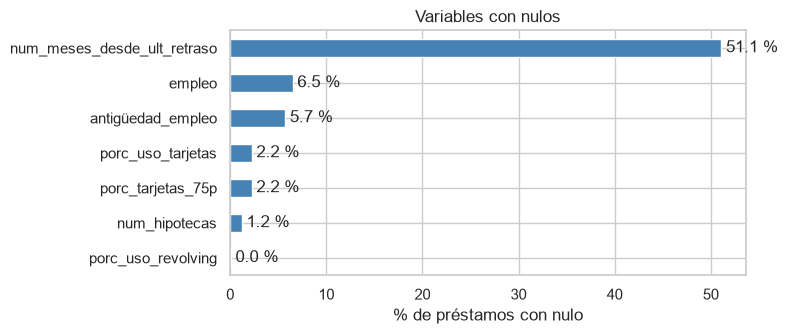

In [9]:
# Gráfico de barras horizontales con el % de nulos de cada variable
fig, ax = plt.subplots(figsize=(8, 3.5))
pct_nulos.sort_values().plot.barh(ax=ax, color='steelblue')
ax.set_xlabel('% de préstamos con nulo')
ax.set_title('Variables con nulos')
for i, valor in enumerate(pct_nulos.sort_values()):
    ax.text(valor + 0.5, i, f'{valor:.1f} %', va='center')   # etiqueta con el valor
plt.tight_layout()
plt.show()

**Qué se hace:** gráfico de barras con el % de nulos de cada variable.

**Qué se observa:** lo mismo que la tabla anterior: una variable con muchos nulos y seis con pocos.

<a id="s4-2"></a>

### 4.2 · ¿El nulo está relacionado con el impago?

Si los préstamos con nulo impagan más (o menos) que el resto, el nulo **aporta información** y conviene conservarla de alguna forma, en lugar de rellenarlo como si fuera un dato cualquiera.

In [10]:
# Para cada variable con nulos: nº de nulos y tasa de impago con y sin nulo
comparativa = pd.DataFrame({
    'n_nulos': df[pct_nulos.index].isna().sum(),
    'tasa_impago_con_nulo': [impago[df[col].isna()].mean() for col in pct_nulos.index],
    'tasa_impago_sin_nulo': [impago[df[col].notna()].mean() for col in pct_nulos.index],
}, index=pct_nulos.index)

# Diferencia en puntos porcentuales (positiva = los nulos impagan más)
comparativa['diferencia_pp'] = (comparativa['tasa_impago_con_nulo'] - comparativa['tasa_impago_sin_nulo']) * 100
comparativa

,n_nulos,tasa_impago_con_nulo,tasa_impago_sin_nulo,diferencia_pp
num_meses_desde_ult_retraso,226509,0.145,0.152,-0.729
empleo,28744,0.203,0.145,5.780
antigüedad_empleo,25320,0.206,0.145,6.150
porc_uso_tarjetas,9864,0.166,0.148,1.828
porc_tarjetas_75p,9848,0.166,0.148,1.762
num_hipotecas,5328,0.165,0.148,1.631
porc_uso_revolving,221,0.181,0.148,3.252


**Qué se hace:** para cada variable con nulos se compara la tasa de impago de los préstamos **con** nulo y **sin** nulo. Columnas: `n_nulos` (nº de préstamos con nulo); `tasa_impago_con_nulo` y `tasa_impago_sin_nulo` (proporción de impagos en cada grupo: 0,145 = 14,5 %); `diferencia_pp` (diferencia entre las dos tasas en **puntos porcentuales**: positiva = los nulos impagan más; p. ej. 20,3 % − 14,5 % = +5,8 pp).

**Qué se observa:** los nulos de `empleo` y `antigüedad_empleo` impagan **unos 6 puntos más**: el nulo tiene mucha señal. En tarjetas e hipotecas la diferencia es de +1,6 a +1,8 puntos, y en `porc_uso_revolving` de +3,3 (pero solo son 221 préstamos). En `num_meses_desde_ult_retraso`, los nulos impagan algo **menos** (−0,7): encaja con que el nulo signifique "sin retrasos".

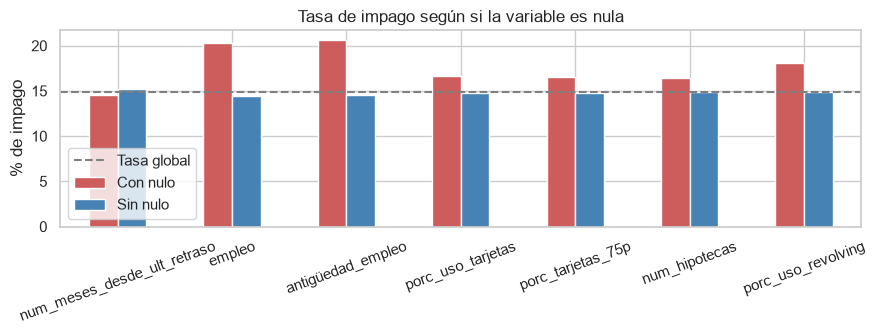

In [11]:
# Gráfico: tasa de impago con y sin nulo, comparada con la tasa global
fig, ax = plt.subplots(figsize=(9, 3.5))
comparativa[['tasa_impago_con_nulo', 'tasa_impago_sin_nulo']].mul(100).plot.bar(
    ax=ax, color=['indianred', 'steelblue'], rot=20)
ax.axhline(TASA_IMPAGO_GLOBAL * 100, color='grey', linestyle='--', label='Tasa global')  # referencia
ax.set_ylabel('% de impago')
ax.set_title('Tasa de impago según si la variable es nula')
ax.legend(['Tasa global', 'Con nulo', 'Sin nulo'])
plt.tight_layout()
plt.show()

**Qué se hace:** gráfico con la tasa de impago con nulo (rojo) y sin nulo (azul) de cada variable; la línea discontinua es la tasa global.

**Qué se observa:** las barras rojas de `empleo` y `antigüedad_empleo` destacan claramente por encima de la tasa global.

<a id="s4-3"></a>

### 4.3 · ¿Los nulos dependen del año de concesión?

En el notebook 01 se vio que algunas variables no se recogían en los primeros años. Si los nulos se concentran en un año concreto, son **estructurales** (no dependen del cliente).

In [12]:
# % de nulos por año de concesión en cada variable con nulos
anio = df['fecha_concesion'].dt.year
df[pct_nulos.index].isna().groupby(anio).mean().mul(100).round(2).T

fecha_concesion,2012,2013,2014,2015
num_meses_desde_ult_retraso,59.190,56.660,49.060,48.020
empleo,5.940,6.370,6.470,6.650
antigüedad_empleo,3.590,4.420,5.870,6.630
porc_uso_tarjetas,15.190,0.790,1.130,1.070
porc_tarjetas_75p,15.150,0.750,1.120,1.100
num_hipotecas,14.160,0.000,0.000,0.000
porc_uso_revolving,0.090,0.060,0.050,0.040


**Qué se hace:** % de nulos de cada variable por año de concesión (filas: variables; columnas: años).

**Qué se observa:** las variables de tarjetas tienen ~15 % de nulos en 2012 y ~1 % después, y `num_hipotecas` solo tiene nulos en 2012: apunta a un problema de **recogida de datos** en 2012 (se detalla en 4.4.5). `empleo` y `antigüedad_empleo` tienen nulos todos los años (~4–7 %), así que no son estructurales.

<a id="s4-4"></a>

### 4.4 · Variable a variable

Cada variable con nulos se estudia por separado, en el orden en que se corrige: primero la observación, después la decisión (recuadro **Decisión Dx**) y por último el código que la aplica.

<a id="s4-4-1"></a>

#### 4.4.1 · `num_meses_desde_ult_retraso` (D1)

**Qué es:** meses transcurridos desde el último retraso (*delinquency*) en algún pago del cliente, según su informe de crédito (original: `mths_since_last_delinq`). Está vacía cuando no hay ningún retraso registrado.

**Variable relacionada:** `num_retrasos_2anios` (`delinq_2yrs`), nº de retrasos de más de 30 días en los últimos 2 años; sirve para comprobar qué significa el nulo.

**Pregunta:** ¿qué significa que sea nulo?

In [13]:
# Retrasos en los últimos 2 años según si num_meses_desde_ult_retraso es nulo
es_nulo = df['num_meses_desde_ult_retraso'].isna()
df.groupby(es_nulo)['num_retrasos_2anios'].agg(
    media='mean',
    pct_con_algun_retraso=lambda s: (s > 0).mean() * 100,
).rename(index={False: 'con valor', True: 'nulo'})

,media,pct_con_algun_retraso
num_meses_desde_ult_retraso,,
con valor,0.639,38.920
nulo,0.011,0.524


**Qué se hace:** se compara el nº de retrasos en los últimos 2 años entre los préstamos con valor y con nulo en `num_meses_desde_ult_retraso`. `media`: retrasos medios; `pct_con_algun_retraso`: % con al menos uno.

**Qué se observa:** entre los nulos, solo el **0,5 %** tiene algún retraso en 2 años (frente al 39 % de los que tienen valor): el nulo significa **"sin retraso registrado"**.

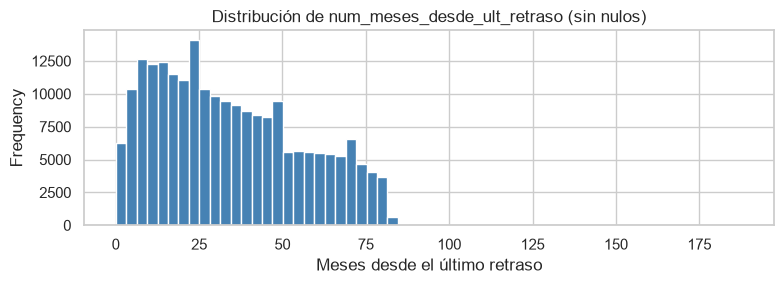

Préstamos con valor 0: 451


In [14]:
# Distribución de los valores no nulos (¿hay muchos ceros?)
fig, ax = plt.subplots(figsize=(8, 3))
df['num_meses_desde_ult_retraso'].dropna().plot.hist(bins=60, ax=ax, color='steelblue')
ax.set_xlabel('Meses desde el último retraso')
ax.set_title('Distribución de num_meses_desde_ult_retraso (sin nulos)')
plt.tight_layout()
plt.show()

print(f"Préstamos con valor 0: {(df['num_meses_desde_ult_retraso'] == 0).sum():,}")

**Qué se hace:** histograma de los meses desde el último retraso (sin los nulos) y nº de préstamos con valor 0.

**Qué se observa:** los valores se reparten entre 0 y unos 84 meses y casi desaparecen a partir de ahí. Solo 451 préstamos tienen un retraso en el mismo mes (valor 0).

In [15]:
# Rango de valores: mínimo, máximo y percentiles (los nulos no cuentan)
df['num_meses_desde_ult_retraso'].describe(percentiles=[.01, .25, .5, .75, .95, .99, .999])

count   216960.000
mean        34.135
std         21.790
min          0.000
1%           2.000
25%         16.000
50%         31.000
75%         50.000
95%         74.000
99%         80.000
99.9%       88.000
max        188.000
Name: num_meses_desde_ult_retraso, dtype: float64

**Qué se hace:** estadísticos de la variable: media, mínimo, máximo y percentiles (el valor por debajo del cual queda ese % de préstamos).

**Qué se observa:** mediana de **31 meses**; el 99 % está por debajo de 80 meses, pero el máximo llega a 188.

In [16]:
# Cola derecha: ¿cuántos préstamos superan cada límite? (84 meses = 7 años)
for limite in [80, 84, 100, 120]:
    print(f"Más de {limite} meses: {(df['num_meses_desde_ult_retraso'] > limite).sum():,}")

Más de 80 meses: 2,038
Más de 84 meses: 289
Más de 100 meses: 92
Más de 120 meses: 32


**Qué se hace:** se cuentan los préstamos por encima de varios límites (84 meses = 7 años).

**Qué se observa:** solo **289** superan los 84 meses. Encaja con que los retrasos desaparecen del informe de crédito a los 7 años.

In [17]:
# Tasa de impago por tramos finos de meses desde el último retraso (incluyendo el nulo como tramo)
tramos_finos = pd.cut(df['num_meses_desde_ult_retraso'],
                      bins=[-1, 0, 6, 12, 24, 36, 48, 60, 72, 84, 200],
                      labels=['0', '1-6', '7-12', '13-24', '25-36', '37-48', '49-60', '61-72', '73-84', '>84'])
tramos_finos = tramos_finos.cat.add_categories('nulo').fillna('nulo')
pd.DataFrame({
    'n_prestamos': tramos_finos.value_counts(sort=False),
    'tasa_impago': impago.groupby(tramos_finos, observed=False).mean(),
})

,n_prestamos,tasa_impago
num_meses_desde_ult_retraso,,
0,451,0.140
1-6,16183,0.157
7-12,24934,0.159
13-24,45512,0.152
25-36,39378,0.148
37-48,33568,0.147
49-60,22769,0.152
61-72,20844,0.159
73-84,13032,0.149


**Qué se hace:** tasa de impago por tramos finos de meses, incluyendo el nulo como un tramo más.

**Qué se observa:** la tasa de impago apenas cambia entre tramos (del 14 % al 17 %) y el nulo está en el 14,5 %: la variable tiene **poca señal**.

**Coherencia con `num_retrasos_2anios`** (retrasos en los últimos 24 meses): si el nulo significa "sin retraso", los nulos deberían tener 0 retrasos en 2 años; y quien se retrasó hace menos de 24 meses debería tener al menos 1.

In [18]:
# Nulos frente a retrasos en los últimos 2 años
pd.crosstab(
    es_nulo.map({True: 'nulo', False: 'con valor'}),
    df['num_retrasos_2anios'] > 0,
    rownames=['num_meses_desde_ult_retraso'],
    colnames=['¿retrasos en los últimos 2 años?'],
)

¿retrasos en los últimos 2 años?,False,True
num_meses_desde_ult_retraso,,
con valor,132520,84440
nulo,225322,1187


**Qué se hace:** tabla cruzada: nulo o con valor frente a si hubo retrasos en los últimos 2 años.

**Qué se observa:** de los 226.509 nulos, **225.322 no tienen retrasos** en 2 años y **1.187 sí** (0,5 %): esos pocos son incoherentes con un "sin retraso".

In [19]:
# Préstamos con valor: % con retrasos en 2 años según si el último retraso fue hace menos de 24 meses
con_valor = df[~es_nulo]
reciente = con_valor['num_meses_desde_ult_retraso'] < 24
(con_valor['num_retrasos_2anios'] > 0).groupby(reciente).mean().mul(100) \
    .rename(index={True: 'menos de 24 meses', False: '24 meses o más'}) \
    .to_frame('% con retrasos en 2 años')

,% con retrasos en 2 años
num_meses_desde_ult_retraso,
24 meses o más,0.655
menos de 24 meses,99.944


**Qué se hace:** entre los préstamos con valor, % con retrasos en 2 años según si el último retraso fue hace menos de 24 meses.

**Qué se observa:** si el último retraso fue hace menos de 24 meses, el **99,9 %** tiene retrasos en 2 años; si fue hace más, solo el 0,7 %. Las dos variables son coherentes entre sí.

> **Decisión D1 · Convertir `num_meses_desde_ult_retraso` en 4 tramos: `sin_retraso`, `0-24`, `25-48` y `>48`.**
> - **Qué significa el nulo:** que no hay ningún retraso registrado. Más del 99 % de los nulos tiene 0 retrasos en los últimos 2 años. Matiz: los retrasos desaparecen del informe de crédito a los 7 años (84 meses, justo donde se corta la distribución), así que significa "sin retraso **registrado**", no "nunca en su vida".
> - **Por qué tramos:** ningún número de meses representa "sin retraso". Imputar 0 diría lo contrario (un retraso este mes) e imputar un valor extremo (p. ej. 999) inventaría un dato.
> - **Asignación:**
>   - Préstamos con valor → el tramo que corresponde a sus meses.
>   - Nulo y 0 retrasos en 2 años → `sin_retraso`.
>   - Nulo **con** retrasos en 2 años (incoherencia, en torno al 0,5 % de los nulos) → `0-24`, porque `num_retrasos_2anios` demuestra que hubo un retraso en los últimos 24 meses.
> - **Cortes:** 24 es la ventana de `num_retrasos_2anios`. 48 divide el resto en dos grupos de tamaño parecido (corte arbitrario). El último tramo es abierto (`>48`), así que recoge también la cola de más de 84 meses sin necesidad de acotarla.
> - **A tener en cuenta:** el impago apenas cambia entre tramos (entre el 14 % y el 16 %), así que probablemente sea una variable poco predictiva. Se comprobará en el EDA.
> - **En producción:** la función `tramo_ultimo_retraso` se aplicará igual en validación y en la API.

In [20]:
def tramo_ultimo_retraso(meses, retrasos_2anios):
    '''Asigna el tramo de meses desde el último retraso (decisión D1).

    meses           : Serie con num_meses_desde_ult_retraso (NaN = sin retraso registrado)
    retrasos_2anios : Serie con num_retrasos_2anios (retrasos en los últimos 24 meses)
    Devuelve una variable categórica ordenada con los tramos.
    '''
    # Condiciones en orden: np.select asigna la PRIMERA que se cumple en cada fila
    condiciones = [
        meses.isna() & (retrasos_2anios == 0),   # sin retraso registrado
        meses.isna() & (retrasos_2anios > 0),    # nulo incoherente: hubo retraso en los últimos 24 meses
        meses <= 24,                             # retraso reciente
        meses <= 48,                             # retraso intermedio
        meses > 48,                              # retraso antiguo (incluye la cola de >84 meses)
    ]
    tramos = ['sin_retraso', '0-24', '0-24', '25-48', '>48']
    # Filas sin ninguna condición (p. ej. ambos datos vacíos) -> texto vacío -> NaN en la categórica
    resultado = np.select(condiciones, tramos, default='')
    return pd.Categorical(resultado, categories=['sin_retraso', '0-24', '25-48', '>48'], ordered=True)

In [21]:
# Crear la nueva variable a partir de la original
df['tramo_ult_retraso'] = tramo_ultimo_retraso(df['num_meses_desde_ult_retraso'], df['num_retrasos_2anios'])

# Comprobación: todos los préstamos tienen tramo
assert df['tramo_ult_retraso'].notna().all(), "Hay préstamos sin tramo asignado"

# Préstamos y tasa de impago por tramo
pd.DataFrame({
    'n_prestamos': df['tramo_ult_retraso'].value_counts(sort=False),
    'tasa_impago': impago.groupby(df['tramo_ult_retraso'], observed=False).mean(),
})

,n_prestamos,tasa_impago
tramo_ult_retraso,,
sin_retraso,225322,0.145
0-24,88267,0.155
25-48,72946,0.148
>48,56934,0.154


**Qué se hace:** se crea `tramo_ult_retraso` con la función de D1, se comprueba que todos los préstamos tienen tramo y se muestra el impago por tramo.

**Qué se observa:** 225.322 préstamos `sin_retraso` y el resto repartidos en los otros tres tramos. El impago va del 14,5 % al 15,5 %: confirma que es una variable débil.

In [22]:
# Eliminar la variable original: su información ya está recogida en el tramo
df = df.drop(columns='num_meses_desde_ult_retraso')
print(f"Columnas: {df.shape[1]}")

Columnas: 34


**Qué se hace:** se elimina la variable original, ya recogida en el tramo.

**Qué se observa:** siguen siendo **34 columnas** (entra `tramo_ult_retraso` y sale `num_meses_desde_ult_retraso`).

<a id="s4-4-2"></a>

#### 4.4.2 · `antigüedad_empleo` (D2)

**Qué es:** años que el cliente lleva en su empleo actual, declarados en la solicitud (original: `emp_length`). Es texto con 11 categorías: `< 1 year`, `1 year`, `2 years` … `9 years` y `10+ years`.

In [23]:
# Préstamos y tasa de impago por categoría (incluido el nulo)
categoria = df['antigüedad_empleo'].fillna('NULO')
pd.DataFrame({
    'n_prestamos': categoria.value_counts(),
    'tasa_impago': impago.groupby(categoria).mean(),
}).sort_values('tasa_impago', ascending=False)

,n_prestamos,tasa_impago
antigüedad_empleo,,
NULO,25320,0.206
< 1 year,35187,0.154
1 year,28617,0.153
9 years,17113,0.150
7 years,22568,0.149
6 years,21745,0.149
8 years,21938,0.148
5 years,28218,0.148
2 years,39898,0.147


**Qué se hace:** nº de préstamos y tasa de impago de cada categoría de antigüedad, con el nulo como una categoría más.

**Qué se observa:** el nulo tiene el impago **más alto (20,6 %)**; `10+ years`, el más bajo (13,7 %); entre 1 y 9 años el impago apenas cambia (~15 %).

**¿Coincide con el nulo de `empleo`?** Si casi siempre van juntos, el nulo no es un dato perdido al azar, sino un cliente que **no declaró ningún empleo**.

In [24]:
# Cruce de nulos: antigüedad del empleo frente a empleo
nulo_antiguedad = df['antigüedad_empleo'].isna()
nulo_empleo = df['empleo'].isna()
pd.crosstab(
    nulo_antiguedad.map({True: 'antigüedad nula', False: 'antigüedad con valor'}),
    nulo_empleo.map({True: 'empleo nulo', False: 'empleo con valor'}),
    margins=True, margins_name='Total',
)

empleo,empleo con valor,empleo nulo,Total
antigüedad_empleo,,,
antigüedad con valor,414528,3621,418149
antigüedad nula,197,25123,25320
Total,414725,28744,443469


**Qué se hace:** tabla cruzada de los nulos de `antigüedad_empleo` y de `empleo`.

**Qué se observa:** **25.123** préstamos tienen nulas las dos variables; solo 197 tienen nula únicamente la antigüedad. Es decir, ~99 % de los nulos de antigüedad son también nulos de empleo.

In [25]:
# Préstamos y tasa de impago de cada combinación de nulos
combinacion = pd.Series(
    np.select(
        [nulo_antiguedad & nulo_empleo, nulo_antiguedad & ~nulo_empleo, ~nulo_antiguedad & nulo_empleo],
        ['ambos nulos', 'solo antigüedad nula', 'solo empleo nulo'],
        default='ambos con valor',
    ),
    index=df.index,
)
pd.DataFrame({
    'n_prestamos': combinacion.value_counts(),
    'tasa_impago': impago.groupby(combinacion).mean(),
})

,n_prestamos,tasa_impago
ambos con valor,414528,0.145
ambos nulos,25123,0.207
solo antigüedad nula,197,0.198
solo empleo nulo,3621,0.175


**Qué se hace:** nº de préstamos y tasa de impago de cada combinación de nulos.

**Qué se observa:** cuando faltan los dos datos, el impago es del **20,7 %**, frente al 14,5 % de quienes declaran ambos.

**¿Qué perfil tienen los clientes con la antigüedad nula?**

In [26]:
# Medianas de ingresos, DTI, FICO y tipo de interés según si la antigüedad es nula
df.groupby(nulo_antiguedad).agg(
    ingresos=('ingresos', 'median'),
    dti=('dti', 'median'),
    fico=('fico_min', 'median'),
    tipo_interes=('tipo_interes', 'median'),
).rename(index={False: 'con valor', True: 'nula'})

,ingresos,dti,fico,tipo_interes
antigüedad_empleo,,,,
con valor,63000.000,17.210,685.000,12.290
nula,42000.000,19.100,685.000,12.690


**Qué se hace:** medianas de ingresos, DTI, FICO y tipo de interés según si la antigüedad es nula.

**Qué se observa:** los clientes con nulo tienen **ingresos mucho más bajos** (42.000 frente a 63.000) y algo más de DTI; el FICO es el mismo.

In [27]:
# % de préstamos con ingresos verificados y con vivienda en propiedad según si la antigüedad es nula
pd.DataFrame({
    '% ingresos verificados': df['ingresos_verificados'].eq('Verified').groupby(nulo_antiguedad).mean() * 100,
    '% vivienda en propiedad': df['vivienda'].eq('OWN').groupby(nulo_antiguedad).mean() * 100,
}).rename(index={False: 'con valor', True: 'nula'})

,% ingresos verificados,% vivienda en propiedad
antigüedad_empleo,,
con valor,30.905,9.466
nula,71.430,19.483


**Qué se hace:** % de préstamos con ingresos verificados y con vivienda en propiedad según si la antigüedad es nula.

**Qué se observa:** a los clientes con nulo Lending Club les **verifica los ingresos mucho más** (71 % frente a 31 %) y tienen el doble de vivienda en propiedad (19 % frente a 9 %).

In [28]:
# ¿Es un nulo estructural? % de nulos por año de concesión
nulo_antiguedad.groupby(df['fecha_concesion'].dt.year).mean().mul(100).round(1).to_frame('% nulos')

,% nulos
fecha_concesion,
2012,3.600
2013,4.400
2014,5.900
2015,6.600


**Qué se hace:** % de nulos de antigüedad por año de concesión, para ver si es un nulo estructural.

**Observaciones:**
- Casi todos los nulos de `antigüedad_empleo` (en torno al 99 %) son también nulos de `empleo`: el cliente **no declaró ningún empleo**.
- Es el grupo con **más impago**, en torno al 21 % frente al 14,5 % de los que declaran ambos datos.
- Su perfil es distinto: **ingresos más bajos** (mediana de unos 42.000 frente a 63.000), un DTI algo mayor, el doble de **vivienda en propiedad** (en torno al 20 % frente al 10 %) y Lending Club **verifica sus ingresos mucho más a menudo** (en torno al 72 % frente al 31 %). La puntuación FICO es la misma.
- Este perfil encaja con **jubilados, desempleados o personas con ingresos que no proceden de un empleo** (pensiones, alquileres...). Es una hipótesis coherente con los datos, aunque estos no permiten confirmarla del todo.
- No es un nulo estructural: está presente todos los años (entre el 3,5 % y el 7 %).
- Entre los que declaran antigüedad, el impago apenas cambia de 1 a 9 años, y `10+ years` es la categoría con menos impago.

> **Decisión D2 · Sustituir el nulo de `antigüedad_empleo` por una categoría propia: `sin_empleo_declarado`.**
> - **Por qué:** el nulo identifica a un grupo con un perfil propio y el mayor riesgo de impago. Una categoría propia conserva esa señal y describe lo que realmente ocurre.
> - **Alternativas descartadas:**
>   - Imputar con la moda (`10+ years`): asignaría la categoría de **menos** riesgo al grupo de **más** riesgo.
>   - Convertirla a número (0–10) con un indicador de nulo: funciona, pero usa dos columnas para lo que una categoría expresa sola.
> - **Consecuencia para `empleo`:** como su nulo casi coincide con este, la señal de riesgo de "no declarar empleo" queda recogida aquí (se tendrá en cuenta al decidir sobre `empleo`).
> - **Pendiente para el EDA:** valorar si conviene agrupar las categorías de 1 a 9 años, que se comportan de forma muy parecida.
> - **En producción:** en el formulario de la demo será una opción más del desplegable.

In [29]:
# Categoría para los clientes que no declaran empleo (se reutilizará en validación y en la API)
CATEGORIA_SIN_EMPLEO = 'sin_empleo_declarado'

# Sustituir el nulo por la categoría propia
df['antigüedad_empleo'] = df['antigüedad_empleo'].fillna(CATEGORIA_SIN_EMPLEO)

# Comprobación: ya no quedan nulos
assert df['antigüedad_empleo'].notna().all(), "Quedan nulos en antigüedad_empleo"

# Préstamos y tasa de impago por categoría tras la corrección
pd.DataFrame({
    'n_prestamos': df['antigüedad_empleo'].value_counts(),
    'tasa_impago': impago.groupby(df['antigüedad_empleo']).mean(),
}).sort_values('tasa_impago', ascending=False)

,n_prestamos,tasa_impago
antigüedad_empleo,,
sin_empleo_declarado,25320,0.206
< 1 year,35187,0.154
1 year,28617,0.153
9 years,17113,0.150
7 years,22568,0.149
6 years,21745,0.149
8 years,21938,0.148
5 years,28218,0.148
2 years,39898,0.147


**Qué se hace:** se sustituye el nulo por la categoría `sin_empleo_declarado`, se comprueba que no quedan nulos y se muestra el impago por categoría.

**Qué se observa:** la nueva categoría tiene 25.320 préstamos y el impago más alto (20,6 %), igual que el nulo antes de la corrección.

<a id="s4-4-3"></a>

#### 4.4.3 · `empleo` (D3)

**Qué es:** puesto de trabajo que el cliente escribe en la solicitud (original: `emp_title`), como texto libre: *"RN"*, *"Teacher"*, *"Software Engineer"*…

Texto libre escrito por el cliente. Su nulo ya está recogido en `sin_empleo_declarado` (D2). La pregunta es si la **profesión** aporta información sobre el riesgo y si se puede agrupar en algo utilizable.

In [30]:
def normalizar_empleo(empleo):
    '''Pasa a minúsculas, sustituye signos de puntuación por espacios y quita espacios sobrantes.
    Así 'RN', 'rn' y ' R.N. ' se tratan igual.'''
    return (empleo.str.lower()
                  .str.replace(r'[^a-z0-9]+', ' ', regex=True)   # todo lo que no sea letra o número -> espacio
                  .str.strip())

empleo_norm = normalizar_empleo(df['empleo'])
print(f"Valores distintos (texto original):   {df['empleo'].nunique():,}")
print(f"Valores distintos (texto normalizado): {empleo_norm.nunique():,}")

Valores distintos (texto original):   170,605
Valores distintos (texto normalizado): 140,870


**Qué se hace:** se define una función que normaliza el texto del empleo (minúsculas, sin signos de puntuación) y se cuenta cuántos valores distintos hay antes y después.

**Qué se observa:** normalizar reduce los valores distintos de 170.605 a **140.870**: sigue siendo un texto muy disperso.

In [31]:
# Concentración: qué % de los préstamos (con empleo declarado) cubren los títulos más frecuentes
frecuencias = empleo_norm.value_counts()
total_declarado = frecuencias.sum()
for n in [10, 50, 100, 500, 1000]:
    print(f"Top {n:>5} títulos: {frecuencias.head(n).sum() / total_declarado:.1%} de los préstamos")

# Títulos que aparecen una sola vez (la "cola larga")
unicos = (frecuencias == 1).sum()
print(f"\nTítulos que aparecen una sola vez: {unicos:,} ({unicos / total_declarado:.1%} de los préstamos)")

Top    10 títulos: 10.1% de los préstamos
Top    50 títulos: 19.6% de los préstamos
Top   100 títulos: 24.7% de los préstamos
Top   500 títulos: 38.9% de los préstamos
Top  1000 títulos: 44.7% de los préstamos

Títulos que aparecen una sola vez: 114,277 (27.6% de los préstamos)


**Qué se hace:** se calcula qué % de los préstamos (con empleo declarado) cubren los títulos más frecuentes y cuántos títulos aparecen una sola vez.

**Qué se observa:** los 100 títulos más frecuentes solo cubren el **24,7 %** de los préstamos, y el **27,6 %** tiene un título que no se repite.

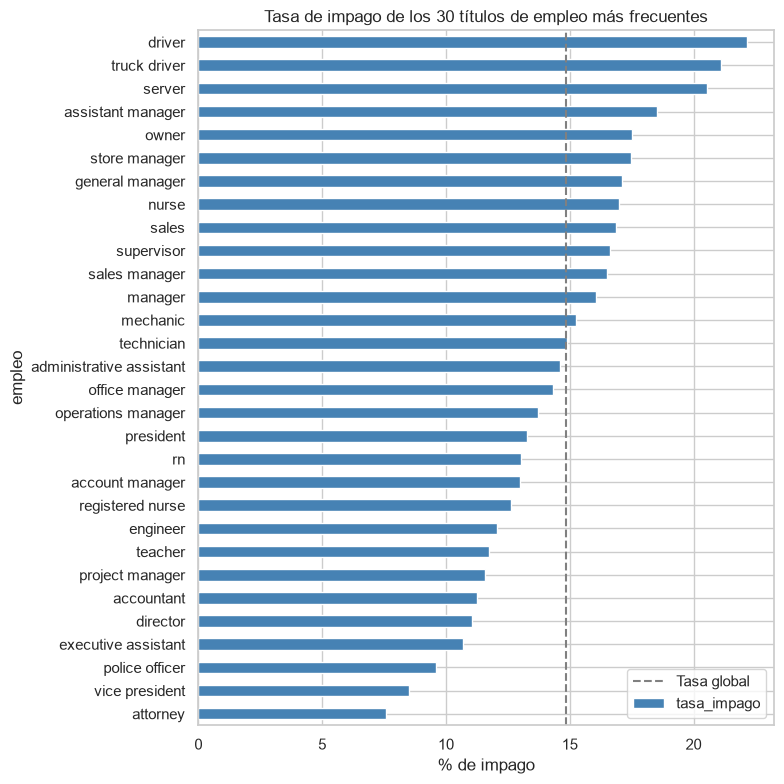

In [32]:
# Tasa de impago de los 30 títulos más frecuentes
top_titulos = frecuencias.head(30).index
tabla_titulos = pd.DataFrame({
    'n_prestamos': frecuencias.head(30),
    'tasa_impago': impago.groupby(empleo_norm).mean().loc[top_titulos],
}).sort_values('tasa_impago')

# Gráfico de barras horizontales con la tasa global como referencia
fig, ax = plt.subplots(figsize=(8, 8))
tabla_titulos['tasa_impago'].mul(100).plot.barh(ax=ax, color='steelblue')
ax.axvline(TASA_IMPAGO_GLOBAL * 100, color='grey', linestyle='--', label='Tasa global')
ax.set_xlabel('% de impago')
ax.set_title('Tasa de impago de los 30 títulos de empleo más frecuentes')
ax.legend()
plt.tight_layout()
plt.show()

**Qué se hace:** gráfico con la tasa de impago de los 30 títulos de empleo más frecuentes; la línea discontinua es la tasa global.

**Observaciones:**
- Hay **señal real**: entre los títulos frecuentes, el impago va aproximadamente del 7 % (abogados) al 22 % (camareros), cuando la media es del 15 %.
- Pero el texto está muy disperso: los 100 títulos más frecuentes solo cubren en torno a un 25 % de los préstamos, y casi un 30 % de los préstamos tiene un título que no se repite. Como variable tal cual es inutilizable.
- **Idea:** agrupar los títulos en **sectores** para conservar la señal con un número manejable de categorías.

##### Agrupación por sector · primera versión de las reglas

- **Método:** reglas de palabras clave (expresiones regulares) evaluadas **en orden**: cada título se asigna al **primer** sector cuya regla coincide. Por eso las reglas específicas van antes que las generales (por ejemplo, *nurse manager* debe ir a salud y no a dirección).
- **Por qué reglas y no técnicas de NLP más complejas:** son transparentes, se pueden revisar una a una y se aplican igual en la API.
- Los nulos van a `sin_empleo_declarado` (coherente con D2) y lo que no encaja en ninguna regla, a `otros`.

In [33]:
# Reglas por sector, en orden de prioridad: gana la PRIMERA que coincide
REGLAS_SECTOR = [
    ('salud',                r'nurse|\brn\b|\blpn\b|\bcna\b|doctor|physician|medical|dental|dentist|pharm|therap|hospital|health|clinic|surgeon|paramedic|\bemt\b|radiolog|caregiver|patient|optometr|veterinar'),
    ('educacion',            r'teacher|professor|school|educat|instructor|tutor|principal|faculty|universit|college|librar'),
    ('legal',                r'attorney|lawyer|paralegal|legal|\bcounsel\b|law clerk|judge'),
    ('seguridad_publica',    r'police|sheriff|deputy|correction|firefight|military|\barmy\b|\bnavy\b|air force|marine|usps|postal|letter carrier|mail carrier|federal|government|state of|county|city of|security guard|security officer|soldier|sergeant|trooper'),
    ('transporte',           r'driver|truck|transport|pilot|logistic|courier|delivery|\bbus\b|dispatch|flight attendant|airline|railroad|conductor'),
    ('hosteleria',           r'^server$|waiter|waitress|bartender|\bcook\b|\bchef\b|restaurant|hotel|barista|food service|dishwasher|housekeep|casino|hospitality'),
    ('finanzas',             r'accountant|accounting|bookkeep|\bbank|financ|teller|\bloan|underwrit|audit|\btax\b|insurance|controller|\bcpa\b|payroll|actuar|credit analyst|accounts payable|accounts receivable|mortgage|investment'),
    ('tecnologia',           r'engineer|developer|software|programmer|\bit\b|network|systems|database|\bdata (?!entry)|\bweb\b|technology|computer|devops|architect'),
    ('comercio',             r'sales|retail|cashier|store|merchand|customer service|account manager|account executive|realtor|real estate|\bbuyer\b|\bcsr\b|walmart|target|costco|home depot|lowe'),
    ('oficios_industria',    r'mechanic|electrician|plumb|carpenter|welder|construction|machinist|maintenance|operator|laborer|warehouse|technician|\btech\b|installer|hvac|painter|foreman|custodian|janitor|landscap|assembl|production|forklift|material handler|lineman|superintendent|inspector'),
    ('autonomo_propietario', r'owner|self employed|selfemployed|proprietor|founder|\bpartner\b|entrepreneur'),
    ('administrativo',       r'admin|assistant|secretary|clerk|receptionist|office|coordinator|data entry|specialist|analyst|representative|associate|processor'),
    ('direccion_gestion',    r'manager|director|supervisor|president|\bceo\b|\bcfo\b|\bcoo\b|\bvp\b|executive|chief|management|team lead|consultant'),
]

def sector_empleo(empleo):
    '''Asigna un sector a cada título de empleo según REGLAS_SECTOR.

    empleo : Serie con el texto original del empleo (NaN = no declarado)
    '''
    texto = normalizar_empleo(empleo).fillna('')
    # Una condición por regla; np.select asigna el sector de la PRIMERA que se cumple
    condiciones = [texto.str.contains(patron, regex=True) for _, patron in REGLAS_SECTOR]
    sectores = [sector for sector, _ in REGLAS_SECTOR]
    resultado = np.select(condiciones, sectores, default='otros')
    # Los nulos van a la misma categoría que en antigüedad_empleo (D2)
    resultado = np.where(empleo.isna(), CATEGORIA_SIN_EMPLEO, resultado)
    return pd.Series(resultado, index=empleo.index)

# Aplicar (todavía como variable de análisis, sin modificar df)
sector = sector_empleo(df['empleo'])

In [34]:
# Préstamos, % y tasa de impago por sector
tabla_sector = pd.DataFrame({
    'n_prestamos': sector.value_counts(),
    'tasa_impago': impago.groupby(sector).mean(),
})
tabla_sector['% prestamos'] = tabla_sector['n_prestamos'] / len(df) * 100
cobertura = 1 - (sector == 'otros').sum() / df['empleo'].notna().sum()
print(f"Cobertura (préstamos con empleo declarado asignados a un sector): {cobertura:.1%}")
tabla_sector.sort_values('tasa_impago')

Cobertura (préstamos con empleo declarado asignados a un sector): 73.3%


,n_prestamos,tasa_impago,% prestamos
tecnologia,22985,0.096,5.183
legal,4523,0.106,1.020
educacion,22025,0.123,4.967
finanzas,21400,0.123,4.826
direccion_gestion,60351,0.131,13.609
administrativo,44036,0.137,9.930
salud,34487,0.143,7.777
seguridad_publica,14526,0.143,3.276
otros,110849,0.158,24.996
comercio,23234,0.160,5.239


**Qué se hace:** se agrupan los títulos en sectores con las reglas (primera versión) y se calcula el nº de préstamos, el % y la tasa de impago de cada sector. `Cobertura`: % de quienes declaran empleo que quedan asignados a algún sector (no a `otros`).

**Qué se observa:** cobertura del **73,3 %**. El impago va del **9,6 % (tecnología)** al **20,3 % (sin empleo declarado)**; `otros` reúne el 25 % de los préstamos.

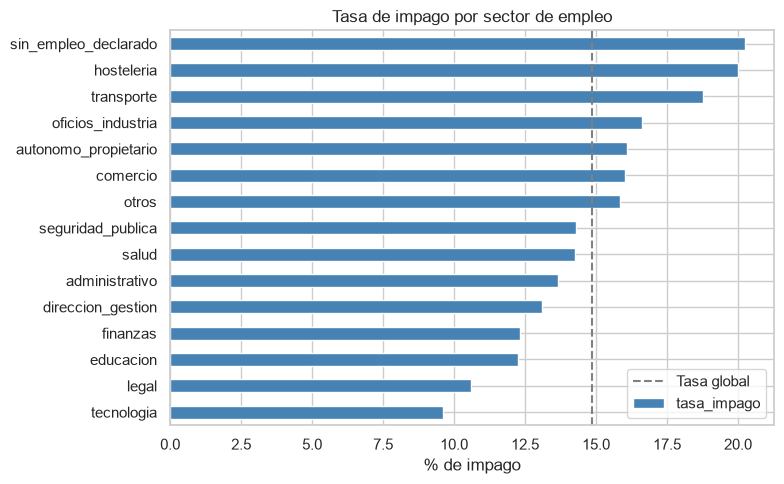

In [35]:
# Gráfico: tasa de impago por sector frente a la tasa global
fig, ax = plt.subplots(figsize=(8, 5))
tabla_sector['tasa_impago'].sort_values().mul(100).plot.barh(ax=ax, color='steelblue')
ax.axvline(TASA_IMPAGO_GLOBAL * 100, color='grey', linestyle='--', label='Tasa global')
ax.set_xlabel('% de impago')
ax.set_title('Tasa de impago por sector de empleo')
ax.legend()
plt.tight_layout()
plt.show()

**Qué se hace:** gráfico de la tasa de impago por sector frente a la tasa global.

**Qué se observa:** hay sectores claramente por debajo (tecnología, legal, educación, finanzas) y por encima (transporte, hostelería, sin empleo declarado).

**¿El sector aporta algo más allá del rating?** Si dentro de un mismo rating el impago sigue cambiando según el sector, el sector contiene información que el rating no recoge.

In [36]:
# % de impago por sector dentro de cada rating (A-D concentran la mayoría de préstamos)
impago.groupby([sector, df['rating']]).mean().mul(100).unstack()[['A', 'B', 'C', 'D']] \
      .sort_values('B').round(1)

rating,A,B,C,D
tecnologia,3.500,8.100,14.100,18.700
finanzas,4.200,9.100,16.200,20.400
legal,3.800,9.100,15.300,22.500
educacion,4.500,9.400,15.900,21.200
seguridad_publica,4.700,9.900,16.300,22.200
administrativo,5.300,10.200,17.000,23.000
direccion_gestion,4.900,10.700,17.900,23.000
salud,5.600,11.400,16.800,22.600
otros,5.600,11.500,18.600,23.800
comercio,6.700,11.900,19.800,27.200


**Qué se hace:** % de impago de cada sector **dentro de cada rating** (A–D, los más frecuentes).

**Qué se observa:** dentro del mismo rating el orden se mantiene. Por ejemplo, en el rating B el impago va del 8,1 % (tecnología) al 16,0 % (hostelería): el sector aporta información que el rating no recoge.

##### Revisión de las reglas

Para comprobar que la asignación tiene sentido: los títulos más frecuentes de cada sector y los que quedan en `otros`.

In [37]:
# Los 8 títulos más frecuentes de cada sector (se amplía el ancho de columna para leerlos enteros)
pd.set_option('display.max_colwidth', 200)
pd.Series({
    s: ', '.join(f"{titulo} ({n})" for titulo, n in empleo_norm[sector == s].value_counts().head(8).items())
    for s in tabla_sector.sort_values('tasa_impago').index if s not in ('otros', CATEGORIA_SIN_EMPLEO)
}).to_frame('títulos más frecuentes')

,títulos más frecuentes
tecnologia,"engineer (1492), software engineer (794), it manager (474), software developer (304), it specialist (272), network engineer (269), systems engineer (257), senior software engineer (250)"
legal,"attorney (1201), paralegal (734), legal assistant (486), legal secretary (330), associate attorney (107), lawyer (56), staff attorney (45), senior paralegal (41)"
educacion,"teacher (8270), professor (567), principal (522), instructor (381), assistant professor (304), assistant principal (267), educator (221), associate professor (189)"
finanzas,"accountant (1200), controller (654), bookkeeper (439), financial advisor (424), financial analyst (411), accounting manager (356), accounting (340), finance manager (338)"
direccion_gestion,"manager (7377), supervisor (3544), project manager (2196), general manager (2121), director (1731), president (1667), vice president (1315), operations manager (1238)"
administrativo,"office manager (2474), administrative assistant (1294), assistant manager (1026), executive assistant (881), analyst (827), clerk (659), administrator (620), secretary (559)"
salud,"registered nurse (3973), rn (3046), nurse (1155), cna (545), medical assistant (523), physician (517), lpn (517), pharmacist (461)"
seguridad_publica,"police officer (1165), us army (519), security officer (437), correctional officer (419), firefighter (316), letter carrier (312), usps (281), deputy sheriff (265)"
comercio,"sales (3198), sales manager (1362), store manager (1189), account manager (1055), customer service (850), account executive (635), sales associate (567), cashier (562)"
autonomo_propietario,"owner (4520), partner (331), managing partner (123), co owner (102), owner president (81), owner manager (60), president owner (54), sole proprietor (51)"


**Qué se hace:** se muestran los 8 títulos más frecuentes de cada sector para revisar que la asignación tiene sentido.

**Qué se observa:** en general las asignaciones son correctas, pero aparece *assistant manager* en `administrativo` (ver la revisión de abajo).

In [38]:
# Los 30 títulos más frecuentes que no encajan en ninguna regla
empleo_norm[sector == 'otros'].value_counts().head(30)

empleo
social worker                  444
counselor                      337
agent                          331
pastor                         270
at t                           255
security                       238
recruiter                      233
designer                       231
kaiser permanente              230
captain                        220
graphic designer               207
ups                            202
investigator                   200
estimator                      196
gm                             184
usaf                           178
marketing                      170
wells fargo                    166
service advisor                158
labor                          156
lvn                            156
clerical                       153
human resources                148
department of defense          145
claims adjuster                144
speech language pathologist    140
detective                      137
operations                     135
stylist      

**Qué se hace:** se muestran los 30 títulos más frecuentes que no encajan en ninguna regla (sector `otros`).

**Resultado de la revisión:**
- **Error detectado:** *assistant manager* cae en `administrativo` por la palabra *assistant*, pero suele ser un mando intermedio (por ejemplo, de tienda) → debe ir a `direccion_gestion`.
- **Títulos frecuentes de `otros` que encajan claramente en un sector existente:** *lvn* y *phlebotomist* (salud); *usaf*, *department of defense* y *detective* (seguridad pública); *recruiter*, *human resources* y *clerical* (administrativo); *claims adjuster* (finanzas); *labor*, *forman* (errata de *foreman*) y *estimator* (oficios).
- **Se dejan en `otros` a propósito:**
  - Servicios sociales (*social worker*, *counselor*, *pastor*) y marketing/diseño (*designer*, *marketing*): no se crean sectores nuevos para mantener la lista compacta.
  - Nombres de empresa (*AT&T*, *Kaiser Permanente*, *Wells Fargo*, *UPS*...): dicen dónde trabaja el cliente, pero no qué hace.

##### Agrupación por sector · segunda versión de las reglas

In [39]:
# Cobertura de la primera versión (para comparar)
cobertura_v1 = cobertura

# Ajustes tras la revisión: palabras clave que se añaden a cada sector
AJUSTES_SECTOR = {
    'salud':             r'|\blvn\b|phlebotom',
    'seguridad_publica': r'|\busaf\b|department of defense|detective',
    'finanzas':          r'|adjuster',
    'oficios_industria': r'|\blabor\b|\bforman\b|estimator',
    'administrativo':    r'|recruit|human resources|\bhr\b|clerical',
}
REGLAS_SECTOR = [(s, patron + AJUSTES_SECTOR.get(s, '')) for s, patron in REGLAS_SECTOR]

# Corrección del error: en 'administrativo', 'assistant' solo cuenta si NO va seguido de 'manager'
# (?!.*manager) es una "búsqueda negativa": la coincidencia falla si más adelante aparece 'manager'
REGLAS_SECTOR = [(s, patron.replace('assistant', r'assistant(?!.*manager)') if s == 'administrativo' else patron)
                 for s, patron in REGLAS_SECTOR]

# Volver a asignar con las reglas corregidas
sector = sector_empleo(df['empleo'])
cobertura = 1 - (sector == 'otros').sum() / df['empleo'].notna().sum()
print(f"Cobertura: {cobertura_v1:.1%} (primera versión) -> {cobertura:.1%} (segunda versión)")

# Comprobación del error corregido
print(f"'assistant manager' ahora va a: {sector[empleo_norm == 'assistant manager'].unique()}")

Cobertura: 73.3% (primera versión) -> 74.0% (segunda versión)
'assistant manager' ahora va a: <StringArray>
['direccion_gestion']
Length: 1, dtype: str


**Qué se hace:** se añaden palabras clave a algunos sectores, se corrige la regla de *assistant manager* y se vuelve a asignar el sector.

**Qué se observa:** la cobertura sube del 73,3 % al **74,0 %** y *assistant manager* pasa a `direccion_gestion`.

In [40]:
# Préstamos, % y tasa de impago por sector con las reglas definitivas
tabla_sector = pd.DataFrame({
    'n_prestamos': sector.value_counts(),
    'tasa_impago': impago.groupby(sector).mean(),
})
tabla_sector['% prestamos'] = tabla_sector['n_prestamos'] / len(df) * 100
tabla_sector.sort_values('tasa_impago')

,n_prestamos,tasa_impago,% prestamos
tecnologia,22985,0.096,5.183
legal,4523,0.106,1.020
educacion,22025,0.123,4.967
finanzas,21754,0.123,4.905
direccion_gestion,60915,0.132,13.736
administrativo,44416,0.135,10.016
seguridad_publica,15023,0.142,3.388
salud,34833,0.143,7.855
otros,107887,0.159,24.328
comercio,23234,0.160,5.239


**Qué se hace:** tabla definitiva de sectores con las reglas corregidas.

**Qué se observa:** los resultados apenas cambian respecto a la primera versión: el impago sigue yendo del 9,6 % (tecnología) al 20,3 % (sin empleo declarado).

> **Decisión D3 · Sustituir `empleo` por `sector_empleo`**: 13 sectores, más `otros` (no clasificado) y `sin_empleo_declarado` (nulo, igual que en D2), asignados con reglas de palabras clave.
> - **Por qué:** el texto libre (unos 140.000 valores distintos) es inutilizable tal cual, pero la profesión tiene señal: el impago por sector va aproximadamente del 9 % al 20 %, y las diferencias se mantienen **dentro de un mismo rating**, así que aportan información que el rating no recoge.
> - **Cómo:** reglas ordenadas por prioridad, revisadas con los títulos más frecuentes de cada sector y de `otros`. La segunda versión corrige *assistant manager* y añade títulos frecuentes que encajaban claramente en un sector.
> - **Descartado:** crear sectores para servicios sociales o marketing/diseño, y asignar los nombres de empresa al sector de la empresa (se quedan en `otros`).
> - **Limitación:** en torno a un 25 % de quienes declaran empleo queda en `otros`, sobre todo por la cola larga de títulos que solo aparecen una vez.
> - **Nota ética:** la profesión se usa habitualmente en *scoring* de crédito, pero puede estar correlacionada con características protegidas. Conviene vigilar en el modelo que no actúe como sustituto de ellas.
> - **En producción:** el formulario de la demo pedirá el sector en un desplegable. La función `sector_empleo` se aplicará igual al conjunto de validación.

In [41]:
# Crear la nueva variable y eliminar el texto libre original
df['sector_empleo'] = sector_empleo(df['empleo'])
df = df.drop(columns='empleo')

# Comprobación: sin nulos y con los sectores esperados
assert df['sector_empleo'].notna().all(), "Hay préstamos sin sector"
print(f"Sectores: {df['sector_empleo'].nunique()} · Columnas: {df.shape[1]}")

Sectores: 15 · Columnas: 34


**Qué se hace:** se crea `sector_empleo` y se elimina el texto libre `empleo`.

**Qué se observa:** 15 categorías (13 sectores + `otros` + `sin_empleo_declarado`) y siguen siendo 34 columnas.

<a id="s4-4-4"></a>

#### 4.4.4 · `porc_uso_revolving` (D4)

**Qué es:** % del límite de crédito *revolving* que el cliente está usando = saldo revolving / límite revolving × 100 (original: `revol_util`). El crédito **revolving** es el que se puede usar, devolver y volver a usar hasta un límite: tarjetas de crédito, tarjetas de tiendas y líneas de crédito. Un valor por encima de 100 significa que ha superado el límite.

**Variable relacionada:** `saldo_revolving` (`revol_bal`), deuda pendiente en crédito revolving ($): es el numerador del cociente.

In [42]:
# porc_uso_revolving nulo: ¿qué saldo revolving tienen esos clientes?
df.loc[df['porc_uso_revolving'].isna(), 'saldo_revolving'].describe()

count      221.000
mean      9046.226
std      27264.083
min          0.000
25%          0.000
50%          0.000
75%          0.000
max     232186.000
Name: saldo_revolving, dtype: float64

**Qué se hace:** estadísticos del saldo revolving de los préstamos con `porc_uso_revolving` nulo.

**Qué se observa:** son 221 préstamos; al menos el 75 % tiene **saldo 0**, pero alguno tiene saldos muy altos (máximo de 232.186 $).

In [43]:
nulo_rev = df['porc_uso_revolving'].isna()
saldo_cero = df['saldo_revolving'].eq(0)

# 1) Nulos frente a saldo revolving = 0
display(pd.crosstab(nulo_rev, saldo_cero, rownames=['porc_uso_revolving nulo'], colnames=['saldo_revolving = 0']))

# 2) Coherencia: los que tienen saldo 0 y SÍ tienen dato, ¿qué % de uso tienen?
display(df.loc[saldo_cero & ~nulo_rev, 'porc_uso_revolving'].describe())

# 3) Los nulos con saldo positivo: ¿cuánto saldo tienen?
df.loc[nulo_rev & ~saldo_cero, ['saldo_revolving', 'num_lineas_credito']].describe().round(0)

saldo_revolving = 0,False,True
porc_uso_revolving nulo,,
False,442167,1081
True,49,172


count   1081.000
mean       0.000
std        0.000
min        0.000
25%        0.000
50%        0.000
75%        0.000
max        0.000
Name: porc_uso_revolving, dtype: float64

,saldo_revolving,num_lineas_credito
count,49.000,49.000
mean,40800.000,6.000
std,45655.000,3.000
min,488.000,2.000
25%,3801.000,4.000
50%,33907.000,6.000
75%,56071.000,8.000
max,232186.000,20.000


**Qué se hace:** (1) tabla cruzada de nulos frente a saldo 0; (2) % de uso de los préstamos con saldo 0 y con dato; (3) estadísticos de los nulos con saldo positivo.

**Qué se observa:** 172 nulos tienen saldo 0 y 49 tienen saldo positivo. Los 1.081 préstamos con saldo 0 **y con dato** tienen siempre un uso del 0 %. Los 49 nulos con saldo positivo tienen saldos altos (mediana de 33.907 $).

In [44]:
# Cuatro grupos según si porc_uso_revolving es nulo y si el saldo revolving es 0
grupo_rev = pd.Series(
    np.select([nulo_rev & saldo_cero, nulo_rev & ~saldo_cero, ~nulo_rev & saldo_cero],
              ['nulo · saldo 0', 'nulo · saldo > 0', 'con dato · saldo 0'],
              default='con dato · saldo > 0'),
    index=df.index, name='grupo')

# Tasa de impago con su intervalo de confianza al 95 % (con pocos casos, el intervalo es ancho)
n = grupo_rev.value_counts()
tasa = impago.groupby(grupo_rev).mean()
margen = 1.96 * np.sqrt(tasa * (1 - tasa) / n)          # error estándar de una proporción × 1,96

perfil = pd.DataFrame({
    'n_prestamos': n,
    '% impago': tasa * 100,
    'IC95 inferior': (tasa - margen) * 100,
    'IC95 superior': (tasa + margen) * 100,
    '% nulo en porc_uso_tarjetas': df['porc_uso_tarjetas'].isna().groupby(grupo_rev).mean() * 100,
})
# Medianas del perfil crediticio de cada grupo
perfil.join(df.groupby(grupo_rev)[['num_lineas_credito', 'saldo_revolving', 'ingresos', 'fico_min']].median()).round(1)

,n_prestamos,% impago,IC95 inferior,IC95 superior,% nulo en porc_uso_tarjetas,num_lineas_credito,saldo_revolving,ingresos,fico_min
grupo,,,,,,,,,
con dato · saldo 0,1081,12.400,10.400,14.400,21.200,6.000,0.000,60000.000,730.000
con dato · saldo > 0,442167,14.900,14.700,15.000,2.100,10.000,11110.000,62000.000,685.000
nulo · saldo 0,172,18.000,12.300,23.800,100.000,3.000,0.000,66000.000,705.000
nulo · saldo > 0,49,18.400,7.500,29.200,100.000,6.000,33907.000,115000.000,715.000


**Qué se hace:** se forman 4 grupos (nulo/con dato × saldo 0/positivo) y se muestra para cada uno el nº de préstamos, el % de impago con su **intervalo de confianza al 95 %** (`IC95 inferior` y `IC95 superior`: rango en el que estaría la tasa real con un 95 % de confianza; cuantos menos casos, más ancho) y el perfil crediticio (medianas).

**Qué se observa:** los dos grupos de nulos impagan en torno al **18 %**, pero sus intervalos son muy anchos (12–24 % y 8–29 %). Los dos tienen nulo en tarjetas al 100 %, y el grupo con saldo 0 tiene muy pocas líneas de crédito (3).

In [45]:
# Tasa de impago por decil de porc_uso_revolving: muestra en qué zona de riesgo
# quedaría un nulo según se rellene con 0 (primer decil) o con la mediana (decil 5-6)
deciles = pd.qcut(df['porc_uso_revolving'], q=10)
pd.DataFrame({'n_prestamos': deciles.value_counts(sort=False),
              '% impago': impago.groupby(deciles, observed=True).mean() * 100}).round(1)

,n_prestamos,% impago
porc_uso_revolving,,
"(-0.001, 22.3]",44550,11.200
"(22.3, 33.0]",44654,13.000
"(33.0, 41.1]",44063,13.700
"(41.1, 48.4]",44314,14.400
"(48.4, 55.2]",44196,15.100
"(55.2, 62.0]",44810,15.500
"(62.0, 69.0]",43742,15.900
"(69.0, 76.8]",44468,16.100
"(76.8, 86.0]",44132,16.400


**Qué se hace:** tasa de impago por **decil** de `porc_uso_revolving`: los préstamos se ordenan por su uso y se dividen en 10 grupos del mismo tamaño. `(22.3, 33.0]` significa "más de 22,3 y hasta 33,0".

**Qué se observa:** el impago sube de forma ordenada con el uso: del **11,2 %** en el decil más bajo al **17,2 %** en el más alto. Un 0 % colocaría a los nulos en el decil de menos riesgo; la mediana (55,2 %), en la zona media.

> **Decisión D4 · Rellenar los 221 nulos de `porc_uso_revolving` con la mediana de entrenamiento (55,2 %).**
> - **Qué significa el nulo:** la variable es un cociente (saldo revolving / límite revolving), así que solo falta cuando **el límite es 0 o no se conoce**. Hay dos grupos:
>   - **Nulo con saldo 0 (172):** 0 / 0. Probablemente el cliente **no tiene ninguna línea revolving**: el 100 % tiene también nulo en tarjetas y su mediana de líneas de crédito es 3, frente a 10 en el resto.
>   - **Nulo con saldo positivo (49):** tiene deuda revolving pero falta el límite. Hipótesis: tarjetas sin límite fijo (*charge cards*). Encaja con su perfil: ingresos de unos 115.000 $ y saldos de unos 34.000 $ de mediana.
>   - En cambio, los **1.081 préstamos con saldo 0 y con dato** tienen límite y no lo usan: su 0 % es un dato real.
> - **Riesgo observado:** los dos grupos de nulos impagan en torno al **18 %**, frente al 14,8 % global. Con tan pocos casos, el intervalo de confianza es amplio (12–24 % y 8–29 %), así que no se puede afirmar que impaguen más, pero **no hay ninguna prueba de que sean de bajo riesgo**.
> - **Alternativas valoradas y descartadas:**
>   - **Saldo 0 → 0 %, saldo positivo → mediana:** trata 0 / 0 como 0 y coloca a los 172 en el decil de menos riesgo (11,2 % de impago), en contra de lo observado.
>   - **100 % (uso al máximo):** encajaría con su tasa de impago, pero inventa un valor extremo sin base.
>   - **Imputar + indicador `sin_limite_revolving`:** conservaría la diferencia, pero es una columna para el 0,05 % de los datos (unos 40 impagos); el modelo no puede aprender nada fiable de ella.
>   - **Eliminar los 221 préstamos:** no evita el sesgo, lo cambia de sitio. Los nulos no son aleatorios (perfil con poco historial y peor rating), así que quitarlos es un **sesgo de selección**: el modelo no vería nunca ese perfil. Además, la regla tiene que poder aplicarse en validación y en la API, donde no se puede "eliminar" a un cliente: habría que rechazarlo sin puntuarlo o imputar igualmente. Eliminar solo procede cuando el dato es erróneo o el caso queda fuera del alcance por una regla de negocio, y no es el caso.
> - **Por qué la mediana:** con el 0,05 % de los datos, ninguna opción cambia el modelo de forma apreciable, así que pesa más la coherencia. Los dos grupos comparten lo esencial: **el uso no se puede calcular**. La mediana los trata igual, los sitúa en una zona de riesgo intermedia (deciles 5–6, ~15 %) sin inventar un riesgo bajo ni uno extremo, y es una regla sencilla de aplicar en validación y en la API. Se usa la mediana y no la media porque la variable tiene valores por encima del 100 % (atípicos), que desplazan la media.
> - **Orden:** se corrige antes que las tarjetas (D5), que se imputan a partir de esta variable.
> - **En producción:** la mediana se calcula solo con entrenamiento y se guarda (`MEDIANA_USO_REVOLVING`) para aplicarla igual en validación y en la API.

In [46]:
# Mediana de porc_uso_revolving calculada SOLO con entrenamiento (se reutilizará en validación y en la API)
MEDIANA_USO_REVOLVING = df['porc_uso_revolving'].median()

def imputar_uso_revolving(uso_revolving, mediana):
    '''Rellena los nulos de porc_uso_revolving con la mediana de entrenamiento (decisión D4).

    uso_revolving : Serie con porc_uso_revolving (NaN = límite revolving 0 o desconocido)
    mediana       : mediana de porc_uso_revolving calculada en entrenamiento
    Devuelve la Serie sin nulos.
    '''
    return uso_revolving.fillna(mediana)

# Nº de nulos antes de corregir (para el registro)
n_nulos_rev = df['porc_uso_revolving'].isna().sum()

# Aplicar la decisión
df['porc_uso_revolving'] = imputar_uso_revolving(df['porc_uso_revolving'], MEDIANA_USO_REVOLVING)

# Comprobación: ya no quedan nulos
assert df['porc_uso_revolving'].notna().all(), "Quedan nulos en porc_uso_revolving"
print(f"Nulos rellenados: {n_nulos_rev} · Mediana de entrenamiento usada: {MEDIANA_USO_REVOLVING:.1f} %")

Nulos rellenados: 221 · Mediana de entrenamiento usada: 55.2 %


**Qué se hace:** se calcula la mediana de entrenamiento, se define la función de imputación (D4) y se aplica.

**Qué se observa:** se rellenan **221 nulos** con **55,2 %** y la variable queda sin nulos.

<a id="s4-4-5"></a>

#### 4.4.5 · `porc_uso_tarjetas` y `porc_tarjetas_75p` (D5)

**Qué son:** dos variables del informe de crédito que solo miran las **tarjetas de crédito bancarias** (*bankcards*: Visa o Mastercard emitidas por un banco):
- `porc_uso_tarjetas` (original: `bc_util`): % del límite total de sus tarjetas bancarias que tiene gastado.
- `porc_tarjetas_75p` (original: `percent_bc_gt_75`): % de sus tarjetas bancarias que superan el 75 % de su límite.

*Ejemplo:* tarjetas con límites 5.000, 3.000 y 2.000 y saldos 4.500, 600 y 0 → `porc_uso_tarjetas` = 5.100 / 10.000 = **51 %**; solo la primera supera el 75 % de su límite → `porc_tarjetas_75p` = 1 de 3 = **33,3 %**. `porc_uso_revolving` es la misma idea que `porc_uso_tarjetas`, pero con todo el crédito revolving (también tarjetas de tiendas y líneas de crédito).

Se imputan a partir de `porc_uso_revolving` (ver más abajo), que por eso se corrigió antes.

In [47]:
# Nulos porc_uso_tarjetas
df['porc_uso_tarjetas'].isnull().sum() 

np.int64(9864)

**Qué se hace:** se cuentan los nulos de `porc_uso_tarjetas`.

**Qué se observa:** hay **9.864** nulos.

In [48]:
# Nulos porc_tarjetas_75p
df['porc_tarjetas_75p'].isnull().sum() 

np.int64(9848)

**Qué se hace:** se cuentan los nulos de `porc_tarjetas_75p`.

**Qué se observa:** hay **9.848** nulos.

In [49]:
# ¿Los nulos de las dos variables de tarjetas aparecen en los mismos préstamos?
nulo_uso = df['porc_uso_tarjetas'].isna()
nulo_75p = df['porc_tarjetas_75p'].isna()
pd.crosstab(nulo_uso, nulo_75p, rownames=['porc_uso_tarjetas nulo'], colnames=['porc_tarjetas_75p nulo'])

porc_tarjetas_75p nulo,False,True
porc_uso_tarjetas nulo,,
False,433343,262
True,278,9586


**Qué se hace:** tabla cruzada de los nulos de las dos variables de tarjetas (`True` = nulo).

**Qué se observa:** **9.586** préstamos tienen nulas las dos; 278 solo `porc_uso_tarjetas` y 262 solo `porc_tarjetas_75p`.

In [50]:
# ¿Cómo son esos clientes? Comparar su saldo y uso del crédito revolving con el resto
df.groupby(nulo_uso)[['saldo_revolving', 'porc_uso_revolving', 'num_lineas_credito']].median() \
  .rename(index={False: 'con valor', True: 'nulo'})

,saldo_revolving,porc_uso_revolving,num_lineas_credito
porc_uso_tarjetas,,,
con valor,11148.000,55.200,11.000
nulo,7996.500,57.000,8.000


**Qué se hace:** medianas de saldo revolving, uso del revolving y líneas de crédito según si `porc_uso_tarjetas` es nulo.

**Qué se observa:** los nulos tienen **menos saldo** (8.000 $ frente a 11.100 $) y **menos líneas de crédito** (8 frente a 11), pero un uso del revolving parecido.

**¿El nulo aporta información más allá del rating?** Los préstamos con nulo impagan algo más (16,6 % frente a 14,8 %), pero también tienen peor rating. Si dentro del mismo rating la diferencia desaparece, el nulo no aporta nada nuevo. Se separa 2012, cuando el nulo es estructural (~15 % de los préstamos de ese año), del resto de años (~1 %).

In [51]:
# Periodo: 2012 (nulo estructural) frente a 2013-2015 (nulo ocasional)
periodo = df['fecha_concesion'].dt.year.map(lambda a: '2012' if a == 2012 else '2013-2015').rename('periodo')

# Nº de préstamos y % de impago por periodo y rating, separando con valor (False) y nulo (True)
tabla_rating = (impago.groupby([periodo, df['rating'], nulo_uso.rename('nulo')])
                      .agg(n='size', pct_impago='mean')   # n = préstamos; pct_impago = tasa de impago
                      .unstack('nulo'))                    # con valor / nulo en columnas
tabla_rating['pct_impago'] = tabla_rating['pct_impago'].mul(100).round(1)   # pasar a %
tabla_rating

n       pct_impago       
nulo               False True       False  True 
periodo   rating                                
2012      A         6081  1613      6.800  8.900
          B        11245  1869     12.600 15.100
          C         7297  1053     18.200 17.500
          D         4428   697     23.500 25.100
          E         1908   333     29.500 30.900
          F          793   117     34.400 40.200
          G          151    34     44.400 41.200
2013-2015 A        85667   398      5.300  6.500
          B       131348  1056     11.200 10.100
          C       110386  1281     18.400 18.700
          D        50659   868     24.000 22.100
          E        17503   399     29.900 23.600
          F         5276   119     34.800 21.800
          G          863    27     38.000 29.600

**Qué se hace:** nº de préstamos (`n`) y % de impago (`pct_impago`) por periodo y rating, separando préstamos con valor (`False`) y con nulo (`True`).

**Qué se observa:** dentro del mismo rating, los nulos no impagan de forma sistemáticamente distinta. En 2013–2015 incluso impagan menos en los ratings E–G (con pocos casos).

In [52]:
# Correlación de Spearman (por rangos, robusta a atípicos) entre las variables de uso del crédito
df[['porc_uso_tarjetas', 'porc_tarjetas_75p', 'porc_uso_revolving']].corr(method='spearman').round(2)

,porc_uso_tarjetas,porc_tarjetas_75p,porc_uso_revolving
porc_uso_tarjetas,1.000,0.860,0.820
porc_tarjetas_75p,0.860,1.000,0.710
porc_uso_revolving,0.820,0.710,1.000


**Qué se hace:** correlación de **Spearman** entre las tres variables de uso del crédito. Mide si dos variables suben y bajan juntas (de −1 a 1), usando el orden de los valores, por lo que no le afectan los atípicos.

**Qué se observa:** están muy relacionadas: 0,86 entre las dos de tarjetas, **0,82** entre uso de tarjetas y uso del revolving, y 0,71 entre 75p y revolving.

In [53]:
# ¿Cuánto se equivocaría cada forma de imputar? Se simula en los préstamos que SÍ tienen valor:
# se "predice" su valor y se compara con el real (error absoluto medio, en puntos porcentuales)
deciles_rev = pd.qcut(df['porc_uso_revolving'], q=10, duplicates='drop')   # 10 tramos de igual tamaño
con_valor = df[~nulo_uso & df['porc_uso_revolving'].notna()]               # préstamos con ambos datos
deciles_cv = deciles_rev[con_valor.index]

for col in ['porc_uso_tarjetas', 'porc_tarjetas_75p']:
    real = con_valor[col].dropna()
    pred_global = real.median()                                              # opción 1: mediana global
    pred_tramo = con_valor[col].groupby(deciles_cv, observed=True) \
                               .transform('median')[real.index]             # opción 2: mediana de su tramo de revolving
    print(f"{col:<20} error mediana global: {(real - pred_global).abs().mean():5.1f} pp · "
          f"error mediana por tramo de revolving: {(real - pred_tramo).abs().mean():5.1f} pp")

porc_uso_tarjetas    error mediana global:  22.7 pp · error mediana por tramo de revolving:  10.5 pp
porc_tarjetas_75p    error mediana global:  30.4 pp · error mediana por tramo de revolving:  18.8 pp


**Qué se hace:** se simula la imputación en los préstamos que sí tienen dato: se "predice" su valor con la mediana global y con la mediana de su decil de revolving, y se mide el **error absoluto medio** (cuánto se equivoca de media, en **puntos porcentuales**, pp).

**Qué se observa:** la mediana por decil reduce el error **a la mitad**: de 22,7 a 10,5 pp en `porc_uso_tarjetas` y de 30,4 a 18,8 pp en `porc_tarjetas_75p`.

##### Tres patrones de nulo

Las dos variables casi siempre son nulas a la vez, pero no siempre. Cada patrón tiene una explicación distinta, así que conviene separarlos.

In [54]:
# Patrón de nulos de cada préstamo según qué variable de tarjetas falta
patron_tarjetas = pd.Series(
    np.select([nulo_uso & nulo_75p, nulo_uso & ~nulo_75p, ~nulo_uso & nulo_75p],
              ['ambas nulas', 'solo porc_uso_tarjetas nulo', 'solo porc_tarjetas_75p nulo'],
              default='ninguna nula'),
    index=df.index, name='patron')

# Nº de préstamos de cada patrón por año de concesión, con su tasa de impago
tabla_patron = pd.crosstab(patron_tarjetas, df['fecha_concesion'].dt.year, margins=True, margins_name='Total')
tabla_patron['% impago'] = (impago.groupby(patron_tarjetas).mean() * 100).round(1)
tabla_patron

fecha_concesion,2012,2013,2014,2015,Total,% impago
patron,,,,,,
ambas nulas,5698,704,1198,1986,9586,16.600
ninguna nula,31903,93693,112107,195640,433343,14.800
solo porc_tarjetas_75p nulo,0,3,77,182,262,15.300
solo porc_uso_tarjetas nulo,18,42,87,131,278,17.600
Total,37619,94442,113469,197939,443469,NaN


**Qué se hace:** se asigna a cada préstamo su patrón de nulos de tarjetas y se cuenta por año, con la tasa de impago de cada patrón.

**Qué se observa:** el patrón "ambas nulas" se concentra en **2012** (5.698 de 9.586). Los dos patrones parciales son pocos (262 y 278) y casi todos de 2014–2015.

##### ¿Por qué hay tantos nulos en 2012? Detalle por mes

En la tabla de nulos por año, 2012 destaca (~15 %). Al verlo por meses se ve que la causa no es todo el año.

In [55]:
# % de nulos de tarjetas y de hipotecas en cada mes de 2012
es_2012 = df['fecha_concesion'].dt.year == 2012
mes_2012 = df.loc[es_2012, 'fecha_concesion'].dt.to_period('M')
pd.DataFrame({
    'n_prestamos': mes_2012.value_counts().sort_index(),
    '% nulo porc_uso_tarjetas': nulo_uso[es_2012].groupby(mes_2012).mean() * 100,
    '% nulo num_hipotecas': df.loc[es_2012, 'num_hipotecas'].isna().groupby(mes_2012).mean() * 100,
}).round(1)

,n_prestamos,% nulo porc_uso_tarjetas,% nulo num_hipotecas
fecha_concesion,,,
2012-01,1828,100.000,100.000
2012-02,1810,100.000,100.000
2012-03,2095,79.000,78.700
2012-04,2285,2.900,1.800
2012-05,2426,1.400,0.000
2012-06,2719,1.700,0.000
2012-07,3288,1.600,0.000
2012-08,3775,1.400,0.000
2012-09,4281,1.200,0.000


**Qué se hace:** % de nulos de tarjetas y de hipotecas en cada mes de 2012.

**Observación:** en enero y febrero de 2012 faltan el 100 % de los datos y en marzo el 79 %. Desde abril, solo el ~1 %, igual que en 2013–2015. Lending Club **empezó a recoger estos datos del buró hacia marzo de 2012**. Los nulos de `num_hipotecas` son exactamente esos mismos préstamos.

Hay, por tanto, **dos causas de nulo**:
- **Enero–marzo de 2012:** el dato **existe pero no se recogió** (causa del sistema, no del cliente).
- **Resto (~1 % al año):** el dato **no existe**. Se comprueba a continuación.

In [56]:
# Perfil de los nulos fuera de enero-marzo de 2012 (cuando el nulo no se debe a la recogida de datos)
recogida_completa = df['fecha_concesion'] >= '2012-04-01'
columnas_perfil = ['num_lineas_credito', 'num_lineas_credito_total', 'saldo_revolving', 'porc_uso_revolving',
                   'fico_min', 'ingresos', 'dti']
df[recogida_completa].groupby(nulo_uso[recogida_completa])[columnas_perfil].median() \
    .rename(index={False: 'con valor', True: 'nulo'})

,num_lineas_credito,num_lineas_credito_total,saldo_revolving,porc_uso_revolving,fico_min,ingresos,dti
porc_uso_tarjetas,,,,,,,
con valor,11.000,23.000,11148.000,55.200,685.000,62000.000,17.350
nulo,7.000,21.000,4450.500,55.200,685.000,55780.000,16.870


**Qué se hace:** medianas del perfil crediticio de los préstamos con valor y con nulo, excluyendo enero–marzo de 2012.

**Observación:** fuera de enero–marzo de 2012, los clientes con nulo tienen **menos líneas de crédito** (7 frente a 11) y **menos saldo revolving**, pero el **mismo % de uso del revolving**. Encaja con clientes **sin tarjetas bancarias**: su revolving viene de tarjetas de tiendas u otras líneas, y el cociente de tarjetas sale 0 / 0.

##### Reglas lógicas entre las dos variables

Por su definición, las dos variables no pueden tomar cualquier combinación de valores:
- Si `porc_uso_tarjetas` = 0 (nada gastado), ninguna tarjeta supera el 75 % de su límite → `porc_tarjetas_75p` = 0.
- Si `porc_tarjetas_75p` = 100 (todas por encima del 75 %), el uso total es **≥ 75 %**.
- Si `porc_tarjetas_75p` = 0 (ninguna por encima del 75 %), el uso total es **≤ 75 %**.
- Si `porc_uso_tarjetas` > 75 %, al menos una tarjeta supera el 75 % → `porc_tarjetas_75p` > 0.

Se comprueba con los préstamos completos y se mira qué valores tienen los dos patrones de nulo parcial.

In [57]:
completos = df[~nulo_uso & ~nulo_75p]

# 1) Uso 0 -> % de tarjetas por encima del 75 % (debería ser 0)
print("porc_tarjetas_75p cuando porc_uso_tarjetas = 0:")
display(completos.loc[completos['porc_uso_tarjetas'].eq(0), 'porc_tarjetas_75p'].describe().round(2))

# 2) Rango de porc_uso_tarjetas según porc_tarjetas_75p sea 0, intermedio o 100
grupo_75p = pd.cut(completos['porc_tarjetas_75p'], bins=[-1, 0, 99.99, 100], labels=['0', 'intermedio', '100'])
display(completos.groupby(grupo_75p, observed=True)['porc_uso_tarjetas'].describe().round(1))

# 3) Uso > 75 % con porc_tarjetas_75p = 0 (debería no haber ninguno)
print(f"Uso > 75 % y porc_tarjetas_75p = 0: {(completos['porc_uso_tarjetas'].gt(75) & completos['porc_tarjetas_75p'].eq(0)).sum()}")

# 4) Patrón 'solo porc_tarjetas_75p nulo': ¿qué uso de tarjetas tienen?
print("\nporc_uso_tarjetas en el patrón 'solo porc_tarjetas_75p nulo':")
df.loc[~nulo_uso & nulo_75p, 'porc_uso_tarjetas'].describe()

porc_tarjetas_75p cuando porc_uso_tarjetas = 0:


count   3794.000
mean       0.990
std        6.750
min        0.000
25%        0.000
50%        0.000
75%        0.000
max       75.000
Name: porc_tarjetas_75p, dtype: float64

,count,mean,std,min,25%,50%,75%,max
porc_tarjetas_75p,,,,,,,,
0,86637.000,30.200,19.600,0.000,14.000,29.000,44.900,75.000
intermedio,259818.000,63.900,20.000,0.000,50.000,66.600,79.800,173.200
100,86888.000,94.100,6.000,75.000,91.000,95.400,98.100,318.200


Uso > 75 % y porc_tarjetas_75p = 0: 0

porc_uso_tarjetas en el patrón 'solo porc_tarjetas_75p nulo':


count   262.000
mean      0.000
std       0.000
min       0.000
25%       0.000
50%       0.000
75%       0.000
max       0.000
Name: porc_uso_tarjetas, dtype: float64

**Qué se hace:** se comprueban con los préstamos completos las reglas lógicas: (1) qué valor tiene 75p cuando el uso es 0; (2) el rango del uso según 75p sea 0, intermedio o 100; (3) si hay uso > 75 % con 75p = 0; (4) qué uso tienen los préstamos con solo 75p nulo.

**Qué se observa:** con uso 0, el 75p es casi siempre 0; con 75p = 0 el uso máximo es 75, y con 75p = 100 el mínimo es 75; no hay ningún caso de uso > 75 % con 75p = 0; y los 262 préstamos con solo 75p nulo tienen todos uso = 0.

In [58]:
# Patrón 'solo porc_uso_tarjetas nulo': ¿cuántos recibirían un valor imposible si se imputara solo por decil?
deciles_rev = pd.qcut(df['porc_uso_revolving'], q=10)                         # deciles (revolving ya sin nulos tras D4)
mediana_uso_decil = df.groupby(deciles_rev, observed=True)['porc_uso_tarjetas'].transform('median')
solo_uso = nulo_uso & ~nulo_75p
pd.crosstab(
    pd.cut(df.loc[solo_uso, 'porc_tarjetas_75p'], bins=[-1, 0, 99.99, 100], labels=['0', 'intermedio', '100']),
    pd.cut(mediana_uso_decil[solo_uso], bins=[-1, 75, 1000], labels=['≤ 75 %', '> 75 %']),
    rownames=['porc_tarjetas_75p'], colnames=['uso imputado por decil'],
)

uso imputado por decil,≤ 75 %,> 75 %
porc_tarjetas_75p,,
0,79,18
intermedio,15,1
100,117,48


**Qué se hace:** para los préstamos con solo `porc_uso_tarjetas` nulo, se cruza su 75p conocido con el valor que les daría la imputación solo por decil (≤ 75 % o > 75 %).

**Observación:**
- Las reglas se cumplen en los datos: con uso 0, `porc_tarjetas_75p` es 0 en el 97,7 % de los casos (las 88 excepciones son probablemente redondeos o incoherencias del buró); con 75p = 100, el uso mínimo es 75; con 75p = 0, el máximo es 75; y no hay ningún préstamo con uso > 75 % y 75p = 0.
- **Solo `porc_tarjetas_75p` nulo (262):** todos tienen uso = 0, así que el valor se **deduce**: 0.
- **Solo `porc_uso_tarjetas` nulo (278):** la imputación solo por decil daría un valor **imposible** en una parte de ellos (uso ≤ 75 % con 75p = 100, o uso > 75 % con 75p = 0). Hay que acotarla con el 75p conocido.

##### Riesgo de los nulos dentro del mismo decil de revolving

Complementa la comparación por rating (celdas anteriores): si la imputación coloca al préstamo en su decil, ¿impaga como los demás de ese decil?

In [59]:
# % de impago por decil de revolving, con valor frente a nulo en tarjetas
tabla_dec = (impago.groupby([deciles_rev, nulo_uso.rename('nulo')], observed=True)
                   .agg(n='size', pct_impago='mean')
                   .unstack('nulo'))
tabla_dec['pct_impago'] = tabla_dec['pct_impago'].mul(100).round(1)
tabla_dec

n       pct_impago       
nulo                False True       False  True 
porc_uso_revolving                               
(-0.001, 22.3]      43103  1447     11.200 13.500
(22.3, 33.0]        43870   784     12.900 16.300
(33.0, 41.1]        43287   776     13.700 15.100
(41.1, 48.4]        43621   693     14.400 16.200
(48.4, 55.2]        43424   993     15.100 15.800
(55.2, 62.0]        43927   883     15.500 17.300
(62.0, 69.0]        42855   887     15.900 14.800
(69.0, 76.8]        43491   977     16.100 16.000
(76.8, 86.0]        43097  1035     16.400 18.500
(86.0, 892.3]       42930  1389     17.000 21.700

**Qué se hace:** nº de préstamos y % de impago por decil de revolving, separando con valor (`False`) y nulo (`True`) en tarjetas.

**Observación:** dentro del mismo decil de revolving, los nulos impagan **1–2 puntos más**, pero dentro del mismo **rating** no (celda de rating anterior). No es una contradicción: los nulos tienen peor rating, y el revolving no recoge esa diferencia, mientras que el rating sí. Como el modelo tendrá el rating, **no hace falta un indicador de nulo**.

##### Comparación ampliada de métodos de imputación

Se ocultan los valores del 30 % de los préstamos completos, se predicen con cada método (aprendido con el otro 70 %) y se mide el **error absoluto medio** (en puntos porcentuales).

**Matiz:** la simulación supone que los nulos se parecen a los préstamos completos. Es cierto para enero–marzo de 2012 (el dato existe). Para los clientes sin tarjetas el "valor real" no existe y cualquier imputación es un valor de relleno, así que ahí la precisión medida es en parte ilusoria.

In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

# Separar los préstamos completos en una parte para aprender (70 %) y otra para medir el error (30 %)
aprender, medir = train_test_split(completos, test_size=0.3, random_state=42)
variables_gb = ['porc_uso_revolving', 'saldo_revolving', 'num_lineas_credito', 'num_lineas_credito_total',
                'fico_min', 'ingresos', 'dti', 'num_consultas_6meses']

def mediana_por_tramos(col, n_tramos):
    '''Imputa con la mediana de col en cada tramo de porc_uso_revolving (tramos de igual tamaño).'''
    _, limites = pd.qcut(aprender['porc_uso_revolving'], q=n_tramos, retbins=True, duplicates='drop')
    limites[0], limites[-1] = -np.inf, np.inf                                     # extremos abiertos
    medianas = aprender[col].groupby(pd.cut(aprender['porc_uso_revolving'], limites), observed=True).median()
    return pd.cut(medir['porc_uso_revolving'], limites).map(medianas).astype(float)

errores = {}
for col in ['porc_uso_tarjetas', 'porc_tarjetas_75p']:
    real = medir[col]
    error = lambda pred: (real - pred).abs().mean()                              # error absoluto medio
    errores[col] = {'mediana global': error(aprender[col].median())}
    for n in [5, 10, 20, 50]:
        errores[col][f'mediana por {n} tramos'] = error(mediana_por_tramos(col, n))
    regresion = LinearRegression().fit(aprender[['porc_uso_revolving']], aprender[col])
    errores[col]['regresión lineal (revolving)'] = error(regresion.predict(medir[['porc_uso_revolving']]).clip(0))
    gb = HistGradientBoostingRegressor(loss='absolute_error', max_iter=200, random_state=0)
    errores[col]['gradient boosting (8 variables)'] = error(gb.fit(aprender[variables_gb], aprender[col]).predict(medir[variables_gb]))

pd.DataFrame(errores).round(1)

,porc_uso_tarjetas,porc_tarjetas_75p
mediana global,22.700,30.300
mediana por 5 tramos,11.400,19.400
mediana por 10 tramos,10.400,18.800
mediana por 20 tramos,10.000,18.700
mediana por 50 tramos,9.800,18.700
regresión lineal (revolving),10.700,19.400
gradient boosting (8 variables),9.300,18.100


**Qué se hace:** se comparan 7 métodos de imputación con una simulación: se aprende con el 70 % de los préstamos completos y se mide el error en el otro 30 %. *Gradient boosting* es un modelo de *machine learning* que combina muchos árboles de decisión.

**Observación:** los deciles reducen el error a la mitad respecto a la mediana global. Con más tramos la mejora es mínima, la regresión lineal no mejora a los deciles y el gradient boosting solo gana ~1 punto a cambio de tener que desplegar un segundo modelo en la API.

##### ¿Cuánto aportan estas variables a la predicción?

Si aportan poco, la elección del método de imputación pesa poco en el modelo final y conviene priorizar la sencillez. Se mide el **AUC** (0,5 = azar, 1 = perfecto) de cada variable sola y de una regresión logística con el subrating, con y sin estas variables.

In [61]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

impago_completos = impago[completos.index].astype(int)

# 1) AUC de cada variable por separado (se toma max(AUC, 1 - AUC) para no depender del sentido)
for col in ['porc_uso_revolving', 'porc_uso_tarjetas', 'porc_tarjetas_75p']:
    auc = roc_auc_score(impago_completos, completos[col])
    print(f"AUC {col:<20}: {max(auc, 1 - auc):.3f}")

# 2) Regresión logística con el subrating (A1 = 0 ... G5 = 34) y añadiendo las variables de uso del crédito
subrating_num = completos['subrating'].astype(str).map(lambda s: (ord(s[0]) - ord('A')) * 5 + int(s[1]) - 1)
for extra in [[], ['porc_uso_revolving'], ['porc_uso_revolving', 'porc_uso_tarjetas', 'porc_tarjetas_75p']]:
    X = pd.concat([subrating_num.rename('subrating'), completos[extra]], axis=1)
    auc_cv = cross_val_score(LogisticRegression(max_iter=1000), X, impago_completos, cv=3, scoring='roc_auc').mean()
    print(f"Logística subrating + {extra}: AUC = {auc_cv:.4f}")

AUC porc_uso_revolving  : 0.537
AUC porc_uso_tarjetas   : 0.549
AUC porc_tarjetas_75p   : 0.551
Logística subrating + []: AUC = 0.6695
Logística subrating + ['porc_uso_revolving']: AUC = 0.6699
Logística subrating + ['porc_uso_revolving', 'porc_uso_tarjetas', 'porc_tarjetas_75p']: AUC = 0.6699


**Qué se hace:** (1) **AUC** de cada variable por separado: capacidad para ordenar a los clientes de más a menos riesgo (0,5 = azar, 1 = perfecto); (2) AUC de una regresión logística con el subrating, añadiendo o no las variables de uso del crédito (validación cruzada con 3 particiones).

**Observación:** cada variable sola tiene un AUC de ~0,54–0,55 (señal débil) y, con el subrating en el modelo, **no añaden nada** (en un modelo lineal). Probablemente porque Lending Club ya usó estos datos del buró para calcular el rating. Quedan dos preguntas para el EDA y la modelización: si merece la pena mantener las tres variables (casi redundantes) y si el modelo debe usar el rating de Lending Club (que en parte es apoyarse en su propio modelo).

In [62]:
# Medianas de las dos variables en cada decil de revolving: ¿son combinaciones posibles?
df.groupby(deciles_rev, observed=True)[['porc_uso_tarjetas', 'porc_tarjetas_75p']].median()

,porc_uso_tarjetas,porc_tarjetas_75p
porc_uso_revolving,,
"(-0.001, 22.3]",15.400,0.000
"(22.3, 33.0]",32.700,14.300
"(33.0, 41.1]",43.700,25.000
"(41.1, 48.4]",53.000,33.300
"(48.4, 55.2]",61.200,42.900
"(55.2, 62.0]",68.500,50.000
"(62.0, 69.0]",75.000,60.000
"(69.0, 76.8]",81.600,66.700
"(76.8, 86.0]",87.800,80.000


**Qué se hace:** mediana de las dos variables de tarjetas en cada decil de revolving.

**Observación:** las dos medianas crecen juntas y ningún par incumple las reglas lógicas (p. ej. 15,5 con 0 en el primer decil; 95,4 con 100 en el último). Cuando faltan las dos variables, la imputación por decil da combinaciones coherentes.

> **Decisión D5 · Imputar `porc_uso_tarjetas` y `porc_tarjetas_75p` con la mediana de entrenamiento de su decil de `porc_uso_revolving`, aplicando antes las reglas lógicas entre las dos variables. Sin indicador de nulo.**
> - **Qué significa el nulo:** dos causas. En **enero–marzo de 2012** (~5.700) el dato existe pero Lending Club aún no lo recogía. En el **resto** (~1 % al año) el cliente probablemente **no tiene tarjetas bancarias** (menos líneas y menos saldo, mismo uso del revolving) y el cociente sale 0 / 0.
> - **Por qué por decil de revolving:** las variables están muy correlacionadas con `porc_uso_revolving` (0,82 y 0,71), que sí está disponible. La mediana del decil reduce el error a la mitad respecto a la mediana global (≈ 10 frente a 23 pp y ≈ 19 frente a 30 pp). Más tramos, la regresión o un gradient boosting apenas mejoran y complican la API. Se usa la mediana (no la media) por los valores por encima del 100 %.
> - **Reglas lógicas (antes de imputar), por patrón:**
>   - **Ambas nulas (9.586):** las dos con la mediana de su decil. Las medianas por decil son combinaciones coherentes.
>   - **Solo `porc_tarjetas_75p` nulo (262):** si el uso es **0**, el 75p es **0** (se deduce, no se imputa). En entrenamiento los 262 tienen uso 0. Si llegara un caso con uso > 0 (validación, API), se usa la mediana del decil y, si el uso supera el 75 %, el 75p no puede ser 0: en ese caso se usa la mediana de 75p de los préstamos con uso > 75 %.
>   - **Solo `porc_uso_tarjetas` nulo (278):** mediana del decil **acotada** por el 75p conocido: si 75p = 100, como mínimo 75 %; si 75p = 0, como máximo 75 %. Sin la cota, parte de ellos recibiría un valor imposible.
> - **Sin indicador de nulo:** dentro del mismo rating los nulos no impagan más; la diferencia que se ve dentro del decil de revolving la explica el rating, que estará en el modelo.
> - **Alternativa valorada y descartada (queda documentada): empezar los datos en abril de 2012** en el notebook 01 (D7) en lugar de enero. Eliminaría los ~5.700 nulos de recogida de tarjetas y todos los de `num_hipotecas` sin imputar nada, a costa de perder el 1,3 % de los datos. No sería un sesgo de selección (el criterio es el sistema de recogida, no el perfil del cliente). Se descarta porque obliga a rehacer el notebook 01 y las cifras de D1–D4, la imputación por decil es razonable para ese 1,3 % y estas variables pesan poco en el modelo. Si en el futuro se rehace el notebook 01, conviene reconsiderarlo.
> - **Pendiente para el EDA:** las tres variables de uso del crédito son casi redundantes y, con el subrating, no aportan en un modelo lineal (AUC 0,6695 → 0,6699). Valorar si mantenerlas todas y si el modelo debe usar el rating de Lending Club.
> - **En producción:** se guardan los límites de los deciles (`LIMITES_DECILES_REV`, con extremos abiertos), la tabla de medianas por decil (`MEDIANAS_TARJETAS_POR_DECIL`) y `MEDIANA_75P_USO_ALTO`. La función `imputar_tarjetas` se aplica igual en validación y en la API, **después** de D4.

In [63]:
# --- Valores aprendidos SOLO con entrenamiento (se reutilizarán en validación y en la API) ---------
# Límites de los deciles de porc_uso_revolving (ya sin nulos tras D4); extremos abiertos para que
# cualquier valor nuevo (p. ej. un 300 % en la API) caiga en el primer o en el último decil
_, LIMITES_DECILES_REV = pd.qcut(df['porc_uso_revolving'], q=10, retbins=True)
LIMITES_DECILES_REV[0], LIMITES_DECILES_REV[-1] = -np.inf, np.inf

# Mediana de las dos variables en cada decil (decil 0 = uso más bajo ... 9 = más alto; los nulos no cuentan)
decil_entrenamiento = pd.cut(df['porc_uso_revolving'], bins=LIMITES_DECILES_REV, labels=False)
MEDIANAS_TARJETAS_POR_DECIL = df.groupby(decil_entrenamiento)[['porc_uso_tarjetas', 'porc_tarjetas_75p']].median()

# Mediana de porc_tarjetas_75p cuando el uso de tarjetas supera el 75 % (para la regla lógica de 75p)
MEDIANA_75P_USO_ALTO = df.loc[df['porc_uso_tarjetas'] > 75, 'porc_tarjetas_75p'].median()


def imputar_tarjetas(datos, limites, medianas, mediana_75p_uso_alto):
    '''Rellena los nulos de porc_uso_tarjetas y porc_tarjetas_75p (decisión D5).

    datos                : DataFrame con porc_uso_tarjetas, porc_tarjetas_75p y porc_uso_revolving (ya sin nulos, D4)
    limites              : límites de los deciles de porc_uso_revolving (entrenamiento)
    medianas             : mediana de las dos variables por decil (entrenamiento)
    mediana_75p_uso_alto : mediana de porc_tarjetas_75p con uso de tarjetas > 75 % (entrenamiento)
    Devuelve una tupla (porc_uso_tarjetas, porc_tarjetas_75p) sin nulos.
    '''
    uso_original = datos['porc_uso_tarjetas']
    p75_original = datos['porc_tarjetas_75p']
    uso, p75 = uso_original.copy(), p75_original.copy()

    # Mediana que le corresponde a cada préstamo según su decil de revolving
    decil = pd.cut(datos['porc_uso_revolving'], bins=limites, labels=False)
    mediana_uso = decil.map(medianas['porc_uso_tarjetas'])
    mediana_75p = decil.map(medianas['porc_tarjetas_75p'])

    # --- porc_tarjetas_75p (las reglas usan el uso ORIGINAL, no el imputado) ---
    nulo_p75 = p75_original.isna()
    p75[nulo_p75 & uso_original.eq(0)] = 0                                 # uso 0 -> ninguna tarjeta > 75 % (se deduce)
    resto = p75.isna()
    p75[resto] = mediana_75p[resto]                                        # resto -> mediana del decil
    incoherente = nulo_p75 & uso_original.gt(75) & p75.eq(0)               # uso > 75 % exige al menos una tarjeta > 75 %
    p75[incoherente] = mediana_75p_uso_alto

    # --- porc_uso_tarjetas (las cotas usan el 75p ORIGINAL, solo cuando era conocido) ---
    nulo_u = uso_original.isna()
    uso[nulo_u] = mediana_uso[nulo_u]                                      # mediana del decil
    cota_min = nulo_u & p75_original.eq(100)                               # todas las tarjetas > 75 % -> uso >= 75
    uso[cota_min] = uso[cota_min].clip(lower=75)
    cota_max = nulo_u & p75_original.eq(0)                                 # ninguna tarjeta > 75 % -> uso <= 75
    uso[cota_max] = uso[cota_max].clip(upper=75)

    return uso, p75


# Aplicar la decisión
df['porc_uso_tarjetas'], df['porc_tarjetas_75p'] = imputar_tarjetas(
    df, LIMITES_DECILES_REV, MEDIANAS_TARJETAS_POR_DECIL, MEDIANA_75P_USO_ALTO)

# Comprobaciones: sin nulos y sin combinaciones imposibles
assert df[['porc_uso_tarjetas', 'porc_tarjetas_75p']].notna().all().all(), "Quedan nulos en las variables de tarjetas"
assert not (df['porc_uso_tarjetas'].eq(0) & df['porc_tarjetas_75p'].gt(0) & nulo_75p).any(), "Uso 0 con 75p > 0 imputado"
assert not (df['porc_tarjetas_75p'].eq(100) & df['porc_uso_tarjetas'].lt(75)).any(), "75p = 100 con uso < 75 %"
assert not (df['porc_tarjetas_75p'].eq(0) & df['porc_uso_tarjetas'].gt(75)).any(), "75p = 0 con uso > 75 %"

print(f"Nulos rellenados · porc_uso_tarjetas: {nulo_uso.sum():,} · porc_tarjetas_75p: {nulo_75p.sum():,}")
print(f"Mediana de 75p con uso > 75 % (regla de reserva): {MEDIANA_75P_USO_ALTO:.1f}")
MEDIANAS_TARJETAS_POR_DECIL.round(1)

Nulos rellenados · porc_uso_tarjetas: 9,864 · porc_tarjetas_75p: 9,848
Mediana de 75p con uso > 75 % (regla de reserva): 88.9


,porc_uso_tarjetas,porc_tarjetas_75p
porc_uso_revolving,,
0,15.400,0.000
1,32.700,14.300
2,43.700,25.000
3,53.000,33.300
4,61.200,42.900
5,68.500,50.000
6,75.000,60.000
7,81.600,66.700
8,87.800,80.000


**Qué se hace:** se calculan con entrenamiento los límites de los deciles, las medianas por decil y la mediana de reserva; se define la función de D5 con las reglas lógicas; se aplica y se comprueba que no quedan nulos ni combinaciones imposibles.

**Qué se observa:** se rellenan **9.864** nulos de `porc_uso_tarjetas` y **9.848** de `porc_tarjetas_75p`, y pasan las 4 comprobaciones. La tabla final es la que se guardará para la API: decil (0 = uso del revolving más bajo, 9 = más alto) y las dos medianas que se asignan.

<a id="s4-4-6"></a>

#### 4.4.6 · `num_hipotecas` (D6)

**Qué es:** nº de préstamos hipotecarios del cliente según su informe de crédito (original: `mort_acc`).

**Variable relacionada:** `vivienda` (`home_ownership`), situación de la vivienda que **declara** el cliente: `RENT` (alquiler), `MORTGAGE` (propiedad con hipoteca), `OWN` (propiedad sin hipoteca) y otras poco frecuentes (`NONE`, `OTHER`, `ANY`).

In [64]:
# Distribución de num_hipotecas (incluido el nulo)
df['num_hipotecas'].value_counts(dropna=False).sort_index().head(12)

num_hipotecas
0.000     186022
1.000      71886
2.000      58638
3.000      44446
4.000      31880
5.000      20166
6.000      11835
7.000       6296
8.000       3218
9.000       1737
10.000       848
11.000       465
Name: count, dtype: int64

**Qué se hace:** nº de préstamos con cada número de hipotecas, incluido el nulo (`NaN`).

**Qué se observa:** la mayoría tiene **0 hipotecas** (186.022); el número de préstamos baja según aumentan las hipotecas, y hay 5.328 nulos.

In [65]:
nulo_hip = df['num_hipotecas'].isna()

# 1) ¿Coincide con el nulo de tarjetas?
display(pd.crosstab(nulo_hip, nulo_uso, rownames=['num_hipotecas nulo'], colnames=['porc_uso_tarjetas nulo']))

# 2) Mediana de hipotecas según el tipo de vivienda (posible valor de imputación por grupo)
display(df.groupby('vivienda')['num_hipotecas'].agg(['median', 'mean']).round(2))

# 3) ¿La variable tiene señal? Tasa de impago por nº de hipotecas (5 o más agrupado)
hip_5 = df['num_hipotecas'].clip(upper=5)
display(pd.DataFrame({'n_prestamos': hip_5.value_counts().sort_index(),
                      'tasa_impago': impago.groupby(hip_5).mean()}))

# 4) Solo 2012: dentro de cada tipo de vivienda, ¿los nulos impagan distinto?
es_2012 = df['fecha_concesion'].dt.year == 2012
t = (impago[es_2012].groupby([df.loc[es_2012, 'vivienda'], nulo_hip[es_2012].rename('nulo')])
                    .agg(n='size', pct_impago='mean').unstack('nulo'))
t['pct_impago'] = t['pct_impago'].mul(100).round(1)
t

porc_uso_tarjetas nulo,False,True
num_hipotecas nulo,,
False,433605,4536
True,0,5328


,median,mean
vivienda,,
ANY,1.000,1.000
MORTGAGE,2.000,2.730
NONE,1.000,1.450
OTHER,1.000,1.660
OWN,0.000,1.230
RENT,0.000,0.560


,n_prestamos,tasa_impago
num_hipotecas,,
0.000,186022,0.174
1.000,71886,0.146
2.000,58638,0.134
3.000,44446,0.124
4.000,31880,0.117
5.000,45269,0.112


n          pct_impago        
nulo         False    True       False   True 
vivienda                                      
MORTGAGE 15356.000 2221.000     14.800  15.700
NONE        33.000      NaN     15.200     NaN
OTHER       29.000    1.000     20.700 100.000
OWN       2525.000  437.000     16.700  18.300
RENT     14348.000 2669.000     17.200  16.800

**Qué se hace:** (1) coincidencia de los nulos de hipotecas con los de tarjetas; (2) mediana y media de hipotecas por vivienda; (3) impago por nº de hipotecas; (4) en 2012, impago con y sin nulo dentro de cada vivienda.

**Observación:**
- Los 5.328 nulos tienen **también** nulo en tarjetas: son préstamos de enero–marzo de 2012 (5.286) y unos pocos de abril de 2012 (42), cuando Lending Club aún no recogía estos datos del buró o terminaba de implantarlo (ver la sección de tarjetas).
- La mediana cambia mucho según la vivienda: **MORTGAGE 2, OWN y RENT 0**, frente a una mediana global de 1.
- La variable tiene **señal clara y ordenada**: el impago baja del 17,4 % (0 hipotecas) al 11,2 % (5 o más).
- Dentro de cada tipo de vivienda, los nulos de 2012 impagan parecido a los que tienen dato.

##### ¿El nulo depende del cliente o solo de la fecha?

Si dentro de enero–marzo de 2012 los préstamos con y sin dato tienen el mismo perfil, el nulo se debe al **sistema de recogida** y no dice nada del cliente. Se compara también con el resto de 2012 y con 2013–2015.

In [66]:
# Periodo de cada préstamo: enero-marzo de 2012 (recogida incompleta), resto de 2012 y 2013-2015
fecha = df['fecha_concesion']
periodo_recogida = pd.Series(
    np.select([fecha < '2012-04-01', fecha < '2013-01-01'], ['ene-mar 2012', 'abr-dic 2012'], default='2013-2015'),
    index=df.index, name='periodo')
ene_mar_2012 = periodo_recogida.eq('ene-mar 2012')

# 1) Dentro de enero-marzo de 2012: perfil e impago con dato frente a nulo
columnas_perfil_hip = ['ingresos', 'dti', 'fico_min', 'num_lineas_credito_total', 'principal']
perfil_hip = df[ene_mar_2012].groupby(nulo_hip[ene_mar_2012])[columnas_perfil_hip].median()
perfil_hip['n_prestamos'] = nulo_hip[ene_mar_2012].value_counts()
perfil_hip['% impago'] = impago[ene_mar_2012].groupby(nulo_hip[ene_mar_2012]).mean() * 100
display(perfil_hip.rename(index={False: 'con dato', True: 'nulo'}).round(1))

# 2) Margen de error (IC 95 %) del impago de los 447 con dato: ¿la diferencia es significativa?
p, n = impago[ene_mar_2012 & ~nulo_hip].mean(), (ene_mar_2012 & ~nulo_hip).sum()
print(f"Impago con dato en ene-mar 2012: {p:.1%} ± {1.96 * np.sqrt(p * (1 - p) / n):.1%} (n = {n})")

# 3) ¿Los clientes de enero-marzo de 2012 son distintos de los del resto de periodos?
display(df.groupby(periodo_recogida)[columnas_perfil_hip].median())
display(pd.crosstab(periodo_recogida, df['vivienda'], normalize='index').mul(100).round(1))
pd.crosstab(periodo_recogida, df['rating'], normalize='index').mul(100).round(1)

,ingresos,dti,fico_min,num_lineas_credito_total,principal,n_prestamos,% impago
num_hipotecas,,,,,,,
con dato,59000.000,14.400,705.000,21.000,12000.000,447,14.500
nulo,60000.000,14.600,705.000,21.000,12000.000,5286,16.500


Impago con dato en ene-mar 2012: 14.5% ± 3.3% (n = 447)


,ingresos,dti,fico_min,num_lineas_credito_total,principal
periodo,,,,,
2013-2015,62000.000,17.390,685.000,23.000,11000.000
abr-dic 2012,60000.000,16.880,690.000,22.000,12000.000
ene-mar 2012,60000.000,14.580,705.000,21.000,12000.000


vivienda,ANY,MORTGAGE,NONE,OTHER,OWN,RENT
periodo,,,,,,
2013-2015,0.000,48.000,0.000,0.000,10.200,41.800
abr-dic 2012,0.000,47.700,0.100,0.100,7.800,44.300
ene-mar 2012,0.000,41.400,0.000,0.000,8.300,50.300


rating,A,B,C,D,E,F,G
periodo,,,,,,,
2013-2015,21.200,32.600,27.500,12.700,4.400,1.300,0.200
abr-dic 2012,18.900,35.300,22.900,13.900,6.000,2.500,0.500
ene-mar 2012,28.900,32.500,18.100,12.000,5.900,2.000,0.600


**Qué se hace:** (1) perfil e impago de los préstamos con y sin dato **dentro de enero–marzo de 2012**; (2) margen de error del impago de los 447 con dato; (3) perfil, vivienda y rating de cada periodo.

**Observación:**
- Dentro de enero–marzo de 2012, los préstamos **con dato (447) y nulos (5.286) tienen el mismo perfil** (ingresos, DTI, FICO, líneas de crédito e importe casi idénticos). La diferencia de impago (14,5 % frente a 16,5 %) **no es significativa**: con 447 casos el margen de error es de unos ±3 puntos.
- Conclusión: el nulo es **"por sistema"**, depende de la fecha y no del cliente.
- Matiz: los clientes de enero–marzo de 2012 sí son algo distintos de los de otros periodos (más rating A, más FICO, más alquiler). Es un cambio en la población que Lending Club aceptaba, no un efecto del nulo.

##### Vivienda y número de hipotecas: ¿miden lo mismo?

`vivienda` es lo que **declara** el cliente; `num_hipotecas` es lo que dice el **buró** (nº de préstamos hipotecarios). Si fueran lo mismo, una de las dos sobraría.

In [67]:
# Distribución del nº de hipotecas (5 o más agrupado) dentro de cada tipo de vivienda (% por fila)
con_dato_hip = df[~nulo_hip]
display(pd.crosstab(con_dato_hip['vivienda'], con_dato_hip['num_hipotecas'].clip(upper=5),
                    normalize='index').mul(100).round(1))

# Resumen por vivienda: nº de préstamos, mediana, media y casos "llamativos"
pd.DataFrame({
    'n_prestamos': con_dato_hip['vivienda'].value_counts(),
    'mediana': con_dato_hip.groupby('vivienda')['num_hipotecas'].median(),
    'media': con_dato_hip.groupby('vivienda')['num_hipotecas'].mean().round(2),
    '% con 0 hipotecas': con_dato_hip['num_hipotecas'].eq(0).groupby(con_dato_hip['vivienda']).mean().mul(100).round(1),
    '% con 1 o más': con_dato_hip['num_hipotecas'].gt(0).groupby(con_dato_hip['vivienda']).mean().mul(100).round(1),
})

num_hipotecas,0.000,1.000,2.000,3.000,4.000,5.000
vivienda,,,,,,
ANY,0.000,100.000,0.000,0.000,0.000,0.000
MORTGAGE,9.100,24.100,20.500,16.400,12.100,17.700
NONE,48.500,12.100,12.100,12.100,6.100,9.100
OTHER,48.300,13.800,13.800,0.000,10.300,13.800
OWN,53.400,16.100,11.300,7.600,4.900,6.700
RENT,78.000,7.600,5.700,3.600,2.300,2.800


,n_prestamos,mediana,media,% con 0 hipotecas,% con 1 o más
vivienda,,,,,
ANY,1,1.000,1.000,0.000,100.000
MORTGAGE,210136,2.000,2.730,9.100,90.900
NONE,33,1.000,1.450,48.500,51.500
OTHER,29,1.000,1.660,48.300,51.700
OWN,44076,0.000,1.230,53.400,46.600
RENT,183866,0.000,0.560,78.000,22.000


**Qué se hace:** distribución del nº de hipotecas dentro de cada tipo de vivienda (% por fila) y resumen por vivienda.

**Observación:**
- Las medianas son **MORTGAGE 2, OWN 0, RENT 0** (NONE, OTHER y ANY: 1, con muy pocos casos).
- Hay casos que parecen incoherentes pero tienen explicación: el **9 % de los MORTGAGE tiene 0 hipotecas** (p. ej. la hipoteca está a nombre de la pareja) y el **22 % de los RENT tiene alguna** (p. ej. una vivienda en propiedad que no es donde viven: inversión o segunda residencia).
- Conclusión: **miden cosas distintas** y conviene mantener las dos variables.

In [68]:
# % de impago por nº de hipotecas (4 o más agrupado) dentro de cada tipo de vivienda principal
viviendas_principales = con_dato_hip['vivienda'].isin(['MORTGAGE', 'OWN', 'RENT'])
impago[con_dato_hip.index][viviendas_principales] \
    .groupby([con_dato_hip.loc[viviendas_principales, 'vivienda'],
              con_dato_hip.loc[viviendas_principales, 'num_hipotecas'].clip(upper=4)]) \
    .mean().mul(100).round(1).unstack()

num_hipotecas,0.000,1.000,2.000,3.000,4.000
vivienda,,,,,
MORTGAGE,16.000,13.700,12.800,11.700,10.700
OWN,17.400,14.700,13.300,13.500,11.900
RENT,17.600,17.700,16.100,15.400,15.500


**Qué se hace:** % de impago por nº de hipotecas dentro de cada tipo de vivienda principal.

**Observación:** dentro de **cada** tipo de vivienda, más hipotecas = menos impago (MORTGAGE: del 16,0 % con 0 al 10,7 % con 4 o más; OWN: del 17,4 % al 11,9 %; RENT, más plano: del 17,6 % al 15,5 %). Tener hipotecas indica que un banco ya concedió crédito a largo plazo y se está pagando. La variable aporta información que la vivienda sola no recoge.

##### Comparación de métodos de imputación

Igual que en D5: se ocultan los valores del 30 % de los préstamos con dato, se predicen con cada método (aprendido con el otro 70 %) y se mide el **error absoluto medio** (en nº de hipotecas) y el **% de aciertos exactos**. Antes se mira qué variables se relacionan más con el nº de hipotecas.

In [69]:
# Años de historial de crédito (desde la primera línea de crédito hasta la concesión)
anios_historial = (df['fecha_concesion'] - df['fecha_primer_credito']).dt.days / 365.25

# Correlación de Spearman de cada variable con num_hipotecas (préstamos con dato)
pd.concat([df[['num_hipotecas', 'num_lineas_credito_total', 'ingresos', 'num_lineas_credito', 'fico_min']],
           anios_historial.rename('anios_historial')], axis=1)[~nulo_hip] \
    .corr(method='spearman')['num_hipotecas'].drop('num_hipotecas').sort_values(ascending=False).round(2)

num_lineas_credito_total   0.410
ingresos                   0.380
anios_historial            0.370
num_lineas_credito         0.150
fico_min                   0.110
Name: num_hipotecas, dtype: float64

**Qué se hace:** se calculan los años de historial de crédito y la correlación de Spearman de varias variables con el nº de hipotecas.

**Qué se observa:** las más relacionadas son las líneas de crédito totales (0,41), los ingresos (0,38) y los años de historial (0,37).

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor

# Préstamos con dato, con los años de historial añadidos; 70 % para aprender y 30 % para medir
datos_hip = df[~nulo_hip].assign(anios_historial=anios_historial[~nulo_hip])
aprender_h, medir_h = train_test_split(datos_hip, test_size=0.3, random_state=42)
real_h = medir_h['num_hipotecas']

def evaluar(prediccion):
    '''Error absoluto medio y % de aciertos exactos (redondeando la predicción a entero).'''
    prediccion = pd.Series(np.asarray(prediccion, dtype=float), index=medir_h.index)
    return {'error_absoluto_medio': (real_h - prediccion).abs().mean(),
            '% aciertos exactos': (real_h == prediccion.round()).mean() * 100}

def tramos(serie_aprender, n):
    '''Límites de n tramos de igual tamaño (extremos abiertos).'''
    _, limites = pd.qcut(serie_aprender, q=n, retbins=True, duplicates='drop')
    limites[0], limites[-1] = -np.inf, np.inf
    return limites

def mediana_por_grupos(columnas_grupo):
    '''Mediana de num_hipotecas por grupos; si un grupo no existe en "aprender", usa la mediana por vivienda.'''
    medianas = aprender_h.groupby(columnas_grupo(aprender_h), observed=True)['num_hipotecas'].median()
    claves = pd.MultiIndex.from_arrays(columnas_grupo(medir_h)) if len(columnas_grupo(medir_h)) > 1 \
             else columnas_grupo(medir_h)[0]
    prediccion = pd.Series(medianas.reindex(claves).to_numpy(), index=medir_h.index)
    return prediccion.fillna(medir_h['vivienda'].map(aprender_h.groupby('vivienda')['num_hipotecas'].median()))

lim_lineas = tramos(aprender_h['num_lineas_credito_total'], 5)       # quintiles de líneas de crédito totales
lim_ingresos = tramos(aprender_h['ingresos'], 5)                     # quintiles de ingresos

resultados = {
    'mediana global': evaluar(np.full(len(medir_h), aprender_h['num_hipotecas'].median())),
    'media global': evaluar(np.full(len(medir_h), aprender_h['num_hipotecas'].mean())),
    'mediana por vivienda': evaluar(mediana_por_grupos(lambda d: [d['vivienda']])),
    'vivienda × quintil de líneas totales': evaluar(mediana_por_grupos(
        lambda d: [d['vivienda'], pd.cut(d['num_lineas_credito_total'], lim_lineas)])),
    'vivienda × líneas totales × ingresos': evaluar(mediana_por_grupos(
        lambda d: [d['vivienda'], pd.cut(d['num_lineas_credito_total'], lim_lineas), pd.cut(d['ingresos'], lim_ingresos)])),
}

# Gradient boosting con 7 variables numéricas + vivienda (codificada como columnas 0/1)
variables_gb_h = ['num_lineas_credito_total', 'num_lineas_credito', 'ingresos', 'anios_historial',
                  'fico_min', 'dti', 'saldo_revolving']
X_aprender = pd.get_dummies(aprender_h[variables_gb_h + ['vivienda']], columns=['vivienda'])
X_medir = pd.get_dummies(medir_h[variables_gb_h + ['vivienda']], columns=['vivienda']).reindex(columns=X_aprender.columns, fill_value=0)
gb_h = HistGradientBoostingRegressor(loss='absolute_error', max_iter=200, random_state=0).fit(X_aprender, aprender_h['num_hipotecas'])
resultados['gradient boosting (8 variables)'] = evaluar(gb_h.predict(X_medir))

pd.DataFrame(resultados).T.round(2)

,error_absoluto_medio,% aciertos exactos
mediana global,1.520,16.350
media global,1.640,13.330
mediana por vivienda,1.120,47.940
vivienda × quintil de líneas totales,1.050,47.740
vivienda × líneas totales × ingresos,1.020,47.870
gradient boosting (8 variables),0.970,48.130


**Qué se hace:** se comparan 6 métodos de imputación con una simulación (aprender con el 70 % y medir con el 30 %): error absoluto medio en nº de hipotecas y % de aciertos exactos.

**Observación:**
- Las variables más relacionadas con el nº de hipotecas son las **líneas de crédito totales** (0,41), los **ingresos** (0,38) y los **años de historial** (0,37).
- La **mediana por vivienda** baja el error de ~1,5 a ~1,1 hipotecas y **triplica los aciertos exactos** (del ~16 % al ~48 %).
- Añadir líneas totales, ingresos o un gradient boosting solo baja el error un 7–13 % más, sin mejorar los aciertos, a cambio de tablas mucho más grandes o un segundo modelo en la API.
- La media global (1,67) es peor que la mediana y además no es un número entero.

##### ¿Cuánto aporta `num_hipotecas` a la predicción?

Si aporta, merece la pena imputarla con cuidado. Se compara una regresión logística con el subrating, añadiendo la vivienda, las hipotecas o ambas.

In [71]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

impago_hip = impago[con_dato_hip.index].astype(int)

# 1) AUC de num_hipotecas sola (max(AUC, 1 - AUC) para no depender del sentido)
auc_hip = roc_auc_score(impago_hip, con_dato_hip['num_hipotecas'])
print(f"AUC num_hipotecas sola: {max(auc_hip, 1 - auc_hip):.3f}")

# 2) Logística: subrating (A1 = 0 ... G5 = 34), vivienda (columnas 0/1) e hipotecas (10 o más agrupado)
subrating_h = con_dato_hip['subrating'].astype(str).map(lambda s: (ord(s[0]) - ord('A')) * 5 + int(s[1]) - 1).rename('subrating')
vivienda_h = pd.get_dummies(con_dato_hip['vivienda'], drop_first=True).astype(int)
hipotecas_h = con_dato_hip['num_hipotecas'].clip(upper=10)
for nombre, X in [('subrating', subrating_h.to_frame()),
                  ('subrating + vivienda', pd.concat([subrating_h, vivienda_h], axis=1)),
                  ('subrating + hipotecas', pd.concat([subrating_h, hipotecas_h], axis=1)),
                  ('subrating + vivienda + hipotecas', pd.concat([subrating_h, vivienda_h, hipotecas_h], axis=1))]:
    auc_cv = cross_val_score(LogisticRegression(max_iter=2000), X, impago_hip, cv=3, scoring='roc_auc').mean()
    print(f"Logística {nombre:<34}: AUC = {auc_cv:.4f}")

AUC num_hipotecas sola: 0.552
Logística subrating                         : AUC = 0.6691
Logística subrating + vivienda              : AUC = 0.6718
Logística subrating + hipotecas             : AUC = 0.6715
Logística subrating + vivienda + hipotecas  : AUC = 0.6727


**Qué se hace:** AUC de `num_hipotecas` sola y de una regresión logística con subrating, vivienda e hipotecas.

**Observación:** sola tiene un AUC de ~0,55 (señal débil, como casi todas las variables por separado), pero, a diferencia de las de tarjetas, **sí añade algo con el subrating**: 0,6691 → 0,6715, y 0,6727 junto con la vivienda. La mejora es pequeña pero real, así que conviene imputarla con un método razonable.

**Otros detalles:**
- Las medianas por vivienda son **números enteros**, así que la variable sigue siendo un conteo.
- Las categorías **NONE, OTHER y ANY** tienen muy pocos casos y probablemente se agruparán en el bloque de categorías. Entre los nulos solo hay 1 `OTHER`. Hace falta un **valor de reserva** para cualquier categoría sin mediana propia.
- Imputar con medianas **reduce un poco la media** de la variable entre los imputados; con el 1,2 % de los datos el efecto es mínimo.
- Hay valores de hasta **47 hipotecas**: se revisarán en el bloque de atípicos.

> **Decisión D6 · Imputar `num_hipotecas` con la mediana de entrenamiento según `vivienda` (MORTGAGE 2, OWN 0, RENT 0...), con la mediana global (1) como valor de reserva. Sin indicador de nulo.**
> - **Qué significa el nulo:** los 5.328 nulos son de **enero–marzo de 2012** (5.286) y de abril de 2012 (42), cuando Lending Club aún no recogía este dato del buró o terminaba de implantarlo. Dentro de ese periodo, los préstamos con y sin dato tienen el mismo perfil y una tasa de impago que no difiere de forma significativa: el nulo depende de la **fecha**, no del cliente.
> - **Por qué por vivienda:** es la variable que más cambia el nº de hipotecas esperado (mediana 2 en MORTGAGE frente a 0 en OWN y RENT). Baja el error de ~1,5 a ~1,1 hipotecas y triplica los aciertos exactos (16 % → 48 %) respecto a la mediana global. Da números enteros y en la API es una tabla de pocas filas.
> - **Alternativas valoradas y descartadas:**
>   - **Mediana global (1):** daría una hipoteca a quien vive de alquiler y le quitaría una a quien tiene hipoteca; acierta el número exacto tres veces menos (16 % frente a 48 %).
>   - **Media global (1,67):** peor error y no es un número entero.
>   - **Vivienda × líneas de crédito totales (× ingresos):** solo un 7–10 % menos de error, sin más aciertos exactos, con tablas de 30–150 filas.
>   - **Gradient boosting (8 variables):** ~13 % menos de error, a cambio de desplegar un segundo modelo en la API.
>   - **Eliminar enero–marzo de 2012:** ya valorado y descartado en D5.
> - **Sin indicador de nulo:** el nulo solo indica que el préstamo es de principios de 2012. Un indicador le enseñaría al modelo una **fecha**, información que no existe en un cliente nuevo de la API.
> - **Valor de reserva:** la mediana global de entrenamiento (1) para cualquier categoría de vivienda sin mediana propia (categorías nuevas o que se agrupen en el bloque de categorías), para que la regla nunca falle.
> - **A tener en cuenta:** vivienda e hipotecas miden cosas distintas (lo que declara el cliente frente a lo que dice el buró) y las dos aportan señal: se mantienen ambas. Los valores extremos (hasta 47) se revisarán en atípicos.
> - **En producción:** se guardan `MEDIANAS_HIPOTECAS_POR_VIVIENDA` y `MEDIANA_HIPOTECAS_GLOBAL` (calculadas solo con entrenamiento) y la función `imputar_hipotecas` se aplica igual en validación y en la API.

In [72]:
# --- Valores aprendidos SOLO con entrenamiento (se reutilizarán en validación y en la API) ---------
MEDIANAS_HIPOTECAS_POR_VIVIENDA = df.groupby('vivienda')['num_hipotecas'].median()   # mediana por tipo de vivienda (sin nulos)
MEDIANA_HIPOTECAS_GLOBAL = df['num_hipotecas'].median()                               # valor de reserva


def imputar_hipotecas(datos, medianas_vivienda, mediana_global):
    '''Rellena los nulos de num_hipotecas (decisión D6).

    datos             : DataFrame con num_hipotecas y vivienda
    medianas_vivienda : mediana de num_hipotecas por tipo de vivienda (entrenamiento)
    mediana_global    : mediana global de num_hipotecas (entrenamiento), para viviendas sin mediana propia
    Devuelve la Serie num_hipotecas sin nulos.
    '''
    valor_imputado = datos['vivienda'].map(medianas_vivienda).fillna(mediana_global)   # mediana de su vivienda o reserva
    return datos['num_hipotecas'].fillna(valor_imputado)


# Aplicar la decisión
df['num_hipotecas'] = imputar_hipotecas(df, MEDIANAS_HIPOTECAS_POR_VIVIENDA, MEDIANA_HIPOTECAS_GLOBAL)

# Comprobaciones: sin nulos y valores enteros
assert df['num_hipotecas'].notna().all(), "Quedan nulos en num_hipotecas"
assert (df['num_hipotecas'] % 1 == 0).all(), "num_hipotecas tiene valores no enteros"

# Valor asignado a los nulos según su vivienda
print(f"Nulos rellenados: {nulo_hip.sum():,} · Valor de reserva (mediana global): {MEDIANA_HIPOTECAS_GLOBAL:.0f}")
pd.DataFrame({'mediana_entrenamiento': MEDIANAS_HIPOTECAS_POR_VIVIENDA,
              'nulos_rellenados': df.loc[nulo_hip, 'vivienda'].value_counts()}).fillna(0).astype(int)

Nulos rellenados: 5,328 · Valor de reserva (mediana global): 1


,mediana_entrenamiento,nulos_rellenados
vivienda,,
ANY,1,0
MORTGAGE,2,2221
NONE,1,0
OTHER,1,1
OWN,0,437
RENT,0,2669


**Qué se hace:** se calculan con entrenamiento las medianas por vivienda y la mediana global de reserva, se define la función de D6, se aplica y se comprueba que no quedan nulos y que todos los valores son enteros.

**Qué se observa:** se rellenan **5.328** nulos: 2.221 de `MORTGAGE` con 2 hipotecas, 2.669 de `RENT` y 437 de `OWN` con 0, y 1 de `OTHER` con 1.

<a id="s4-5"></a>

### 4.5 · Comprobación final de nulos

Tras D1–D6 no debería quedar ningún nulo en el conjunto de entrenamiento.

In [73]:
# Nº de nulos por columna (debe ser 0 en todas)
nulos_restantes = df.isna().sum()
assert nulos_restantes.sum() == 0, f"Quedan nulos:\n{nulos_restantes[nulos_restantes > 0]}"
print(f"Sin nulos · Préstamos: {df.shape[0]:,} · Columnas: {df.shape[1]}")

Sin nulos · Préstamos: 443,469 · Columnas: 34


**Qué se hace:** se comprueba que no queda ningún nulo en todo el conjunto.

**Qué se observa:** **0 nulos**: 443.469 préstamos y 34 columnas.

<a id="s4-6"></a>

### 4.6 · Resumen del bloque de nulos

| # | Variable | Nulos (entrenamiento) | Qué significa el nulo | Tratamiento | Se guarda para validación y API |
|---|---|---|---|---|---|
| D1 | `num_meses_desde_ult_retraso` | 226.509 (51,1 %) | Sin retraso registrado | Se sustituye por `tramo_ult_retraso`: `sin_retraso`, `0-24`, `25-48`, `>48` | `tramo_ultimo_retraso` |
| D2 | `antigüedad_empleo` | 25.320 (5,7 %) | El cliente no declaró empleo (perfil propio, impago del 20,6 %) | Categoría `sin_empleo_declarado` | `CATEGORIA_SIN_EMPLEO` |
| D3 | `empleo` | 28.744 (6,5 %) | Igual que D2 | Se sustituye por `sector_empleo`: 13 sectores + `otros` + `sin_empleo_declarado` | `REGLAS_SECTOR`, `normalizar_empleo`, `sector_empleo` |
| D4 | `porc_uso_revolving` | 221 (0,05 %) | Límite revolving 0 o desconocido: el uso no se puede calcular | Mediana de entrenamiento (55,2 %) | `MEDIANA_USO_REVOLVING`, `imputar_uso_revolving` |
| D5 | `porc_uso_tarjetas`, `porc_tarjetas_75p` | 9.864 y 9.848 (2,2 %) | Enero–marzo de 2012: no se recogía; resto: cliente sin tarjetas bancarias | Reglas lógicas + mediana de su decil de `porc_uso_revolving` | `LIMITES_DECILES_REV`, `MEDIANAS_TARJETAS_POR_DECIL`, `MEDIANA_75P_USO_ALTO`, `imputar_tarjetas` |
| D6 | `num_hipotecas` | 5.328 (1,2 %) | Enero–abril de 2012: no se recogía (depende de la fecha, no del cliente) | Mediana por `vivienda` (reserva: mediana global = 1) | `MEDIANAS_HIPOTECAS_POR_VIVIENDA`, `MEDIANA_HIPOTECAS_GLOBAL`, `imputar_hipotecas` |

**Criterios comunes:**
- **Primero entender qué significa el nulo** y después decidir: no es lo mismo un dato que falta por un fallo de recogida (D5 y D6), un dato que no existe (D4 y parte de D5) o un nulo con significado propio (D1, D2 y D3).
- **Nunca se elimina un préstamo:** la API tiene que poder puntuar a cualquier cliente, así que cada regla debe poder aplicarse también a un cliente nuevo.
- **Sin indicadores de nulo:** cuando el nulo tiene señal, se convierte en una categoría (D1, D2, D3); cuando no la tiene, o la explica el rating, se imputa sin indicador (D4, D5, D6).
- **Todo se aprende solo con entrenamiento** (medianas, deciles, reglas) y se aplica igual en validación y en la API.

**Orden de aplicación** (en validación y en la API): D1, D2 y D3 son independientes → D4 → D5 (necesita `porc_uso_revolving` sin nulos) → D6 (necesita `vivienda`; si en el bloque de categorías se agrupan categorías de vivienda, las que no tengan mediana propia reciben la de reserva).

**Resultado:** 443.469 préstamos, 34 columnas y **0 nulos**. Cambian dos columnas: `num_meses_desde_ult_retraso` → `tramo_ult_retraso` y `empleo` → `sector_empleo`.

**Pendiente para el EDA:**
- `tramo_ult_retraso` parece poco predictiva (D1).
- Valorar agrupar `antigüedad_empleo` de 1 a 9 años (D2).
- Vigilar que `sector_empleo` no actúe como sustituto de características protegidas (D3).
- `porc_uso_revolving`, `porc_uso_tarjetas` y `porc_tarjetas_75p` son casi redundantes, y con el subrating no aportan en un modelo lineal; decidir también si el modelo usará el rating de Lending Club (D5).

**Pendiente para el bloque de atípicos:** valores de `porc_uso_revolving` por encima del 100 % (hasta 892 %) y de `num_hipotecas` de hasta 47.

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · CATEGORÍAS Y TEXTOS</span>

</div>

En esta sección se revisan, **una por una**, todas las variables de texto o categóricas (y la puntuación FICO, que tiene un formato peculiar): qué significan, qué valores toman, si el formato es el adecuado, si hay categorías con muy pocos casos y cómo se relaciona cada categoría con el impago. Cada variable termina en una decisión, **también cuando se deja igual**, explicando por qué.

<a id="s5-1"></a>

### 5.1 · ¿Qué variables de texto o categóricas hay?

In [74]:
# Columnas de texto o categóricas (tras el bloque de nulos): tipo, nº de valores distintos y ejemplos
columnas_texto = df.select_dtypes(exclude=['number', 'datetime']).columns
pd.DataFrame({
    'tipo': df[columnas_texto].dtypes.astype(str),
    'valores_distintos': df[columnas_texto].nunique(),
    'ejemplos': [' | '.join(map(str, df[c].dropna().unique()[:4])) for c in columnas_texto],
}).sort_values('valores_distintos')

,tipo,valores_distintos,ejemplos
estado,str,2,Fully Paid | Charged Off
num_cuotas,str,2,36 months | 60 months
ingresos_verificados,str,3,Not Verified | Verified | Source Verified
tramo_ult_retraso,category,4,sin_retraso | 25-48 | 0-24 | >48
vivienda,str,6,RENT | MORTGAGE | OWN | OTHER
rating,str,7,B | C | D | E
antigüedad_empleo,str,12,9 years | 10+ years | < 1 year | 6 years
finalidad,str,14,credit_card | debt_consolidation | other | small_business
sector_empleo,str,15,salud | legal | finanzas | administrativo
subrating,str,35,B3 | B1 | C2 | D4


**Qué se hace:** se listan las columnas que no son numéricas ni fechas, con su tipo de dato, el nº de valores distintos y 4 ejemplos.

**Qué se observa:** hay **10 columnas** de texto o categóricas: `estado` y `num_cuotas` (2 valores; el plazo guardado como texto con un espacio delante), `ingresos_verificados` (3), `tramo_ult_retraso` (4, ya es categoría), `vivienda` (6), `rating` (7), `antigüedad_empleo` (12), `finalidad` (14), `sector_empleo` (15) y `subrating` (35). Se revisan una a una en 5.2, junto con la puntuación FICO y las fechas.

In [75]:
def tabla_categorias(serie):
    '''Para cada categoría de una variable: nº y % de préstamos, % de impago y su intervalo de confianza al 95 %.

    serie : Serie con la variable categórica (mismo índice que df)
    '''
    n = serie.value_counts()                                        # préstamos por categoría
    tasa = impago.groupby(serie, observed=True).mean()              # proporción de impagos por categoría
    margen = 1.96 * np.sqrt(tasa * (1 - tasa) / n)                  # margen de error del IC 95 %
    return pd.DataFrame({
        'n_prestamos': n,
        '% prestamos': n / n.sum() * 100,
        '% impago': tasa * 100,
        'IC95 inferior': (tasa - margen) * 100,
        'IC95 superior': (tasa + margen) * 100,
    }).round(1)

# Comprobación rápida con la variable objetivo
tabla_categorias(df['estado'])

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
estado,,,,,
Charged Off,65850,14.800,100.000,100.000,100.000
Fully Paid,377619,85.200,0.000,0.000,0.000


**Qué se hace:** se define la función `tabla_categorias`, que se usará en toda la sección, y se prueba con `estado`. Columnas: `n_prestamos` y `% prestamos` (tamaño de cada categoría), `% impago` y su **intervalo de confianza al 95 %** (`IC95 inferior` y `IC95 superior`: rango en el que estaría la tasa real; cuantos menos préstamos, más ancho).

**Qué se observa:** la función funciona: `Charged Off` tiene un 100 % de impago y `Fully Paid` un 0 % (por definición), y los impagos son el 14,8 % de los préstamos.

<a id="s5-2"></a>

### 5.2 · Variable a variable

Cada variable sigue el mismo esquema que en los nulos: **qué es** → **observación** → **decisión** → **corrección** (si hace falta).

<a id="s5-2-1"></a>

#### 5.2.1 · `num_cuotas` (D7)

**Qué es:** plazo del préstamo, en nº de cuotas mensuales (original: `term`). Solo puede ser **36** o **60** meses (3 o 5 años). Es una condición que **elige el cliente** al pedir el préstamo.

In [76]:
# Valores exactos tal y como están guardados (repr muestra los espacios) y tabla por categoría
print("Valores guardados:", [repr(v) for v in df['num_cuotas'].unique()])
tabla_categorias(df['num_cuotas'])

Valores guardados: ["' 36 months'", "' 60 months'"]


,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
num_cuotas,,,,,
36 months,412382,93.000,14.000,13.900,14.100
60 months,31087,7.000,25.700,25.200,26.200


**Qué se hace:** se muestran los valores exactos guardados (`repr` deja ver los espacios) y la tabla por plazo.

**Qué se observa:** el plazo está guardado como texto con un espacio delante (`" 36 months"`). El **93 %** de los préstamos es a 36 meses, y el plazo tiene mucha señal: **14,0 %** de impago a 36 meses frente a **25,7 %** a 60.

In [77]:
# ¿El plazo aporta algo más allá del rating?
# 1) % de impago por rating y plazo
display(impago.groupby([df['rating'], df['num_cuotas']]).mean().mul(100).round(1).unstack())

# 2) % de préstamos a cada plazo dentro de cada rating (por filas)
pd.crosstab(df['rating'], df['num_cuotas'], normalize='index').mul(100).round(1)

num_cuotas,36 months,60 months
rating,,
A,5.400,7.000
B,11.200,15.500
C,18.100,21.700
D,23.500,27.300
E,28.900,31.800
F,32.400,36.400
G,39.200,38.600


num_cuotas,36 months,60 months
rating,,
A,99.400,0.600
B,97.300,2.700
C,91.000,9.000
D,89.600,10.400
E,71.300,28.700
F,45.200,54.800
G,29.400,70.600


**Qué se hace:** (1) % de impago por rating y plazo; (2) % de préstamos a cada plazo dentro de cada rating.

**Qué se observa:** dentro de cada rating, los préstamos a 60 meses impagan entre **1,6 y 4,3 puntos más** (A: 5,4 % → 7,0 %; B: 11,2 % → 15,5 %), salvo en G, con muy pocos casos. El plazo largo es mucho más frecuente en los peores ratings: del 0,6 % en A al 70,6 % en G.

> **Decisión D7 · Convertir `num_cuotas` a número entero (36 o 60).**
> - **Por qué:** es un plazo en meses, no una categoría con nombre. Guardado como texto (`" 36 months"`, con un espacio delante) obliga a limpiarlo cada vez que se usa; como número, el modelo lo usa directamente y la API recibe un número.
> - **Se conserva como variable:** tiene mucha señal (14,0 % de impago a 36 meses frente a 25,7 % a 60) y la mantiene **dentro de cada rating**, así que aporta información propia. Es una condición que elige el cliente, así que se conoce antes de evaluar el riesgo.
> - **En producción:** la función `plazo_en_meses` acepta el texto original; la API recibirá directamente 36 o 60.

In [78]:
def plazo_en_meses(num_cuotas):
    '''Convierte el plazo de texto (' 36 months') a nº entero de cuotas (decisión D7).
    Si ya es un número, lo deja igual.'''
    return pd.to_numeric(num_cuotas.astype(str).str.extract(r'(\d+)', expand=False)).astype(int)

# Aplicar la decisión
df['num_cuotas'] = plazo_en_meses(df['num_cuotas'])

# Comprobación: solo 36 o 60
assert df['num_cuotas'].isin([36, 60]).all(), "Hay plazos distintos de 36 o 60"
df['num_cuotas'].value_counts().to_frame('n_prestamos')

,n_prestamos
num_cuotas,
36,412382
60,31087


**Qué se hace:** se define la función de D7, se convierte el plazo a número y se comprueba que solo hay 36 o 60.

**Qué se observa:** la variable ya es numérica: 412.382 préstamos a 36 meses y 31.087 a 60.

<a id="s5-2-2"></a>

#### 5.2.2 · `antigüedad_empleo` (D8)

**Qué es:** años que el cliente lleva en su empleo actual, declarados en la solicitud (original: `emp_length`). Tras D2 tiene 12 valores: de `< 1 year` a `10+ years` y `sin_empleo_declarado` (no declaró empleo). `10+ years` agrupa a todos los que llevan 10 años o más (Lending Club no da más detalle).

In [79]:
# Orden natural de las categorías (de menos a más años; 'sin_empleo_declarado' al final, fuera de la escala)
ORDEN_ANTIGUEDAD = ['< 1 year', '1 year', '2 years', '3 years', '4 years', '5 years',
                    '6 years', '7 years', '8 years', '9 years', '10+ years', CATEGORIA_SIN_EMPLEO]

# Tabla por categoría en ese orden (por defecto pandas las ordenaría alfabéticamente: '1 year', '10+ years', '2 years'...)
tabla_categorias(df['antigüedad_empleo']).reindex(ORDEN_ANTIGUEDAD)

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
antigüedad_empleo,,,,,
< 1 year,35187,7.900,15.400,15.000,15.800
1 year,28617,6.500,15.300,14.900,15.700
2 years,39898,9.000,14.700,14.400,15.100
3 years,35338,8.000,14.600,14.300,15.000
4 years,26096,5.900,14.700,14.300,15.200
5 years,28218,6.400,14.800,14.400,15.200
6 years,21745,4.900,14.900,14.400,15.400
7 years,22568,5.100,14.900,14.400,15.400
8 years,21938,4.900,14.800,14.300,15.200


**Qué se hace:** tabla por categoría de antigüedad, en el orden natural de los años (con `reindex`) en lugar del alfabético.

**Qué se observa:** de 1 a 9 años el impago apenas cambia (14,6–15,4 %); `10+ years` es la categoría con menos impago (13,7 %) y `sin_empleo_declarado`, la de más (20,6 %).

> **Decisión D8 · Convertir `antigüedad_empleo` en categoría con un orden fijo**: `< 1 year`, `1 year` … `10+ years` y, al final, `sin_empleo_declarado`.
> - **Por qué:** como texto, pandas la ordena alfabéticamente (`1 year`, `10+ years`, `2 years`…), lo que hace confusas las tablas y gráficos. Con un orden fijo se lee de menos a más años.
> - **Por qué no un número (0–10):** `sin_empleo_declarado` no es un número de años, y es la categoría con más impago (20,6 %); como número habría que inventarle un valor (D2).
> - **Se mantienen las 12 categorías:** la posible agrupación de 1 a 9 años (impago casi igual, ~15 %) queda para el EDA, como se decidió en D2.
> - **En producción:** el formulario de la demo ofrecerá estas 12 opciones en un desplegable.

In [80]:
# Aplicar la decisión: categoría con el orden fijo (no "ordenada" en sentido matemático, porque
# 'sin_empleo_declarado' no está en la escala de años; el orden sirve para tablas y gráficos)
df['antigüedad_empleo'] = pd.Categorical(df['antigüedad_empleo'], categories=ORDEN_ANTIGUEDAD)

# Comprobación: ningún valor ha quedado fuera de la lista (si no, aparecería como nulo)
assert df['antigüedad_empleo'].notna().all(), "Hay valores de antigüedad que no están en ORDEN_ANTIGUEDAD"
df['antigüedad_empleo'].value_counts(sort=False).to_frame('n_prestamos')

,n_prestamos
antigüedad_empleo,
< 1 year,35187
1 year,28617
2 years,39898
3 years,35338
4 years,26096
5 years,28218
6 years,21745
7 years,22568
8 years,21938


**Qué se hace:** se convierte la variable en categoría con el orden fijo de D8 y se comprueba que ningún valor ha quedado fuera de la lista.

**Qué se observa:** las 12 categorías conservan su nº de préstamos y ahora aparecen ordenadas de menos a más años.

<a id="s5-2-3"></a>

#### 5.2.3 · `ingresos_verificados` (D9)

**Qué es:** si Lending Club comprobó los ingresos que declaró el cliente (original: `verification_status`). Según el diccionario de Lending Club: *"Indicates if income was verified by LC, not verified, or if the income source was verified"*:
- `Verified`: se comprobó **el importe** de los ingresos (con documentos como nóminas o declaraciones de la renta).
- `Source Verified`: se comprobó **la fuente** de los ingresos (por ejemplo, el empleador), no necesariamente el importe exacto.
- `Not Verified`: no se comprobó; se acepta lo que declara el cliente.

In [81]:
# Préstamos e impago por estado de verificación
tabla_categorias(df['ingresos_verificados'])

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
ingresos_verificados,,,,,
Not Verified,140730,31.700,11.700,11.600,11.900
Source Verified,155426,35.000,14.900,14.700,15.000
Verified,147313,33.200,17.800,17.600,18.000


**Qué se hace:** tabla por estado de verificación de los ingresos.

**Qué se observa:** los tres grupos tienen un tamaño parecido (~1/3 cada uno). El impago **sube con la verificación**: 11,7 % (`Not Verified`), 14,9 % (`Source Verified`) y 17,8 % (`Verified`).

In [82]:
# 1) % de préstamos de cada tipo de verificación dentro de cada rating (por filas)
display(pd.crosstab(df['rating'], df['ingresos_verificados'], normalize='index').mul(100).round(1))

# 2) % de impago por rating y tipo de verificación
impago.groupby([df['rating'], df['ingresos_verificados']]).mean().mul(100).round(1).unstack()

ingresos_verificados,Not Verified,Source Verified,Verified
rating,,,
A,42.800,36.300,20.900
B,35.600,35.700,28.700
C,26.600,36.000,37.500
D,23.900,32.100,44.000
E,13.900,31.000,55.100
F,9.500,24.300,66.200
G,3.100,26.800,70.100


ingresos_verificados,Not Verified,Source Verified,Verified
rating,,,
A,4.900,5.900,5.800
B,10.700,11.500,12.000
C,16.600,18.800,19.300
D,20.900,24.600,25.100
E,25.800,30.100,30.600
F,28.800,35.200,35.200
G,21.200,36.800,40.300


**Qué se hace:** (1) % de cada tipo de verificación dentro de cada rating; (2) % de impago por rating y tipo de verificación.

**Qué se observa:** Lending Club **verificaba más a los ratings peores** (`Verified`: 21 % en A frente a 70 % en G); por eso los verificados impagan más en conjunto. Dentro de un mismo rating la diferencia es mucho menor, aunque los no verificados siguen impagando algo menos (por ejemplo, en C: 16,6 % frente a 19,3 %).

> **Decisión D9 · `ingresos_verificados` se deja igual (3 categorías).**
> - **Por qué no se cambia:** está limpia (sin nulos ni valores raros), las 3 categorías tienen un tamaño parecido (~1/3 cada una) y un riesgo distinto, así que agruparlas perdería información.
> - **A tener en cuenta (EDA):** el resultado es contraintuitivo (los `Verified` impagan más) porque **Lending Club verificaba más a quien veía más arriesgado**: la verificación es en parte una **decisión de Lending Club**, no solo un rasgo del cliente. Dentro de un mismo rating, los no verificados siguen impagando algo menos. En la demo, el usuario indicará si sus ingresos están verificados; habrá que valorar en el EDA si conviene usarla.

<a id="s5-2-4"></a>

#### 5.2.4 · `vivienda` (D10)

**Qué es:** situación de la vivienda que **declara** el cliente (original: `home_ownership`):
- `RENT`: vive de alquiler.
- `MORTGAGE`: vivienda en propiedad con hipoteca pendiente.
- `OWN`: vivienda en propiedad sin hipoteca.
- `NONE`, `OTHER`, `ANY`: opciones antiguas del formulario de Lending Club ("ninguna", "otra", "cualquiera"), sin una definición clara.

In [83]:
# Préstamos e impago por tipo de vivienda (con el intervalo de confianza: fíjese en el de las categorías pequeñas)
tabla_categorias(df['vivienda']).sort_values('n_prestamos', ascending=False)

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
vivienda,,,,,
MORTGAGE,212357,47.900,12.500,12.400,12.700
RENT,186535,42.100,17.300,17.100,17.500
OWN,44513,10.000,15.600,15.300,15.900
NONE,33,0.000,15.200,2.900,27.400
OTHER,30,0.000,23.300,8.200,38.500
ANY,1,0.000,0.000,0.000,0.000


**Qué se hace:** tabla por tipo de vivienda, de más a menos préstamos.

**Qué se observa:** `MORTGAGE` (12,5 %), `RENT` (17,3 %) y `OWN` (15,6 %) reúnen casi todos los préstamos. `NONE`, `OTHER` y `ANY` suman **64**, y sus intervalos de confianza son enormes (del 3 % al 27 % y del 8 % al 39 %): su tasa de impago no es fiable.

In [84]:
# ¿En qué años aparecen las categorías poco frecuentes?
VIVIENDAS_VALIDAS = ['RENT', 'MORTGAGE', 'OWN']
poco_frecuentes = ~df['vivienda'].isin(VIVIENDAS_VALIDAS)
pd.crosstab(df.loc[poco_frecuentes, 'vivienda'], df.loc[poco_frecuentes, 'fecha_concesion'].dt.year)

fecha_concesion,2012,2014
vivienda,,
ANY,0,1
NONE,33,0
OTHER,30,0


**Qué se hace:** nº de préstamos con las categorías poco frecuentes por año de concesión.

**Qué se observa:** `NONE` y `OTHER` solo aparecen en **2012** y `ANY`, en un préstamo de 2014: son opciones que Lending Club dejó de ofrecer.

> **Decisión D10 · Eliminar los 64 préstamos con `vivienda` = `NONE`, `OTHER` o `ANY`.** Solo quedan `RENT`, `MORTGAGE` y `OWN`.
> - **Por qué eliminar (y no agrupar):** son **opciones que Lending Club dejó de ofrecer** (`NONE` y `OTHER` solo existen en 2012; `ANY`, en un préstamo de 2014). Es una regla de **alcance**, igual que D8 del notebook 01 (solo solicitudes individuales): no depende del perfil del cliente. Por eso, a diferencia de D4, aquí eliminar sí es coherente.
> - **Por qué no agruparlas:** con 30–33 casos, sus tasas de impago no son fiables (intervalos del 3 % al 39 %); juntarlas con `RENT` o en una categoría `OTRA` metería ruido sin información.
> - **Coste:** 64 préstamos (0,01 %). Incluye el único nulo de hipotecas con vivienda `OTHER` imputado en D6.
> - **En producción:** el formulario de la demo solo ofrecerá `RENT`, `MORTGAGE` y `OWN`, así que la API nunca recibirá otra opción. En validación se aplicará el mismo filtro.

In [85]:
# Aplicar la decisión: conservar solo las tres categorías válidas
n_antes = len(df)
df = df[df['vivienda'].isin(VIVIENDAS_VALIDAS)].copy()

# El indicador de impago se recalcula para que tenga las mismas filas que df
impago = df['estado'].eq('Charged Off')

print(f"Préstamos eliminados: {n_antes - len(df)} · Préstamos restantes: {len(df):,}")
df['vivienda'].value_counts().to_frame('n_prestamos')

Préstamos eliminados: 64 · Préstamos restantes: 443,405


,n_prestamos
vivienda,
MORTGAGE,212357
RENT,186535
OWN,44513


**Qué se hace:** se conservan solo `RENT`, `MORTGAGE` y `OWN` y se recalcula el indicador de impago para que tenga las mismas filas que `df`.

**Qué se observa:** se eliminan **64 préstamos** y quedan **443.405**.

<a id="s5-2-5"></a>

#### 5.2.5 · `finalidad` (D11)

**Qué es:** para qué pide el préstamo el cliente, según lo que declara en la solicitud (original: `purpose`). Valores:

| Valor | Significado | Valor | Significado |
|---|---|---|---|
| `debt_consolidation` | Reunificar deudas | `moving` | Mudanza |
| `credit_card` | Pagar tarjetas de crédito | `vacation` | Vacaciones |
| `home_improvement` | Reformas en casa | `house` | Compra de vivienda |
| `other` | Otro motivo | `wedding` | Boda |
| `major_purchase` | Compra importante | `renewable_energy` | Energía renovable (p. ej. placas solares) |
| `small_business` | Pequeño negocio | `educational` | Estudios |
| `medical` | Gastos médicos | `car` | Coche |

In [86]:
# Préstamos e impago por finalidad, de menos a más impago
tabla_categorias(df['finalidad']).sort_values('% impago')

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
finalidad,,,,,
educational,1,0.000,0.000,0.000,0.000
credit_card,107721,24.300,12.200,12.000,12.400
car,4350,1.000,12.400,11.400,13.400
home_improvement,25428,5.700,13.100,12.700,13.500
major_purchase,8343,1.900,13.300,12.600,14.000
wedding,935,0.200,13.600,11.400,15.800
debt_consolidation,256774,57.900,15.700,15.600,15.800
vacation,2771,0.600,15.900,14.500,17.200
other,22667,5.100,17.200,16.700,17.700


**Qué se hace:** tabla por finalidad, de menos a más impago.

**Qué se observa:** el impago va del **12,2 %** (`credit_card`) al **24,1 %** (`small_business`). Las categorías residuales son `educational` (1 préstamo), `renewable_energy` (297; IC del 17,5 % al 27,0 %) y `wedding` (935; 13,6 %, IC del 11,4 % al 15,8 %, por debajo de `other`).

In [87]:
# Nº de préstamos de cada finalidad por año de concesión (¿alguna deja de existir?)
pd.crosstab(df['finalidad'], df['fecha_concesion'].dt.year)

fecha_concesion,2012,2013,2014,2015
finalidad,,,,
car,641,733,1045,1931
credit_card,7238,23066,28000,49417
debt_consolidation,21691,56429,66138,112516
educational,0,0,0,1
home_improvement,2043,5230,6087,12068
house,280,450,359,682
major_purchase,982,1579,2021,3761
medical,434,619,1319,2203
moving,287,458,809,1470


**Qué se hace:** nº de préstamos de cada finalidad por año de concesión.

**Qué se observa:** `wedding` prácticamente desaparece desde 2014 (523 y 402 préstamos en 2012–2013 frente a 7 y 3 en 2014–2015): Lending Club la retiró. `educational` solo tiene un préstamo (2015).

> **Decisión D11 · Reagrupar las 3 finalidades residuales:** `wedding` → `major_purchase`; `renewable_energy` y `educational` → `other`. Quedan 11 categorías.
> - **Por qué agrupar:** son categorías con muy pocos casos (`educational`: 1 préstamo; `renewable_energy`: 297) o que **Lending Club retiró** (`wedding` casi desaparece desde 2014: 10 préstamos en 2014–2015). En la demo no tiene sentido ofrecerlas.
> - **Por qué no todas a `other`:** el impago es distinto. `wedding` impaga un **13,6 %** (IC 11,4–15,8), claramente por debajo de `other` (17,2 %) y casi igual que `major_purchase` (13,3 %), con la que también comparte significado: un gasto grande y planificado. `renewable_energy` (22,2 %, IC 17,5–27,0) tiene muy pocos casos para justificar una categoría propia, y `educational` no tiene información.
> - **Se mantienen las demás:** todas tienen más de 1.700 préstamos y riesgos claramente distintos (del 12,2 % de `credit_card` al 24,1 % de `small_business`).
> - **En producción:** la tabla `AGRUPAR_FINALIDAD` se aplica igual en validación; el formulario de la demo solo ofrecerá las 11 finalidades resultantes.

In [88]:
# Reagrupación de las finalidades residuales (se reutilizará en validación y en la API)
AGRUPAR_FINALIDAD = {
    'wedding':          'major_purchase',   # mismo riesgo y significado parecido (gasto grande planificado)
    'renewable_energy': 'other',            # muy pocos casos
    'educational':      'other',            # 1 solo préstamo
}

# Aplicar la decisión (replace solo cambia los valores que aparecen en el diccionario)
df['finalidad'] = df['finalidad'].replace(AGRUPAR_FINALIDAD)

# Comprobación: ya no queda ninguna de las finalidades reagrupadas
assert not df['finalidad'].isin(AGRUPAR_FINALIDAD.keys()).any(), "Quedan finalidades sin reagrupar"
print(f"Finalidades: {df['finalidad'].nunique()}")
tabla_categorias(df['finalidad']).sort_values('% impago')

Finalidades: 11


,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
finalidad,,,,,
credit_card,107721,24.300,12.200,12.000,12.400
car,4350,1.000,12.400,11.400,13.400
home_improvement,25428,5.700,13.100,12.700,13.500
major_purchase,9278,2.100,13.300,12.600,14.000
debt_consolidation,256774,57.900,15.700,15.600,15.800
vacation,2771,0.600,15.900,14.500,17.200
other,22965,5.200,17.200,16.700,17.700
medical,4575,1.000,17.600,16.500,18.700
house,1771,0.400,18.200,16.400,20.000


**Qué se hace:** se define la tabla de reagrupación, se aplica, se comprueba que no queda ninguna finalidad reagrupada y se muestra la tabla resultante.

**Qué se observa:** quedan **11 finalidades**. `major_purchase` pasa a 9.278 préstamos y `other`, a 22.965; sus tasas de impago no cambian (13,3 % y 17,2 %).

<a id="s5-2-6"></a>

#### 5.2.6 · `rating` y `subrating` (D12)

**Qué son:** la calificación de riesgo que **Lending Club** asignaba a cada solicitud con su propio modelo (a partir del FICO y del resto del historial de crédito). De ella dependía el tipo de interés.
- `rating` (original: `grade`): 7 letras, de **A** (menor riesgo) a **G** (mayor riesgo).
- `subrating` (original: `sub_grade`): cada letra se divide en 5 niveles, de **1** (mejor) a **5** (peor): A1, A2 … G5 (35 valores). Por ejemplo, B3 es el tercer nivel de la calificación B.

In [89]:
# Por rating: préstamos, impago y medianas del tipo de interés y del FICO
tabla_categorias(df['rating']).join(
    df.groupby('rating').agg(tipo_interes_mediana=('tipo_interes', 'median'),
                             fico_min_mediana=('fico_min', 'median')))

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior,tipo_interes_mediana,fico_min_mediana
rating,,,,,,,
A,93755,21.100,5.400,5.300,5.600,7.260,720.000
B,145496,32.800,11.300,11.200,11.500,10.990,690.000
C,120001,27.100,18.400,18.200,18.600,13.990,680.000
D,56640,12.800,23.900,23.600,24.300,17.570,675.000
E,20139,4.500,29.700,29.100,30.400,20.490,675.000
F,6300,1.400,34.600,33.500,35.800,23.760,670.000
G,1074,0.200,38.800,35.900,41.700,25.800,670.000


**Qué se hace:** tabla por rating, con la mediana del tipo de interés y del FICO de cada uno.

**Qué se observa:** de A a G el impago sube del **5,4 % al 38,8 %**, el tipo de interés de mediana del 7,3 % al 25,8 % y el FICO baja de 720 a 670. El 81 % de los préstamos es A, B o C.

In [90]:
# % de impago por subrating, en forma de cuadrícula: filas = letra (rating), columnas = nivel (1 a 5)
impago.groupby([df['subrating'].str[0].rename('rating'), df['subrating'].str[1].rename('nivel')]) \
      .mean().mul(100).round(1).unstack()

nivel,1,2,3,4,5
rating,,,,,
A,2.900,4.000,4.500,6.200,7.500
B,8.800,10.000,11.200,12.300,14.300
C,15.800,17.400,18.700,20.400,21.100
D,21.900,23.600,24.100,25.700,26.100
E,28.500,29.000,29.800,31.500,31.800
F,30.700,35.300,34.700,37.600,40.900
G,40.700,37.200,40.100,34.000,37.500


**Qué se hace:** % de impago de cada subrating, en una cuadrícula: filas = letra del rating y columnas = nivel de 1 a 5.

**Qué se observa:** el impago sube casi sin saltos de **A1 (2,9 %)** a **F5 (40,9 %)**. En G el orden se rompe porque hay muy pocos préstamos (1.074 en total).

In [91]:
# 1) Coherencia: ¿el subrating siempre empieza por la letra del rating?
print(f"Subratings incoherentes con su rating: {(df['subrating'].str[0] != df['rating']).sum()}")

# 2) Relación entre el subrating (como número: A1 = 0 ... G5 = 34) y el tipo de interés
subrating_num = df['subrating'].map(lambda s: (ord(s[0]) - ord('A')) * 5 + int(s[1]) - 1)
print(f"Correlación subrating - tipo de interés: {subrating_num.corr(df['tipo_interes']):.2f}")

Subratings incoherentes con su rating: 0
Correlación subrating - tipo de interés: 0.98


**Qué se hace:** se comprueba que el subrating empieza por la letra de su rating y se calcula la correlación entre el subrating (como número) y el tipo de interés.

**Qué se observa:** no hay incoherencias, y la correlación con el tipo de interés es de **0,98**: el interés es, en la práctica, el subrating en otra escala.

**¿Debería usarlos el modelo?** El rating se asigna **antes** de conceder el préstamo, así que no es *leakage* en sentido estricto. Pero es la **predicción del modelo de Lending Club**: un cliente nuevo de la demo no la tiene. Además, el **tipo de interés** lo fijaba Lending Club **a partir del subrating** (*risk-based pricing*), y la cuota se calcula con ese interés: los dos son, en la práctica, el rating con otro formato.

Para cuantificarlo se entrena un modelo rápido (*gradient boosting*) con distintos conjuntos de variables (70 % del entrenamiento para aprender y 30 % para medir el AUC). Tarda un par de minutos.

In [92]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Variables del cliente y del préstamo que el cliente conoce o elige (sin nada calculado por Lending Club)
X_cliente = df[['ingresos', 'dti', 'fico_min', 'principal', 'num_cuotas', 'num_lineas_credito',
                'num_lineas_credito_total', 'num_hipotecas', 'saldo_revolving', 'porc_uso_revolving',
                'porc_uso_tarjetas', 'porc_tarjetas_75p', 'num_consultas_6meses', 'num_retrasos_2anios',
                'num_derogatorios', 'num_quiebras', 'num_cancelaciones_12meses']].copy()
X_cliente['anios_historial'] = (df['fecha_concesion'] - df['fecha_primer_credito']).dt.days / 365.25
for col in ['vivienda', 'finalidad', 'ingresos_verificados', 'antigüedad_empleo', 'sector_empleo', 'tramo_ult_retraso']:
    X_cliente[col] = df[col].astype('category')          # el modelo trata estas columnas como categorías

# Conjuntos de variables a comparar
conjuntos = {
    'solo subrating de Lending Club': subrating_num.to_frame('subrating'),
    'datos del cliente y del préstamo': X_cliente,
    '+ tipo de interés y cuota': X_cliente.assign(tipo_interes=df['tipo_interes'], imp_cuota=df['imp_cuota']),
    '+ subrating': X_cliente.assign(subrating=subrating_num),
    '+ subrating + tipo de interés + cuota': X_cliente.assign(subrating=subrating_num, tipo_interes=df['tipo_interes'],
                                                              imp_cuota=df['imp_cuota']),
}

# Misma partición para todos (estratificada por impago)
idx_aprender, idx_medir = train_test_split(df.index, test_size=0.3, random_state=42, stratify=impago)
resultados_auc = {}
for nombre, X in conjuntos.items():
    modelo = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0,
                                            categorical_features='from_dtype')
    modelo.fit(X.loc[idx_aprender], impago[idx_aprender])
    resultados_auc[nombre] = roc_auc_score(impago[idx_medir], modelo.predict_proba(X.loc[idx_medir])[:, 1])

pd.Series(resultados_auc).round(4).to_frame('AUC')

,AUC
solo subrating de Lending Club,0.669
datos del cliente y del préstamo,0.680
+ tipo de interés y cuota,0.692
+ subrating,0.694
+ subrating + tipo de interés + cuota,0.694


**Qué se hace:** se entrena un modelo rápido (*gradient boosting*) con 5 conjuntos de variables y se mide su **AUC** (capacidad de ordenar a los clientes de más a menos riesgo: 0,5 = azar, 1 = perfecto).

**Qué se observa:** el subrating solo da **0,669**; los datos del cliente y del préstamo, sin nada calculado por Lending Club, **0,680**, es decir, ya lo superan. Añadir el tipo de interés y la cuota sube a 0,692, y añadir el subrating, a 0,694: el interés y el subrating aportan lo mismo (~0,014). *Valores orientativos: el modelo definitivo se ajustará en los notebooks 05–07.*

> **Decisión D12 · `rating` y `subrating` se dejan como categorías con orden fijo (A → G y A1 → G5), sin otros cambios. El modelo principal no los usará como variables de entrada, ni tampoco `tipo_interes` e `imp_cuota`.**
> - **Por qué se dejan (limpieza):** están limpias y son coherentes entre sí (el subrating siempre empieza por la letra del rating). El orden fijo hace que tablas y gráficos se lean de menor a mayor riesgo.
> - **Por qué no como entrada del modelo principal:** el rating es la predicción del modelo de Lending Club y el tipo de interés se fija a partir de él (correlación ~0,98); la cuota depende del interés. En la demo, un cliente nuevo no tiene rating, y el interés debe ser un **resultado** de la evaluación de riesgo, no un dato de entrada.
> - **Coste:** pequeño. Sin ellas, el modelo rápido ya supera al subrating de Lending Club; añadirlas solo suma ~0,015 de AUC.
> - **Para qué se conservan:** como **comparación** (*benchmark*: "nuestro modelo frente al de Lending Club") y, en la demo, para proponer un **tipo de interés orientativo** a partir de la pérdida esperada (PD × EAD × LGD).
> - `rating` aporta lo mismo que la letra de `subrating`; si en el EDA hace falta un solo indicador, bastará el subrating.

In [93]:
# Orden fijo de los ratings (A = menor riesgo ... G = mayor riesgo) y de los subratings (A1 ... G5)
ORDEN_RATING = list('ABCDEFG')
ORDEN_SUBRATING = [f'{letra}{nivel}' for letra in ORDEN_RATING for nivel in range(1, 6)]

# Aplicar la decisión: categorías ordenadas (aquí sí hay un orden de riesgo real)
df['rating'] = pd.Categorical(df['rating'], categories=ORDEN_RATING, ordered=True)
df['subrating'] = pd.Categorical(df['subrating'], categories=ORDEN_SUBRATING, ordered=True)

# Comprobación: ningún valor fuera de las listas
assert df[['rating', 'subrating']].notna().all().all(), "Hay ratings o subratings fuera de las listas"
print(f"Ratings: {df['rating'].nunique()} · Subratings: {df['subrating'].nunique()}")

Ratings: 7 · Subratings: 35


**Qué se hace:** se convierten `rating` y `subrating` en categorías **ordenadas** (A < B < … < G y A1 < … < G5) y se comprueba que no queda ningún valor fuera.

**Qué se observa:** 7 ratings y 35 subratings, ahora con su orden de riesgo.

<a id="s5-2-7"></a>

#### 5.2.7 · `fico_min` y `fico_max` (D13)

**Qué son:** la **puntuación FICO** es la puntuación de crédito más usada en Estados Unidos (creada por Fair Isaac Corporation). Resume el historial de crédito de una persona en un número de **300 a 850**: cuanto más alto, mejor pagador. Se calcula con el historial de pagos (~35 %), la deuda actual (~30 %), la antigüedad del historial (~15 %), el crédito nuevo (~10 %) y la variedad de tipos de crédito (~10 %).

**Por qué hay un mínimo y un máximo:** Lending Club **no publicaba la puntuación exacta** de cada cliente, sino el **tramo de 5 puntos** en el que caía (660–664, 665–669…), para proteger su privacidad. `fico_min` (original: `fico_range_low`) y `fico_max` (`fico_range_high`) son los límites de ese tramo.

In [94]:
# 1) ¿Cuánto se diferencian siempre el máximo y el mínimo?
display((df['fico_max'] - df['fico_min']).value_counts().to_frame('n_prestamos'))

# 2) Correlación entre las dos y rango de valores
print(f"Correlación fico_min - fico_max: {df['fico_min'].corr(df['fico_max']):.6f}")
df[['fico_min', 'fico_max']].describe().round(1)

,n_prestamos
4.000,443360
5.000,45


Correlación fico_min - fico_max: 1.000000


,fico_min,fico_max
count,443405.000,443405.000
mean,694.300,698.300
std,30.400,30.400
min,660.000,664.000
25%,670.000,674.000
50%,685.000,689.000
75%,710.000,714.000
max,845.000,850.000


**Qué se hace:** (1) diferencia entre `fico_max` y `fico_min`; (2) correlación entre las dos; (3) estadísticos de ambas.

**Qué se observa:** la diferencia es **siempre 4** (443.360 préstamos), salvo 45 con 5, que son los del último tramo (845–850). La correlación es **1,000000**. El FICO va de 660 a 850.

In [95]:
# % de impago por tramos de 20 puntos de FICO (¿tiene señal?)
tramos_fico = pd.cut(df['fico_min'], bins=[659, 679, 699, 719, 739, 759, 850],
                     labels=['660-679', '680-699', '700-719', '720-739', '740-759', '760+'])
tabla_categorias(tramos_fico)

,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
fico_min,,,,,
660-679,157411,35.500,19.100,18.900,19.300
680-699,123477,27.800,15.800,15.600,16.000
700-719,80947,18.300,12.200,12.000,12.400
720-739,40920,9.200,9.300,9.100,9.600
740-759,19616,4.400,7.600,7.300,8.000
760+,21034,4.700,5.300,5.000,5.600


**Qué se hace:** % de impago por tramos de 20 puntos de FICO (la tabla muestra el nombre `fico_min` porque los tramos se calculan sobre esa columna).

**Qué se observa:** la señal es clara y ordenada: del **19,1 %** de impago entre 660 y 679 al **5,3 %** por encima de 760.

> **Decisión D13 · Sustituir `fico_min` y `fico_max` por una sola variable, `fico`, el punto medio del tramo.**
> - **Por qué:** las dos son redundantes al 100 % (siempre se diferencian en 4 puntos; en 5 en el último tramo, 845–850; correlación 1,0000). Tener las dos no aporta información y duplica la misma variable en el modelo.
> - **Por qué el punto medio:** es la mejor estimación de la puntuación real dentro del tramo, es la forma habitual de resumirlo y en la demo corresponde a un único dato: "su puntuación FICO".
> - **Se mantiene como variable:** tiene una señal clara y ordenada (más FICO, menos impago). El mínimo del dataset es 660 porque Lending Club no concedía préstamos por debajo.
> - **Alternativa equivalente:** quedarse solo con `fico_min` (es el punto medio menos 2).

In [96]:
def fico_medio(fico_min, fico_max):
    '''Punto medio del tramo FICO (decisión D13).'''
    return (fico_min + fico_max) / 2

# Aplicar la decisión: nueva columna y eliminar las dos originales
df['fico'] = fico_medio(df['fico_min'], df['fico_max'])
df = df.drop(columns=['fico_min', 'fico_max'])

print(f"Columnas: {df.shape[1]}")
df['fico'].describe().round(1)

Columnas: 33


count   443405.000
mean       696.300
std         30.400
min        662.000
25%        672.000
50%        687.000
75%        712.000
max        847.500
Name: fico, dtype: float64

**Qué se hace:** se crea `fico` como punto medio del tramo y se eliminan `fico_min` y `fico_max`.

**Qué se observa:** quedan **33 columnas**; `fico` va de 662 a 847,5, con una mediana de 687.

<a id="s5-2-8"></a>

#### 5.2.8 · `estado` (D14)

**Qué es:** resultado final del préstamo (original: `loan_status`). Tras el notebook 01 solo quedan los préstamos terminados: `Fully Paid` (devuelto por completo) y `Charged Off` (dado por perdido: **impago**). Es la base para construir los tres objetivos (PD, EAD, LGD) en el notebook 04.

In [97]:
# Valores de la variable objetivo
tabla_categorias(df['estado'])[['n_prestamos', '% prestamos']]

,n_prestamos,% prestamos
estado,,
Charged Off,65838,14.800
Fully Paid,377567,85.200


**Qué se hace:** nº y % de préstamos de cada valor de `estado`.

**Qué se observa:** 377.567 préstamos `Fully Paid` (85,2 %) y 65.838 `Charged Off` (14,8 %).

> **Decisión D14 · `estado` se deja igual.**
> - **Por qué:** solo tiene los dos valores esperados y ningún nulo. No es una variable de entrada, sino la que se quiere predecir: el indicador de impago (0/1) y los objetivos de EAD y LGD se construyen en el notebook 04.

<a id="s5-2-9"></a>

#### 5.2.9 · `fecha_concesion` y `fecha_primer_credito` (D15)

**Qué son:**
- `fecha_concesion` (original: `issue_d`): mes en que se concedió el préstamo.
- `fecha_primer_credito` (original: `earliest_cr_line`): mes de la primera línea de crédito del cliente; indica la antigüedad de su historial.

Ambas se convirtieron a fecha en el notebook 01 (D11). Lending Club solo publica el mes, así que el día siempre es 1.

In [98]:
# Rango de cada fecha y coherencia: la primera línea de crédito debe ser anterior a la concesión
display(df[['fecha_concesion', 'fecha_primer_credito']].agg(['min', 'max']))
print(f"Préstamos con primer crédito igual o posterior a la concesión: {(df['fecha_primer_credito'] >= df['fecha_concesion']).sum()}")

# Años de historial de crédito al pedir el préstamo
anios_historial = (df['fecha_concesion'] - df['fecha_primer_credito']).dt.days / 365.25
anios_historial.describe(percentiles=[.01, .5, .99]).round(1)

,fecha_concesion,fecha_primer_credito
min,2012-01-01,1944-01-01
max,2015-12-01,2012-11-01


Préstamos con primer crédito igual o posterior a la concesión: 0


count   443405.000
mean        16.200
std          7.500
min          3.000
1%           3.900
50%         14.700
99%         39.700
max         71.000
dtype: float64

**Qué se hace:** (1) fecha mínima y máxima de cada columna; (2) préstamos con el primer crédito igual o posterior a la concesión; (3) años de historial de crédito al pedir el préstamo.

**Qué se observa:** las concesiones van de enero de 2012 a diciembre de 2015 y los primeros créditos, de 1944 a noviembre de 2012. **Ninguno** es incoherente. El historial tiene una mediana de **14,7 años** (de 3 a 71).

> **Decisión D15 · Las dos fechas se dejan igual.**
> - **Por qué:** el formato ya es de fecha, no hay nulos y son coherentes (el primer crédito siempre es anterior a la concesión).
> - **Cómo se usarán:** las fechas en sí no serán variables del modelo. `fecha_primer_credito` sirve para calcular la **antigüedad del historial de crédito** (`fecha_concesion` − `fecha_primer_credito`), que se creará en el notebook 04; `fecha_concesion` se usa para análisis por periodo.

<a id="s5-2-10"></a>

#### 5.2.10 · Variables creadas en el bloque de nulos: `tramo_ult_retraso` y `sector_empleo`

**Qué son:**
- `tramo_ult_retraso` (D1): tramo de meses desde el último retraso: `sin_retraso`, `0-24`, `25-48`, `>48`.
- `sector_empleo` (D3): sector del empleo declarado (13 sectores + `otros` + `sin_empleo_declarado`).

Su formato ya se decidió en D1 y D3; aquí solo se comprueba que siguen correctas tras los filtros de esta sección.

In [99]:
# Tipo de dato y categorías de cada una
print(f"tramo_ult_retraso · tipo: {df['tramo_ult_retraso'].dtype} · categorías: {list(df['tramo_ult_retraso'].cat.categories)}")
print(f"sector_empleo     · tipo: {df['sector_empleo'].dtype} · valores distintos: {df['sector_empleo'].nunique()}")
tabla_categorias(df['tramo_ult_retraso'])

tramo_ult_retraso · tipo: category · categorías: ['sin_retraso', '0-24', '25-48', '>48']
sector_empleo     · tipo: str · valores distintos: 15


,n_prestamos,% prestamos,% impago,IC95 inferior,IC95 superior
tramo_ult_retraso,,,,,
sin_retraso,225301,50.800,14.500,14.300,14.600
0-24,88255,19.900,15.500,15.300,15.800
25-48,72930,16.400,14.800,14.500,15.000
>48,56919,12.800,15.400,15.100,15.700


**Qué se hace:** se muestran el tipo y las categorías de las dos variables creadas en los nulos, y el impago por tramo de retraso.

**Qué se observa:** `tramo_ult_retraso` sigue siendo una categoría ordenada con sus 4 tramos (impago del 14,5 % al 15,5 %) y `sector_empleo` mantiene sus 15 valores.

> **Sin decisión nueva:** `tramo_ult_retraso` es una categoría ordenada con sus 4 tramos, y `sector_empleo` mantiene sus 15 valores. Se dejan como están (decisiones D1 y D3).

<a id="s5-3"></a>

### 5.3 · Comprobación final del bloque de categorías

In [100]:
# Tipo de dato de cada columna, nº de valores distintos y nulos tras el bloque
pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores_distintos': df.nunique(), 'nulos': df.isna().sum()})

,tipo,valores_distintos,nulos
id_cliente,int64,443405,0
antigüedad_empleo,category,12,0
ingresos,float64,29014,0
ingresos_verificados,str,3,0
vivienda,str,3,0
dti,float64,4000,0
finalidad,str,11,0
principal,float64,1354,0
num_cuotas,int64,2,0
tipo_interes,float64,235,0


**Qué se hace:** tipo de dato, nº de valores distintos y nulos de cada columna al terminar el bloque.

**Qué se observa:** **443.405 préstamos, 33 columnas y 0 nulos**. `num_cuotas` ya es numérica; `antigüedad_empleo`, `rating`, `subrating` y `tramo_ult_retraso` son categorías con orden fijo; `fico` sustituye a las dos columnas de FICO; el resto de variables de texto (`ingresos_verificados`, `vivienda`, `finalidad`, `sector_empleo`, `estado`) quedan con sus categorías definitivas.

<a id="s5-4"></a>

### 5.4 · Resumen del bloque de categorías y textos

| # | Variable | Antes | Después | Motivo principal | Se guarda para validación y API |
|---|---|---|---|---|---|
| D7 | `num_cuotas` | Texto `" 36 months"` / `" 60 months"` | Número: 36 / 60 | Es un plazo numérico; tiene mucha señal (14,0 % frente a 25,7 %) | `plazo_en_meses` |
| D8 | `antigüedad_empleo` | Texto (orden alfabético) | Categoría con orden fijo: `< 1 year` → `10+ years`, `sin_empleo_declarado` | Tablas y gráficos legibles; la agrupación de 1–9 años queda para el EDA | `ORDEN_ANTIGUEDAD` |
| D9 | `ingresos_verificados` | 3 categorías | **Sin cambios** | Limpia y con riesgos distintos; su carácter de "decisión de Lending Club" se valora en el EDA | – |
| D10 | `vivienda` | 6 categorías | 3: `RENT`, `MORTGAGE`, `OWN` (**64 préstamos eliminados**) | `NONE`/`OTHER`/`ANY` son opciones retiradas, con muy pocos casos (regla de alcance) | `VIVIENDAS_VALIDAS` |
| D11 | `finalidad` | 14 categorías | 11: `wedding` → `major_purchase`; `renewable_energy`, `educational` → `other` | Categorías residuales o retiradas, agrupadas según su riesgo y significado | `AGRUPAR_FINALIDAD` |
| D12 | `rating`, `subrating` | Texto | Categorías ordenadas (A → G, A1 → G5) | Limpias y coherentes; **no serán entrada del modelo principal** | `ORDEN_RATING`, `ORDEN_SUBRATING` |
| D13 | `fico_min`, `fico_max` | Dos columnas (tramo de 5 puntos) | Una: `fico` = punto medio | Redundantes al 100 % | `fico_medio` |
| D14 | `estado` | 2 valores | **Sin cambios** | Es la variable objetivo; se transforma en el notebook 04 | – |
| D15 | `fecha_concesion`, `fecha_primer_credito` | Fechas | **Sin cambios** | Correctas y coherentes; la antigüedad del historial se calcula en el notebook 04 | – |

**Variables que el modelo principal no usará como entrada** (aunque se conservan):
- `rating`, `subrating`, `tipo_interes` e `imp_cuota`: son la evaluación de riesgo de Lending Club o se derivan de ella. Servirán como **comparación** (*benchmark*) y para proponer en la demo un **tipo de interés orientativo** a partir de la pérdida esperada (PD × EAD × LGD). Sin ellas, un modelo rápido ya supera al subrating de Lending Club (AUC 0,680 frente a 0,669).
- `estado`, `imp_amortizado` e `imp_recuperado`: sirven para construir los objetivos (notebook 04).
- `id_cliente` y las fechas: identificador y variables auxiliares.

**Resultado:** **443.405 préstamos** (64 menos, por D10), **33 columnas** (`fico` sustituye a `fico_min` y `fico_max`) y **0 nulos**.

**Orden de aplicación en validación y en la API:** primero el bloque de nulos (D1–D6) y después D7–D13. El filtro de D10 se aplica también en validación; en la API no hace falta, porque el formulario solo ofrecerá las tres viviendas válidas.

**Pendiente para el EDA:**
- `ingresos_verificados`: valorar si usarla, porque en parte refleja una decisión de Lending Club (D9).
- `antigüedad_empleo`: agrupar de 1 a 9 años (D2, D8).
- Qué variables entran en el modelo, teniendo en cuenta lo anterior (D5, D12).

**Pendiente para el bloque de atípicos:** 113 préstamos con un tipo de interés de exactamente el 6,00 % (subratings B–D, 2014–2015, impago del 3,5 %), `porc_uso_revolving` por encima del 100 % y `num_hipotecas` de hasta 47.

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · VALORES ATÍPICOS</span>

</div>

Un **valor atípico** (*outlier*) es un valor muy alejado del resto. Puede ser un **error** (un dato imposible o incoherente con otras variables) o un **valor extremo pero real** (por ejemplo, un cliente con ingresos muy altos). Hay que distinguirlos, porque se tratan de forma distinta:
- **Errores:** se corrigen (o, si no se puede, se eliminan).
- **Extremos reales:** se conservan, porque son información. Si algún modelo es sensible a ellos (por ejemplo, la regresión logística), se **transforman** después (logaritmo o recorte), y eso pertenece al notebook 04 (transformación).

Se revisan todas las variables numéricas: primero una visión general, después la coherencia entre variables y, por último, variable a variable.

<a id="s6-1"></a>

### 6.1 · Visión general de las variables numéricas

In [101]:
# Estadísticos de cada variable numérica, con percentiles extremos (0,1 % y 99,9 %)
columnas_numericas = df.select_dtypes('number').columns.drop('id_cliente')
df[columnas_numericas].describe(percentiles=[.001, .01, .5, .99, .999]).T.round(2)

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
ingresos,443405.000,73310.240,65016.080,3000.000,10204.850,18000.000,62000.000,250000.000,550000.000,8900060.000
dti,443405.000,17.800,8.180,0.000,0.400,2.090,17.310,37.020,39.640,39.990
principal,443405.000,13206.300,8053.840,1000.000,1000.000,1600.000,11000.000,35000.000,35000.000,35000.000
num_cuotas,443405.000,37.680,6.130,36.000,36.000,36.000,36.000,60.000,60.000,60.000
tipo_interes,443405.000,12.470,4.170,5.320,5.320,5.320,12.290,23.700,25.830,28.990
imp_cuota,443405.000,426.720,258.280,4.930,33.350,54.980,363.630,1204.570,1295.740,1424.570
num_lineas_credito,443405.000,11.370,5.200,0.000,2.000,3.000,10.000,28.000,38.000,84.000
num_lineas_credito_total,443405.000,24.770,11.720,2.000,4.000,6.000,23.000,60.000,76.000,156.000
num_hipotecas,443405.000,1.660,2.060,0.000,0.000,0.000,1.000,8.000,12.000,47.000
saldo_revolving,443405.000,15932.750,21444.190,0.000,0.000,413.000,11077.000,89095.360,257567.550,2904836.000


**Qué se hace:** estadísticos de las 21 variables numéricas, con los percentiles extremos: 0,1 % y 99,9 % (el valor por debajo del cual queda ese % de préstamos).

**Qué se observa:** en varias variables el máximo está muy lejos del percentil 99,9: `ingresos` (99,9 %: 550.000 $; máximo: 8,9 millones), `saldo_revolving` (257.568 $ frente a 2,9 millones), `porc_uso_revolving` (102,7 % frente a 892 %) o `num_derogatorios` (6 frente a 63). Son pocas observaciones muy alejadas: hay que ver si son errores o valores reales. El principal, el DTI y el FICO están dentro de los límites de Lending Club.

In [102]:
def colas(col):
    '''Nº de préstamos y % de impago en las colas de una variable: por debajo del percentil 0,1,
    en el centro y por encima del percentil 99,9. Sirve para ver si los extremos tienen señal.'''
    p_bajo, p_alto = df[col].quantile([.001, .999])
    zona = pd.Series(np.select([df[col] < p_bajo, df[col] > p_alto], ['< p0,1', '> p99,9'], default='centro'),
                     index=df.index)
    return pd.DataFrame({'n_prestamos': zona.value_counts(),
                         '% impago': impago.groupby(zona).mean() * 100}).reindex(['< p0,1', 'centro', '> p99,9']).round(1)

# Ejemplo con los ingresos
colas('ingresos')

,n_prestamos,% impago
"< p0,1",444,22.100
centro,442547,14.800
"> p99,9",414,9.200


**Qué se hace:** se define la función `colas`, que se usará en toda la sección: divide los préstamos en tres zonas (por debajo del percentil 0,1, el centro y por encima del 99,9) y muestra cuántos hay en cada una y su % de impago. Se prueba con los ingresos.

**Qué se observa:** el 0,1 % con ingresos más bajos impaga un **22,1 %** y el 0,1 % con ingresos más altos, un **9,2 %**, frente al 14,8 % del centro: los extremos tienen señal.

> **Decisión D16 · Criterio general: en este notebook solo se corrigen errores; los valores extremos reales se conservan.**
> - **Por qué:** los extremos reales son información (como se verá, en varias variables los préstamos de las colas impagan bastante más o menos que la media). Recortarlos aquí la borraría para todos los modelos.
> - **Cómo se tratan los extremos:** depende del modelo. Los modelos de árboles (*gradient boosting*) no se ven afectados por ellos; la regresión logística sí, y para ella se aplicará en el notebook 04 un **logaritmo** o un **recorte** al percentil 99,9 de entrenamiento. Así la transformación está en un solo sitio y se aplica igual a validación y a la API, que también recibirá valores extremos.
> - **Qué se considera error:** un valor imposible (negativo, fuera de los límites de Lending Club) o incoherente con otras variables del mismo préstamo.

<a id="s6-2"></a>

### 6.2 · ¿Hay valores imposibles o incoherentes?

Antes de mirar los extremos, se buscan errores con reglas que **siempre** deberían cumplirse.

In [103]:
# Reglas que todo préstamo debería cumplir: nº de préstamos que las incumplen
reglas = {
    'algún valor numérico negativo':                    (df[columnas_numericas] < 0).any(axis=1),
    'líneas abiertas > líneas totales':                 df['num_lineas_credito'] > df['num_lineas_credito_total'],
    'quiebras > registros públicos negativos':          df['num_quiebras'] > df['num_derogatorios'],
    'principal fuera de 1.000–35.000 $':                ~df['principal'].between(1000, 35000),
    'dti fuera de 0–40':                                ~df['dti'].between(0, 40),
    'cuota anual > 50 % de los ingresos':               df['imp_cuota'] * 12 > df['ingresos'] * 0.5,
    'amortizado > principal':                           df['imp_amortizado'] > df['principal'] + 0.01,
    'recuperado > 0 en un préstamo pagado':             (df['imp_recuperado'] > 0) & ~impago,
    'impago con amortizado + recuperado > principal':   impago & (df['imp_amortizado'] + df['imp_recuperado'] > df['principal'] + 0.01),
}
pd.Series({regla: int(incumple.sum()) for regla, incumple in reglas.items()}).to_frame('n_prestamos')

,n_prestamos
algún valor numérico negativo,0
líneas abiertas > líneas totales,0
quiebras > registros públicos negativos,0
principal fuera de 1.000–35.000 $,0
dti fuera de 0–40,0
cuota anual > 50 % de los ingresos,0
amortizado > principal,0
recuperado > 0 en un préstamo pagado,0
impago con amortizado + recuperado > principal,391


**Qué se hace:** se cuentan los préstamos que incumplen reglas que siempre deberían cumplirse: valores negativos, líneas abiertas por encima de las totales, quiebras por encima de los registros negativos, principal o DTI fuera de los límites de Lending Club, cuota desproporcionada, y coherencia de lo amortizado y recuperado.

**Qué se observa:** **ninguna regla se incumple**, salvo la última: 391 impagos en los que amortizado + recuperado supera al principal (pérdida negativa), que se trata en 6.3.8. No hay errores evidentes en los datos.

<a id="s6-3"></a>

### 6.3 · Variable a variable

<a id="s6-3-1"></a>

#### 6.3.1 · `ingresos` (D17)

**Qué es:** ingresos anuales que declara el cliente, en dólares (original: `annual_inc`). Lending Club podía verificarlos (ver `ingresos_verificados`).

In [104]:
# Los 10 ingresos más altos y los 5 más bajos
print("Más altos:", df['ingresos'].nlargest(10).astype(int).tolist())
print("Más bajos:", df['ingresos'].nsmallest(5).astype(int).tolist())

# Colas: nº de préstamos e impago por debajo del percentil 0,1, en el centro y por encima del 99,9
display(colas('ingresos'))

# ¿Están verificados los ingresos más altos? (% por tipo de verificación en el 0,1 % superior)
top_ingresos = df['ingresos'] > df['ingresos'].quantile(.999)
df.loc[top_ingresos, 'ingresos_verificados'].value_counts(normalize=True).mul(100).round(1).to_frame('% del 0,1 % superior')

Más altos: [8900060, 8253000, 8121180, 7600000, 7500000, 7446395, 7141778, 7000000, 7000000, 6100000]
Más bajos: [3000, 3000, 4000, 4800, 4800]


,n_prestamos,% impago
"< p0,1",444,22.100
centro,442547,14.800
"> p99,9",414,9.200


,"% del 0,1 % superior"
ingresos_verificados,
Source Verified,62.600
Verified,33.600
Not Verified,3.900


**Qué se hace:** se muestran los ingresos más altos y más bajos, las colas y el tipo de verificación del 0,1 % con ingresos más altos.

**Qué se observa:** los ingresos van de 3.000 $ a 8,9 millones $. Del 0,1 % superior, el **96 % tiene los ingresos verificados** (`Verified` o `Source Verified`), así que son creíbles, e impaga un 9,2 %.

In [105]:
# % de impago por vigésimos de ingresos (20 grupos del mismo tamaño): ¿hay una relación ordenada?
vigesimos = pd.qcut(df['ingresos'], q=20)
impago.groupby(vigesimos, observed=True).mean().mul(100).round(1).to_frame('% impago')

,% impago
ingresos,
"(2999.999, 26000.0]",20.800
"(26000.0, 32000.0]",19.700
"(32000.0, 36000.0]",18.600
"(36000.0, 40000.0]",17.600
"(40000.0, 44400.0]",17.300
"(44400.0, 48000.0]",16.500
"(48000.0, 50000.0]",16.300
"(50000.0, 55000.0]",15.700
"(55000.0, 58800.0]",14.800


**Qué se hace:** % de impago por vigésimos de ingresos (20 grupos con el mismo nº de préstamos, de menos a más ingresos).

**Qué se observa:** el impago **baja de forma ordenada** al subir los ingresos: del 20,8 % en el grupo más bajo al 9,9 % en el más alto. Los extremos siguen esa misma tendencia.

> **Decisión D17 · `ingresos` se deja igual.**
> - **Por qué no es un error:** los ingresos muy altos (hasta 8,9 millones $) son pocos y **casi todos están verificados** por Lending Club; los más bajos (3.000 $) son posibles. Ninguna cuota supera el 50 % de los ingresos (regla de 6.2).
> - **Tienen señal:** el impago baja de forma ordenada al subir los ingresos, y el 0,1 % superior impaga menos que la media.
> - **Para el notebook 04:** la distribución es muy asimétrica (cola larga a la derecha). Para la regresión logística se usará el **logaritmo** de los ingresos, que reduce el peso de los valores extremos sin eliminarlos.

<a id="s6-3-2"></a>

#### 6.3.2 · `saldo_revolving` (D18)

**Qué es:** deuda pendiente del cliente en crédito *revolving* (tarjetas y líneas de crédito), en dólares (original: `revol_bal`).

In [106]:
# Los saldos más altos, su relación con los ingresos y las colas
print("Más altos:", df['saldo_revolving'].nlargest(8).astype(int).tolist())
print(f"Préstamos con saldo > 5 veces los ingresos anuales: {(df['saldo_revolving'] > 5 * df['ingresos']).sum()}")
print(f"Préstamos con saldo 0: {(df['saldo_revolving'] == 0).sum():,}")
colas('saldo_revolving')

Más altos: [2904836, 1746716, 1743266, 1190046, 1043860, 1039903, 1030826, 924579]
Préstamos con saldo > 5 veces los ingresos anuales: 15
Préstamos con saldo 0: 1,253


,n_prestamos,% impago
"< p0,1",NaN,NaN
centro,442961.000,14.900
"> p99,9",444.000,9.900


**Qué se hace:** se muestran los saldos revolving más altos, cuántos superan 5 veces los ingresos anuales, cuántos son 0 y las colas.

**Qué se observa:** el máximo es de 2,9 millones $, pero solo 15 préstamos tienen un saldo de más de 5 veces sus ingresos. 1.253 préstamos tienen saldo 0; como el percentil 0,1 también es 0, no hay ninguno "por debajo" (por eso esa fila sale vacía). El 0,1 % con más saldo impaga menos (9,9 %).

> **Decisión D18 · `saldo_revolving` se deja igual.**
> - **Por qué no es un error:** los saldos más altos son de clientes con ingresos también altos (solo 15 préstamos tienen un saldo de más de 5 veces sus ingresos), y un saldo 0 es posible (no usa su crédito).
> - **Para el notebook 04:** igual que los ingresos, tiene una cola larga a la derecha; para la regresión logística se usará su **logaritmo** (con +1, para admitir el 0).

<a id="s6-3-3"></a>

#### 6.3.3 · `porc_uso_revolving`, `porc_uso_tarjetas` y `porc_tarjetas_75p` (D19)

**Qué son:** porcentajes de uso del crédito (ver 4.4.4 y 4.4.5): % del límite revolving usado, % del límite de las tarjetas bancarias usado y % de tarjetas por encima del 75 % de su límite. Un uso **por encima del 100 %** significa que el cliente ha **superado su límite** (por ejemplo, por intereses o comisiones cargados sobre una tarjeta ya llena).

In [107]:
# Préstamos por encima del 100 % de uso y su impago, frente al resto
for col in ['porc_uso_revolving', 'porc_uso_tarjetas']:
    encima = df[col] > 100
    print(f"{col:<20} > 100 %: {encima.sum():>5,} préstamos · impago {impago[encima].mean():.1%} "
          f"(resto: {impago[~encima].mean():.1%}) · > 150 %: {(df[col] > 150).sum()} · máximo: {df[col].max()}")

# porc_tarjetas_75p es un % de tarjetas: debe estar entre 0 y 100
print(f"\nporc_tarjetas_75p fuera de 0–100: {(~df['porc_tarjetas_75p'].between(0, 100)).sum()}")

porc_uso_revolving   > 100 %: 1,560 préstamos · impago 19.2% (resto: 14.8%) · > 150 %: 10 · máximo: 892.3
porc_uso_tarjetas    > 100 %: 8,007 préstamos · impago 22.2% (resto: 14.7%) · > 150 %: 26 · máximo: 318.2

porc_tarjetas_75p fuera de 0–100: 0


**Qué se hace:** para cada % de uso se cuentan los préstamos por encima del 100 % y del 150 % y su impago; y se comprueba que `porc_tarjetas_75p` está entre 0 y 100.

**Qué se observa:** 1.560 préstamos superan el 100 % de uso del revolving y 8.007 el de las tarjetas, e impagan un **19,2 %** y un **22,2 %**, frente a menos del 15 % del resto: es una señal de riesgo real. Por encima del 150 % solo hay 10 y 26 préstamos. `porc_tarjetas_75p` siempre está entre 0 y 100.

> **Decisión D19 · Los tres porcentajes se dejan igual.**
> - **Por qué no son errores:** superar el 100 % del límite es posible y, además, es **una señal de riesgo clara** (impago de en torno al 19–22 %, frente al ~15 % del resto). Los valores muy altos (por encima del 150 %) son muy pocos.
> - `porc_tarjetas_75p` está siempre entre 0 y 100, como debe.
> - **Para el notebook 04:** si el modelo es lineal, recortar al percentil 99,9 de entrenamiento para que los pocos valores extremos (hasta el 892 %) no dominen.

<a id="s6-3-4"></a>

#### 6.3.4 · `dti` (D20)

**Qué es:** *debt-to-income*: pagos mensuales de todas las deudas del cliente (sin la hipoteca ni el préstamo que pide) divididos entre sus ingresos mensuales, en % (original: `dti`). Un DTI de 20 significa que dedica el 20 % de sus ingresos a pagar deudas.

In [108]:
# Rango, préstamos con DTI 0 y colas
print(f"Mínimo: {df['dti'].min()} · Máximo: {df['dti'].max()} · Préstamos con DTI 0: {(df['dti'] == 0).sum()}")
display(colas('dti'))

# % de impago por tramos de DTI de 5 puntos
impago.groupby(pd.cut(df['dti'], bins=range(0, 45, 5), right=False)).mean().mul(100).round(1).to_frame('% impago')

Mínimo: 0.0 · Máximo: 39.99 · Préstamos con DTI 0: 140


,n_prestamos,% impago
"< p0,1",437,12.800
centro,442528,14.800
"> p99,9",440,19.300


,% impago
dti,
"[0, 5)",10.900
"[5, 10)",11.600
"[10, 15)",12.500
"[15, 20)",14.500
"[20, 25)",16.500
"[25, 30)",18.500
"[30, 35)",19.800
"[35, 40)",22.600


**Qué se hace:** rango del DTI, nº de préstamos con DTI 0, colas e impago por tramos de 5 puntos.

**Qué se observa:** el DTI va de 0 a 39,99 (el máximo de Lending Club es 40) y hay 140 préstamos con DTI 0. El impago sube de forma ordenada: del **10,9 %** (DTI menor de 5) al **22,6 %** (DTI de 35 a 40).

> **Decisión D20 · `dti` se deja igual.**
> - **Por qué:** todos los valores están entre 0 y 40, el máximo que aceptaba Lending Club en solicitudes individuales; no hay valores imposibles. Un DTI de 0 es posible (cliente sin otras deudas).
> - **Tiene señal ordenada:** a más DTI, más impago.

<a id="s6-3-5"></a>

#### 6.3.5 · `principal` y `fico` (D21)

**Qué son:** `principal` es el importe concedido en dólares (original: `funded_amnt`); `fico` es la puntuación FICO del cliente (punto medio del tramo, D13).

In [109]:
# Rango y valores más frecuentes del principal (los importes "redondos" son habituales)
print(f"principal · mínimo: {df['principal'].min():,.0f} · máximo: {df['principal'].max():,.0f}")
display(df['principal'].value_counts().head(5).to_frame('n_prestamos'))

# Rango del FICO
print(f"fico · mínimo: {df['fico'].min()} · máximo: {df['fico'].max()}")

principal · mínimo: 1,000 · máximo: 35,000


,n_prestamos
principal,
10000.000,34191
12000.000,23772
15000.000,22427
20000.000,21096
8000.000,18267


fico · mínimo: 662.0 · máximo: 847.5


**Qué se hace:** rango y los 5 valores más frecuentes del principal, y rango del FICO.

**Qué se observa:** el principal va de 1.000 a 35.000 $ y los importes más frecuentes son cifras redondas (10.000, 12.000, 15.000, 20.000 y 8.000 $). El FICO va de 662 a 847,5.

> **Decisión D21 · `principal` y `fico` se dejan igual.**
> - **Por qué:** el principal está entre 1.000 y 35.000 $, exactamente los límites de Lending Club en esos años; el máximo de 35.000 es el tope, no un error. El FICO está entre 662 y 847,5: el mínimo responde a que Lending Club no concedía por debajo de 660 y el máximo, al tope de la escala (850).

<a id="s6-3-6"></a>

#### 6.3.6 · Recuentos del historial de crédito (D22)

**Qué son:** nº de elementos del informe de crédito del cliente:
- `num_lineas_credito` / `num_lineas_credito_total`: líneas de crédito abiertas / totales (abiertas y cerradas).
- `num_hipotecas`: préstamos hipotecarios.
- `num_consultas_6meses`: consultas a su historial en los últimos 6 meses (una por cada solicitud de crédito).
- `num_retrasos_2anios`: retrasos de más de 30 días en los últimos 2 años.
- `num_derogatorios`: registros públicos negativos (sentencias, embargos, quiebras…); `num_quiebras`: de ellos, quiebras.
- `num_cancelaciones_12meses`: deudas dadas por perdidas por un acreedor en los últimos 12 meses.

In [110]:
# Para cada recuento: mediana, percentil 99,9, máximo y préstamos e impago por encima del percentil 99,9
recuentos = ['num_lineas_credito', 'num_lineas_credito_total', 'num_hipotecas', 'num_consultas_6meses',
             'num_retrasos_2anios', 'num_derogatorios', 'num_quiebras', 'num_cancelaciones_12meses']
filas = {}
for col in recuentos:
    p999 = df[col].quantile(.999)
    encima = df[col] > p999
    filas[col] = {'mediana': df[col].median(), 'p99,9': p999, 'máximo': df[col].max(),
                  'n > p99,9': encima.sum(), '% impago > p99,9': impago[encima].mean() * 100}
pd.DataFrame(filas).T.round(1)

,mediana,"p99,9",máximo,"n > p99,9","% impago > p99,9"
num_lineas_credito,10.000,38.000,84.000,395.000,18.000
num_lineas_credito_total,23.000,76.000,156.000,412.000,16.500
num_hipotecas,1.000,12.000,47.000,440.000,10.900
num_consultas_6meses,0.000,6.000,8.000,17.000,17.600
num_retrasos_2anios,0.000,9.000,30.000,323.000,18.000
num_derogatorios,0.000,6.000,63.000,265.000,14.700
num_quiebras,0.000,3.000,11.000,186.000,18.800
num_cancelaciones_12meses,0.000,1.000,10.000,344.000,13.400


**Qué se hace:** para cada recuento del historial de crédito: mediana, percentil 99,9, máximo, y nº de préstamos e impago por encima del percentil 99,9.

**Qué se observa:** los máximos son muy raros (por encima del 99,9 % hay entre 17 y 440 préstamos por variable) y en general impagan más que la media (del 13 % al 19 %), salvo las hipotecas (10,9 %, coherente con D6: más hipotecas, menos impago).

> **Decisión D22 · Los recuentos se dejan igual.**
> - **Por qué:** son enteros, no negativos y coherentes entre sí (las líneas abiertas nunca superan a las totales y las quiebras nunca superan a los registros negativos; ver 6.2). Los máximos son muy raros pero posibles (por ejemplo, 47 hipotecas en un inversor inmobiliario), y los préstamos de las colas impagan en general más que la media: tienen señal.
> - **Para el notebook 04:** si el modelo es lineal, recortar al percentil 99,9 de entrenamiento o agrupar los valores altos (por ejemplo, "5 o más").

<a id="s6-3-7"></a>

#### 6.3.7 · `tipo_interes` e `imp_cuota` (D23)

**Qué son:** `tipo_interes` es el interés anual del préstamo, en % (original: `int_rate`), que Lending Club fijaba según el subrating y el momento; `imp_cuota` es la cuota mensual en dólares (original: `installment`). En un préstamo amortizable, la cuota se calcula a partir del principal, el interés y el plazo:

$$\text{cuota} = P \cdot \frac{r}{1 - (1 + r)^{-n}}, \qquad r = \frac{\text{tipo de interés}}{12 \cdot 100}, \quad n = \text{nº de cuotas}$$

Recuerde que, por D12, ninguna de las dos será entrada del modelo principal; se conservan para la comparación con Lending Club y para calcular en la demo un interés orientativo.

In [111]:
def cuota_teorica(principal, tipo_interes, num_cuotas):
    '''Cuota mensual de un préstamo amortizable (fórmula francesa).'''
    r = tipo_interes / 1200                      # interés mensual en tanto por uno
    return principal * r / (1 - (1 + r) ** -num_cuotas)

# Diferencia relativa entre la cuota publicada y la que corresponde a su principal, interés y plazo
cuota_calc = cuota_teorica(df['principal'], df['tipo_interes'], df['num_cuotas'])
dif_cuota = (df['imp_cuota'] - cuota_calc) / cuota_calc

# Dos señales de alarma: interés exactamente del 6,00 % y cuota que no cuadra (diferencia > 1 %)
tipo_6 = df['tipo_interes'].eq(6.0)
cuota_incoherente = dif_cuota.abs() > 0.01
print(f"Interés exactamente del 6,00 %:                 {tipo_6.sum()}")
print(f"Cuota que no cuadra (> 1 %), sin contar los 6 %: {(cuota_incoherente & ~tipo_6).sum()}")
print(f"Cuota que no cuadra entre los del 6,00 %:        {(cuota_incoherente & tipo_6).sum()} de {tipo_6.sum()}")
print(f"Préstamos normales: diferencia mediana {dif_cuota[~tipo_6 & ~cuota_incoherente].abs().median():.4%}")

Interés exactamente del 6,00 %:                 113
Cuota que no cuadra (> 1 %), sin contar los 6 %: 52
Cuota que no cuadra entre los del 6,00 %:        78 de 113
Préstamos normales: diferencia mediana 0.0012%


**Qué se hace:** se define la fórmula de la cuota de un préstamo amortizable y se compara la cuota publicada con la que corresponde a su principal, interés y plazo; se cuentan los préstamos con interés del 6,00 % y los que tienen una cuota que no cuadra (más de un 1 % de diferencia).

**Qué se observa:** en los préstamos normales la cuota cuadra casi perfectamente (diferencia mediana del 0,001 %). Hay **113 préstamos al 6,00 %** y **52 más** con una cuota que no cuadra. Además, en **78 de los 113** préstamos al 6 % la cuota tampoco corresponde a ese 6 %.

In [112]:
# Préstamos al 6,00 %: subrating, año, plazo e impago
print(f"Impago al 6,00 %: {impago[tipo_6].mean():.1%} (media general: {impago.mean():.1%})")
display(pd.crosstab(df.loc[tipo_6, 'subrating'].astype(str), df.loc[tipo_6, 'fecha_concesion'].dt.year, margins=True)
          .sort_values('All', ascending=False).head(8))

# Interés "normal" de cada uno: mediana de los préstamos coherentes del mismo subrating y mes
mes = df['fecha_concesion'].dt.to_period('M')
coherente = ~tipo_6 & ~cuota_incoherente
mediana_normal = df[coherente].groupby([df['subrating'].astype(str), mes])['tipo_interes'].median()
tipo_normal = pd.Series([mediana_normal.get(k, np.nan) for k in zip(df['subrating'].astype(str), mes)], index=df.index)
tipo_normal[tipo_6].describe().round(2).to_frame('interés normal de su subrating y mes')

Impago al 6,00 %: 3.5% (media general: 14.8%)


fecha_concesion,2012,2013,2014,2015,All
subrating,,,,,
All,9,16,29,59,113
C2,2,0,3,8,13
B4,2,2,1,6,11
C3,1,3,1,4,9
B5,1,1,3,4,9
A5,0,0,3,5,8
C1,1,2,1,4,8
D4,1,0,3,3,7


,interés normal de su subrating y mes
count,113.000
mean,13.310
std,3.770
min,6.030
25%,10.990
50%,13.110
75%,15.610
max,25.800


**Qué se hace:** para los préstamos al 6,00 %: impago, reparto por subrating y año, y el interés "normal" que tendrían según su subrating y mes (la mediana de los préstamos coherentes del mismo grupo).

**Qué se observa:** impagan solo un **3,5 %** (frente al 14,8 % general). Son sobre todo de subratings B y C y de 2014–2015, y su interés normal sería de mediana un **13,1 %** (entre el 6 % y el 25,8 %): ninguno debería estar al 6 %.

In [113]:
def tipo_implicito(principal, cuota, num_cuotas, iteraciones=60):
    '''Interés anual (%) que corresponde a una cuota, un principal y un plazo, resolviendo la fórmula
    de la cuota por bisección (se prueba un interés, se compara la cuota y se ajusta el intervalo).'''
    bajo = np.full(len(principal), 1e-7)              # interés mensual mínimo
    alto = np.full(len(principal), 0.1)               # interés mensual máximo (120 % anual)
    for _ in range(iteraciones):
        medio = (bajo + alto) / 2
        cuota_medio = principal * medio / (1 - (1 + medio) ** -num_cuotas)
        bajo = np.where(cuota_medio < cuota, medio, bajo)   # cuota demasiado baja -> subir el interés
        alto = np.where(cuota_medio < cuota, alto, medio)   # cuota demasiado alta -> bajar el interés
    return pd.Series((bajo + alto) / 2 * 1200, index=principal.index)

# Interés que corresponde a la cuota publicada en los préstamos al 6,00 %
implicito_6 = tipo_implicito(df.loc[tipo_6, 'principal'], df.loc[tipo_6, 'imp_cuota'], df.loc[tipo_6, 'num_cuotas'])
display(implicito_6.describe().round(2).to_frame('interés implícito en la cuota'))

# Casos imposibles en un préstamo recién concedido: la suma de todas las cuotas no llega al principal
imposible = df['imp_cuota'] * df['num_cuotas'] < df['principal']
print(f"Préstamos cuyas cuotas suman menos que el principal: {imposible.sum()}")
df.loc[imposible, ['subrating', 'fecha_concesion', 'principal', 'num_cuotas', 'tipo_interes', 'imp_cuota']].head()

,interés implícito en la cuota
count,113.000
mean,6.110
std,3.100
min,0.000
25%,5.210
50%,6.440
75%,7.940
max,14.970


Préstamos cuyas cuotas suman menos que el principal: 21


,subrating,fecha_concesion,principal,num_cuotas,tipo_interes,imp_cuota
189334,B1,2015-08-01,24000.000,36,6.000,221.970
1174815,D4,2014-10-01,10725.000,36,6.000,172.280
1865098,E3,2013-03-01,6000.000,36,21.490,163.640
1772688,B5,2013-11-01,8000.000,36,6.000,219.230
1756411,E5,2013-12-01,26500.000,60,6.000,159.040


**Qué se hace:** se define una función que calcula el interés que corresponde a una cuota (resolviendo la fórmula al revés, por bisección) y se aplica a los préstamos al 6,00 %; además, se buscan préstamos cuyas cuotas, sumadas, no lleguen al principal.

**Qué se observa:** el interés que corresponde a la cuota publicada va del **0 % al 15 %** (mediana del 6,4 %): no es un 6 % fijo. Y hay **21 préstamos cuyas cuotas suman menos que el principal**, algo imposible en un préstamo recién concedido. Por ejemplo, un B1 de 24.000 $ a 36 meses con una cuota de 222 $ (36 × 222 = 7.991 $).

**Prueba con el archivo original.** El CSV de Lending Club tiene columnas que no se seleccionaron en el notebook 01 (D6) porque son **posteriores** a la concesión, pero que sirven para entender qué pasó:
- `total_rec_int`: intereses que el cliente **pagó realmente**.
- `last_pymnt_d`: mes del último pago.

Se comparan los préstamos al 6,00 %, los de cuota incoherente y una **muestra de control** de 300 préstamos coherentes. Si el cliente hubiera pagado la cuota publicada durante todo el plazo, los intereses serían *cuota × nº de cuotas − principal*; en un préstamo normal lo pagado es **como mucho** eso (menos si amortiza antes de tiempo). Estas columnas solo se usan aquí, para diagnosticar; nunca como variables del modelo.

*La celda lee el CSV original por bloques (1,7 GB): tarda un par de minutos.*

In [114]:
# Préstamos a comparar: los dos grupos sospechosos y una muestra de control de préstamos coherentes
grupo_diag = pd.Series(np.select([tipo_6, cuota_incoherente & ~tipo_6], ['interés 6,00 %', 'cuota incoherente'],
                                 default=''), index=df.index)
control = df.index[coherente].to_series().sample(300, random_state=1)
grupo_diag[control] = 'control (300 coherentes)'
grupo_diag = grupo_diag[grupo_diag != '']
ids_diag = df.loc[grupo_diag.index, 'id_cliente'].astype('int64')

# Leer del CSV original solo 3 columnas y solo esos préstamos (por bloques, como en el notebook 01)
RUTA_ORIGINAL = Path('../../02_datos/00_Originales/accepted_2007_to_2018Q4.csv')
bloques = []
for bloque in pd.read_csv(RUTA_ORIGINAL, usecols=['id', 'total_rec_int', 'last_pymnt_d'],
                          dtype={'id': str}, chunksize=200_000):
    bloque['id'] = pd.to_numeric(bloque['id'], errors='coerce')        # las filas de totales pasan a NaN
    bloques.append(bloque[bloque['id'].isin(ids_diag)])
originales = pd.concat(bloques).set_index('id')

# Unir con los datos del préstamo
diag = df.loc[grupo_diag.index, ['id_cliente', 'principal', 'num_cuotas', 'imp_cuota', 'fecha_concesion']].join(
    originales, on='id_cliente')
diag['grupo'] = grupo_diag

# Intereses pagados / intereses según la cuota publicada; y meses hasta el último pago
diag['ratio_intereses'] = diag['total_rec_int'] / (diag['imp_cuota'] * diag['num_cuotas'] - diag['principal'])
ultimo_pago = pd.to_datetime(diag['last_pymnt_d'], format='%b-%Y')
diag['meses_hasta_ultimo_pago'] = (ultimo_pago - diag['fecha_concesion']).dt.days / 30.44
diag['dura_mas_que_el_plazo'] = diag['meses_hasta_ultimo_pago'] > diag['num_cuotas'] + 1

diag.groupby('grupo').agg(
    n_prestamos=('principal', 'size'),
    ratio_intereses_mediana=('ratio_intereses', 'median'),
    ratio_intereses_maximo=('ratio_intereses', 'max'),
    meses_hasta_ultimo_pago_mediana=('meses_hasta_ultimo_pago', 'median'),
    pct_dura_mas_que_el_plazo=('dura_mas_que_el_plazo', lambda s: s.mean() * 100),
).round(2)

,n_prestamos,ratio_intereses_mediana,ratio_intereses_maximo,meses_hasta_ultimo_pago_mediana,pct_dura_mas_que_el_plazo
grupo,,,,,
control (300 coherentes),300,0.890,1.020,26.510,4.000
cuota incoherente,52,1.070,3.350,35.510,7.690
"interés 6,00 %",113,1.280,22.160,32.060,6.190


**Qué se hace:** se leen del CSV original los intereses realmente pagados (`total_rec_int`) y el mes del último pago (`last_pymnt_d`) de los préstamos sospechosos y de una muestra de control de 300 préstamos coherentes. Para cada grupo se calcula la ratio "intereses pagados / intereses según la cuota publicada" y los meses hasta el último pago.

**Qué se observa:** en los préstamos de control la ratio es como mucho ~1 (mediana de 0,89: muchos amortizan antes y pagan menos intereses). En los préstamos al 6,00 % la mediana es **1,28** (y llega a 22): **pagaron más intereses de los que permiten el tipo y la cuota publicados**, es decir, durante parte del préstamo pagaron un interés más alto. En los de cuota incoherente la mediana es 1,07 (hasta 3,35). Además, duraron más: último pago a los 32 y 35 meses de mediana, frente a 26,5 en el control. *(Valores de la ejecución sobre el CSV completo.)*

In [115]:
# ¿Con qué precisión se recupera el interés original? Se prueba en los préstamos COHERENTES:
# se "predice" su interés con la moda (valor más frecuente) de su subrating y mes y se compara con el real
moda_tipo = df[coherente].groupby([df['subrating'].astype(str), mes])['tipo_interes'].agg(lambda s: s.mode().iloc[0])
prediccion = pd.Series([moda_tipo.get(k, np.nan) for k in zip(df['subrating'].astype(str), mes)], index=df.index)
error_pred = (prediccion - df['tipo_interes'])[coherente]
print(f"Préstamos coherentes en los que se acierta el interés exacto: {(error_pred == 0).mean():.1%}")
print(f"Error absoluto medio: {error_pred.abs().mean():.3f} puntos")
print(f"Sospechosos sin grupo (subrating, mes) de referencia: {prediccion[~coherente].isna().sum()}")

Préstamos coherentes en los que se acierta el interés exacto: 95.1%
Error absoluto medio: 0.021 puntos
Sospechosos sin grupo (subrating, mes) de referencia: 0


**Qué se hace:** se comprueba la precisión del método de reconstrucción en los préstamos **coherentes**: se predice su interés con el más frecuente de su subrating y mes y se compara con el real.

**Qué se observa:** acierta el interés exacto en el **95,1 %** de los préstamos, con un error medio de **0,021 puntos**. Todos los sospechosos tienen un grupo (subrating, mes) de referencia.

> **Decisión D23 · Reconstruir `tipo_interes` e `imp_cuota` de los 165 préstamos con valores modificados**: el interés se sustituye por el valor más frecuente (moda) de los préstamos coherentes del **mismo subrating y mes**, y la cuota se recalcula con la fórmula a partir del principal, ese interés y el plazo. El resto de variables de esos préstamos (incluido su resultado) no se toca.
> - **Qué se ha encontrado:** 113 préstamos con un interés de exactamente el 6,00 % (subratings B–D, cuyo interés normal está entre el 10 % y el 20 %) y 52 más cuya cuota no corresponde a su interés. En los del 6 %, la cuota tampoco corresponde al 6 %, y en algunos **las cuotas ni siquiera suman el principal**, algo imposible en un préstamo recién concedido.
> - **Por qué se concluye que fueron modificados después de concederse:** en el CSV original, los clientes de estos préstamos **pagaron más intereses de los que permitirían el tipo y la cuota publicados** (en los préstamos normales nunca se supera esa cifra), y sus préstamos **duraron más** y a veces más allá del plazo. Encaja con una **renegociación** (rebaja del interés al 6 % y cuota recalculada, normalmente con más plazo) en la que Lending Club **sobrescribió** los valores originales. *Es una deducción a partir de los datos: Lending Club no documentó estas modificaciones.*
> - **Por qué importa:** el 6 % es **información posterior a la concesión** (*leakage*): solo aparece porque el préstamo tuvo problemas y se renegoció, y por eso estos préstamos casi siempre terminan pagados (impago del 3,5 %). Dejar esos valores contaminaría la comparación con Lending Club, el EDA y la futura calibración del interés de la demo.
> - **Por qué reconstruir y no eliminar:** su **resultado es real** (el cliente pagó o no pagó); lo único erróneo son dos campos. Eliminarlos quitaría préstamos casi siempre pagados y sesgaría la PD ligeramente al alza. Y la reconstrucción es muy precisa: aplicada a los préstamos coherentes, acierta el interés exacto en el 95 % de los casos, con un error medio de 0,02 puntos, porque Lending Club fijaba el interés por subrating y periodo.
> - **Alternativas descartadas:** dejarlos tal cual (valores falsos de originación) o eliminarlos (pérdida de resultados reales y sesgo).
> - **En producción:** la tabla `TIPO_POR_SUBRATING_MES` y la función `reconstruir_tipo_y_cuota` se aplican igual en validación. La API no la necesita: el tipo de interés no será un dato de entrada.

In [116]:
# --- Valores aprendidos SOLO con entrenamiento (se reutilizarán en validación) ----------------------
# Interés más frecuente de los préstamos coherentes por (subrating, mes) y, como reserva, por subrating
TIPO_POR_SUBRATING_MES = moda_tipo.copy()
TIPO_POR_SUBRATING = df[coherente].groupby(df['subrating'].astype(str))['tipo_interes'].median()


def reconstruir_tipo_y_cuota(datos, tipo_por_subrating_mes, tipo_por_subrating, tolerancia=0.01):
    '''Detecta préstamos con interés o cuota modificados después de la concesión y reconstruye
    sus valores originales (decisión D23).

    datos                  : DataFrame con principal, tipo_interes, imp_cuota, num_cuotas, subrating y fecha_concesion
    tipo_por_subrating_mes : interés más frecuente por (subrating, mes) en entrenamiento
    tipo_por_subrating     : interés mediano por subrating (reserva si no existe el mes)
    tolerancia             : diferencia relativa máxima admitida entre la cuota publicada y la teórica
    Devuelve (tipo_interes, imp_cuota, sospechoso): las dos series corregidas y la máscara de préstamos modificados.
    '''
    # 1) Detectar: interés exactamente del 6,00 % o cuota que no cuadra con su interés
    cuota_calc = cuota_teorica(datos['principal'], datos['tipo_interes'], datos['num_cuotas'])
    sospechoso = datos['tipo_interes'].eq(6.0) | ((datos['imp_cuota'] - cuota_calc).abs() / cuota_calc > tolerancia)

    # 2) Interés original: el de su subrating y mes; si no existe ese grupo, el mediano de su subrating
    sub = datos['subrating'].astype(str)
    claves = zip(sub, datos['fecha_concesion'].dt.to_period('M'))
    tipo_ref = pd.Series([tipo_por_subrating_mes.get(k, np.nan) for k in claves], index=datos.index)
    tipo_ref = tipo_ref.fillna(sub.map(tipo_por_subrating))

    # 3) Sustituir solo en los sospechosos y recalcular su cuota con la fórmula
    tipo = datos['tipo_interes'].where(~sospechoso, tipo_ref)
    cuota = datos['imp_cuota'].where(~sospechoso, cuota_teorica(datos['principal'], tipo, datos['num_cuotas']).round(2))
    return tipo, cuota, sospechoso


# Aplicar la decisión
df['tipo_interes'], df['imp_cuota'], reconstruidos = reconstruir_tipo_y_cuota(df, TIPO_POR_SUBRATING_MES, TIPO_POR_SUBRATING)

# Comprobaciones: ya no hay intereses del 6,00 % fuera de su subrating ni cuotas incoherentes
cuota_calc = cuota_teorica(df['principal'], df['tipo_interes'], df['num_cuotas'])
assert ((df['imp_cuota'] - cuota_calc).abs() / cuota_calc <= 0.01).all(), "Quedan cuotas incoherentes"
print(f"Préstamos reconstruidos: {reconstruidos.sum()}")

# Antes y después en algunos préstamos que estaban al 6,00 %
pd.DataFrame({'subrating': df.loc[tipo_6, 'subrating'].astype(str),
              'interés reconstruido': df.loc[tipo_6, 'tipo_interes'],
              'cuota reconstruida': df.loc[tipo_6, 'imp_cuota']}).head()

Préstamos reconstruidos: 165


,subrating,interés reconstruido,cuota reconstruida
310038,C3,13.330,324.990
1150311,D3,16.490,755.780
367521,C4,13.990,512.590
1805601,D5,20.310,891.330
181504,A2,6.240,152.650


**Qué se hace:** se guardan las tablas de referencia (interés por subrating y mes, y por subrating como reserva), se define la función de D23 y se aplica: detecta los préstamos sospechosos, sustituye su interés por el de referencia y recalcula su cuota con la fórmula. Se comprueba que ya no queda ninguna cuota incoherente.

**Qué se observa:** se reconstruyen **165 préstamos**. Por ejemplo, un C3 al "6 %" pasa a un 13,33 % y su cuota se recalcula en consonancia; un A2, cuyo interés normal es muy bajo, pasa al 6,24 %.

<a id="s6-3-8"></a>

#### 6.3.8 · `imp_amortizado` e `imp_recuperado` (D24)

**Qué son:** las dos variables con las que se construirán los objetivos de EAD y LGD en el notebook 04: `imp_amortizado` es el principal devuelto por el cliente (original: `total_rec_prncp`) e `imp_recuperado`, lo recuperado después del impago (original: `recoveries`).

In [117]:
# Préstamos pagados: ¿han devuelto todo el principal?
pagados = ~impago
print(f"Pagados con amortizado < principal (más de 1 $): {(pagados & (df['imp_amortizado'] < df['principal'] - 1)).sum()}")

# Impagos: cuánto se devolvió y recuperó, en % del principal
ratio_devuelto = (df['imp_amortizado'] + df['imp_recuperado']) / df['principal']
print(f"Impagos sin ninguna recuperación: {(impago & (df['imp_recuperado'] == 0)).sum():,} de {impago.sum():,}")
print(f"Impagos con amortizado + recuperado > principal (pérdida negativa): {(impago & (ratio_devuelto > 1)).sum()}")
ratio_devuelto[impago].describe(percentiles=[.5, .99]).round(3).to_frame('(amortizado + recuperado) / principal en impagos')

Pagados con amortizado < principal (más de 1 $): 1
Impagos sin ninguna recuperación: 13,411 de 65,838
Impagos con amortizado + recuperado > principal (pérdida negativa): 392


,(amortizado + recuperado) / principal en impagos
count,65838.000
mean,0.483
std,0.232
min,0.000
50%,0.460
99%,0.969
max,1.223


**Qué se hace:** (1) préstamos pagados que no han devuelto todo el principal; (2) impagos sin ninguna recuperación; (3) impagos con pérdida negativa; (4) estadísticos de "(amortizado + recuperado) / principal" en los impagos.

**Qué se observa:** solo 1 préstamo pagado tiene una diferencia (de céntimos) con el principal. De los 65.838 impagos, **13.411 no recuperaron nada** y **392** recuperaron más que el principal. En mediana, un impago devuelve o recupera el **46 %** del principal.

> **Decisión D24 · `imp_amortizado` e `imp_recuperado` se dejan igual en este notebook.**
> - **Por qué:** son coherentes: el amortizado nunca supera al principal, los préstamos pagados lo han devuelto entero y solo hay recuperaciones en los impagos.
> - **Pendiente para el notebook 04:** en unos 390 impagos, amortizado + recuperado supera al principal, lo que daría una **pérdida (LGD) negativa**; probablemente porque lo recuperado incluye intereses y comisiones. Al construir la LGD se limitará al intervalo 0–1.

<a id="s6-4"></a>

### 6.4 · Comprobación final del bloque de atípicos

In [118]:
# Se repiten las reglas de 6.2 y la de la cuota tras las correcciones
cuota_calc = cuota_teorica(df['principal'], df['tipo_interes'], df['num_cuotas'])
comprobaciones = {
    'algún valor numérico negativo':        (df[columnas_numericas] < 0).any(axis=1).sum(),
    'líneas abiertas > líneas totales':     (df['num_lineas_credito'] > df['num_lineas_credito_total']).sum(),
    'quiebras > registros negativos':       (df['num_quiebras'] > df['num_derogatorios']).sum(),
    'cuota incoherente con su interés':     ((df['imp_cuota'] - cuota_calc).abs() / cuota_calc > 0.01).sum(),
    'interés del 6,00 % fuera de A1–A2':    (df['tipo_interes'].eq(6.0) & ~df['subrating'].isin(['A1', 'A2'])).sum(),
}
print(f"Préstamos: {len(df):,} · Columnas: {df.shape[1]} · Nulos: {df.isna().sum().sum()}")
pd.Series(comprobaciones).to_frame('n_prestamos')

Préstamos: 443,405 · Columnas: 33 · Nulos: 0


,n_prestamos
algún valor numérico negativo,0
líneas abiertas > líneas totales,0
quiebras > registros negativos,0
cuota incoherente con su interés,0
"interés del 6,00 % fuera de A1–A2",0


**Qué se hace:** se repiten las reglas de coherencia tras las correcciones del bloque.

**Qué se observa:** **443.405 préstamos, 33 columnas y 0 nulos**; no queda ningún valor negativo, ninguna incoherencia entre recuentos, ninguna cuota que no cuadre y ningún interés del 6,00 % fuera de los subratings donde es normal.

<a id="s6-5"></a>

### 6.5 · Resumen del bloque de valores atípicos

| # | Variable(s) | Hallazgo | Decisión |
|---|---|---|---|
| D16 | Criterio general | No hay errores evidentes; sí extremos reales con señal | En este notebook solo se corrigen errores; los extremos reales se conservan y se transforman (logaritmo o recorte) en el notebook 04 si el modelo lo necesita |
| D17 | `ingresos` | Hasta 8,9 millones $; el 96 % del 0,1 % superior está verificado; impago ordenado (del 20,8 % al 9,9 %) | Sin cambios; logaritmo en el notebook 04 |
| D18 | `saldo_revolving` | Hasta 2,9 millones $; coherente con los ingresos | Sin cambios; logaritmo (+1) en el notebook 04 |
| D19 | `porc_uso_revolving`, `porc_uso_tarjetas`, `porc_tarjetas_75p` | Superar el 100 % es real y tiene señal (19–22 % de impago) | Sin cambios; recorte al percentil 99,9 en el notebook 04 si el modelo es lineal |
| D20 | `dti` | Entre 0 y 40 (límite de Lending Club); señal ordenada | Sin cambios |
| D21 | `principal`, `fico` | Dentro de los límites de Lending Club | Sin cambios |
| D22 | Recuentos del historial | Coherentes; extremos raros pero posibles y con señal | Sin cambios; recorte o agrupación en el notebook 04 si el modelo es lineal |
| D23 | `tipo_interes`, `imp_cuota` | **165 préstamos con valores modificados después de la concesión** (113 al 6,00 % y 52 con la cuota incoherente) | **Reconstruir** el interés (moda de su subrating y mes) y recalcular la cuota |
| D24 | `imp_amortizado`, `imp_recuperado` | Coherentes; ~390 impagos con pérdida negativa | Sin cambios; la LGD se limitará a 0–1 en el notebook 04 |

**Por qué se reconstruyen los 165 préstamos (D23), en resumen:**
1. **Son incoherentes:** su cuota no corresponde a su interés y, en 21 casos, las cuotas ni siquiera suman el principal, algo imposible en un préstamo recién concedido.
2. **Fueron modificados después de la concesión:** en el CSV original, sus clientes pagaron más intereses de los que permiten el tipo y la cuota publicados (en los préstamos normales nunca ocurre) y sus préstamos duraron más; encaja con una renegociación en la que Lending Club sobrescribió el interés y la cuota.
3. **Es *leakage*:** el 6 % solo existe porque el préstamo tuvo problemas y se renegoció (por eso impagan solo un 3,5 %).
4. **Se reconstruye en vez de eliminar** porque su resultado es real y la reconstrucción es muy precisa (95 % de aciertos exactos en préstamos coherentes).

**Se guarda para validación:** `cuota_teorica`, `TIPO_POR_SUBRATING_MES`, `TIPO_POR_SUBRATING` y `reconstruir_tipo_y_cuota`. La API no los necesita (el tipo de interés no es un dato de entrada).

**Resultado:** **443.405 préstamos, 33 columnas, 0 nulos** y ninguna incoherencia entre variables.

**Pendiente para el notebook 04 (transformación):** logaritmo de `ingresos` y `saldo_revolving`; recorte al percentil 99,9 de entrenamiento de los porcentajes de uso y los recuentos si el modelo es lineal; LGD limitada a 0–1.